In [1]:
import zipfile
import os

zip_path = "/content/wb3ndt69gf-3.zip"
extract_path = "/content/wb3ndt69gf-3_extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Print full folder structure
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = "    " * (level + 1)
    for f in files:
        print(f"{subindent}{f}")

wb3ndt69gf-3_extracted/
    P2P_Macro_Data.zip
    Labels.do
    P2P_Macro_Codes.do
    P2P_Macro_Data.dta


In [2]:
import pandas as pd

df = pd.read_stata("wb3ndt69gf-3_extracted/P2P_Macro_Data.dta")
df.head()

,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,...,loan_status_5,meanopen_acc,FED_lag6,riskprem,loan_vol6m,loglvol_6m,issue_daily,issue_year,loan6m_median,loan_sum
0,11875,11875,11875.0,36 months,0.1531,413.459991,C,C2,North Slope Borough,2 years,...,0,11.0,0.11,3.2075,321075.0,12.679430,2012-08-01,2012.0,17885976.0,4.162437e+10
1,11500,11500,11500.0,36 months,0.1849,418.589996,D,D2,"Ulmers Burgess, Inc",1 year,...,0,11.0,0.11,3.2075,321075.0,12.679430,2012-08-01,2012.0,17885976.0,4.162437e+10
2,2300,2300,2300.0,36 months,0.0890,73.040001,A,A5,Metlakatla Indian Community,10+ years,...,0,11.0,0.11,3.2075,192200.0,12.166292,2012-09-01,2012.0,17885976.0,4.162437e+10
3,19600,19600,19600.0,36 months,0.1409,670.739990,B,B5,USAF,7 years,...,6,11.0,0.09,3.2150,192200.0,12.166292,2012-09-01,2012.0,17885976.0,4.162437e+10
4,3900,3900,3900.0,36 months,0.1311,131.619995,B,B4,US Army,7 years,...,6,11.0,0.09,3.2150,192200.0,12.166292,2012-09-01,2012.0,17885976.0,4.162437e+10


In [3]:
df.columns

Index(['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate',
       'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length',
       ...
       'loan_status_5', 'meanopen_acc', 'FED_lag6', 'riskprem', 'loan_vol6m',
       'loglvol_6m', 'issue_daily', 'issue_year', 'loan6m_median', 'loan_sum'],
      dtype='object', length=195)

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2703430
Columns: 195


In [5]:
df.columns.tolist()

['loan_amnt',
 'funded_amnt',
 'funded_amnt_inv',
 'term',
 'int_rate',
 'installment',
 'grade',
 'sub_grade',
 'emp_title',
 'emp_length',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'issue_d',
 'loan_status',
 'pymnt_plan',
 'url',
 'desc',
 'purpose',
 'title',
 'zip_code',
 'addr_state',
 'dti',
 'delinq_2yrs',
 'earliest_cr_line',
 'inq_last_6mths',
 'mths_since_last_delinq',
 'mths_since_last_record',
 'open_acc',
 'pub_rec',
 'revol_bal',
 'revol_util',
 'total_acc',
 'initial_list_status',
 'out_prncp',
 'out_prncp_inv',
 'total_pymnt',
 'total_pymnt_inv',
 'total_rec_prncp',
 'total_rec_int',
 'total_rec_late_fee',
 'recoveries',
 'collection_recovery_fee',
 'last_pymnt_d',
 'last_pymnt_amnt',
 'next_pymnt_d',
 'last_credit_pull_d',
 'collections_12_mths_ex_med',
 'mths_since_last_major_derog',
 'policy_code',
 'application_type',
 'annual_inc_joint',
 'dti_joint',
 'verification_status_joint',
 'acc_now_delinq',
 'tot_coll_amt',
 'tot_cur_bal',
 'open_acc_6m',

In [6]:
df.dtypes

,0
loan_amnt,int32
funded_amnt,int32
funded_amnt_inv,float64
term,object
int_rate,float64
...,...
loglvol_6m,float32
issue_daily,datetime64[ns]
issue_year,float32
loan6m_median,float32


In [7]:
df.isnull().sum().sort_values(ascending=False)

,0
url,2703430
verification_status_joint,2703430
revol_bal_joint,2526829
sec_app_open_act_il,2526828
dti_joint,2514226
...,...
loglvol_6m,0
issue_daily,0
issue_year,0
loan6m_median,0


In [8]:
(df.isnull().mean() * 100).sort_values(ascending=False)

,0
url,100.000000
verification_status_joint,100.000000
revol_bal_joint,93.467521
sec_app_open_act_il,93.467484
dti_joint,93.001335
...,...
loglvol_6m,0.000000
issue_daily,0.000000
issue_year,0.000000
loan6m_median,0.000000


In [9]:
missing_summary = pd.DataFrame({
    "DataType": df.dtypes,
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
}).sort_values(by="Missing_Percentage", ascending=False)

missing_summary

,DataType,Missing_Count,Missing_Percentage
url,float64,2703430,100.000000
verification_status_joint,float64,2703430,100.000000
revol_bal_joint,float64,2526829,93.467521
sec_app_open_act_il,float64,2526828,93.467484
dti_joint,float32,2514226,93.001335
...,...,...,...
loglvol_6m,float32,0,0.000000
issue_daily,datetime64[ns],0,0.000000
issue_year,float32,0,0.000000
loan6m_median,float32,0,0.000000


In [10]:
import pandas as pd

# Option 1: Force pandas to display all rows
pd.set_option('display.max_rows', None)
print(df.dtypes)


pd.set_option('display.max_columns', None)
print(df.head())

loan_amnt                                  int32
funded_amnt                                int32
funded_amnt_inv                          float64
term                                      object
int_rate                                 float64
installment                              float32
grade                                     object
sub_grade                                 object
emp_title                                 object
emp_length                                object
home_ownership                            object
annual_inc                               float32
verification_status                       object
issue_d                                   object
loan_status                               object
pymnt_plan                                object
url                                      float64
desc                                      object
purpose                                   object
title                                     object
zip_code            

#Step 1: Basic cleaning + standardise date columns

In [11]:
import numpy as np
import pandas as pd

DATE_COLS = ["issue_date", "daily_date", "last_date", "issue_daily"]

def to_datetime_safe(df, cols=DATE_COLS):
    df = df.copy()
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    return df

df = to_datetime_safe(df)
print(df.dtypes)

loan_amnt                                  int32
funded_amnt                                int32
funded_amnt_inv                          float64
term                                      object
int_rate                                 float64
installment                              float32
grade                                     object
sub_grade                                 object
emp_title                                 object
emp_length                                object
home_ownership                            object
annual_inc                               float32
verification_status                       object
issue_d                                   object
loan_status                               object
pymnt_plan                                object
url                                      float64
desc                                      object
purpose                                   object
title                                     object
zip_code            

#Missing values find out

In [12]:
# Step 1: Missing value inspection
missing_df = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })
    .sort_values("missing_pct", ascending=False)
)

missing_df.head(30)

,dtype,missing_count,missing_pct
url,float64,2703430,100.00
verification_status_joint,float64,2703430,100.00
revol_bal_joint,float64,2526829,93.47
sec_app_open_act_il,float64,2526828,93.47
annual_inc_joint,float64,2514222,93.00
dti_joint,float32,2514226,93.00
mths_since_last_record,float64,2294084,84.86
lognum_accts_ever_120_pd,float32,2097855,77.60
mths_since_recent_bc_dlq,float64,2081980,77.01
mths_since_last_major_derog,float64,2010592,74.37


In [13]:
pd.set_option("display.max_rows", None)

missing_df

,dtype,missing_count,missing_pct
url,float64,2703430,100.00
verification_status_joint,float64,2703430,100.00
revol_bal_joint,float64,2526829,93.47
sec_app_open_act_il,float64,2526828,93.47
annual_inc_joint,float64,2514222,93.00
dti_joint,float32,2514226,93.00
mths_since_last_record,float64,2294084,84.86
lognum_accts_ever_120_pd,float32,2097855,77.60
mths_since_recent_bc_dlq,float64,2081980,77.01
mths_since_last_major_derog,float64,2010592,74.37


#Separate numeric and non-numeric columns


In [14]:
num_cols = df.select_dtypes(include=["int", "float"]).columns
cat_cols = df.select_dtypes(include=["object", "category"]).columns
date_cols = df.select_dtypes(include=["datetime"]).columns

#Missing vlaues filled up by using mean imputation

In [15]:
df[num_cols] = df[num_cols].apply(
    lambda x: x.fillna(x.mean())
)

#Handle categorical variables (required)

In [16]:
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

#Handle datetime variables (required)

In [17]:
for c in date_cols:
    df[c] = df[c].fillna(method="ffill")

/tmp/ipython-input-1823470480.py:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df[c] = df[c].fillna(method="ffill")


#Sanity check (important)

In [18]:
df.isna().sum().sort_values(ascending=False).head(10)

,0
url,2703430
verification_status_joint,2703430
loan_amnt,0
funded_amnt_inv,0
funded_amnt,0
installment,0
term,0
sub_grade,0
emp_title,0
emp_length,0


In [19]:
# Optional: force-fill fully missing numeric columns with 0
all_missing = [c for c in df.columns if df[c].isna().mean() == 1.0]

df[all_missing] = 0

#Missing values for all columns

In [20]:
import pandas as pd

missing_full = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })
    .sort_values("missing_pct", ascending=False)
)

# Display everything
pd.set_option("display.max_rows", None)
missing_full

,dtype,missing_count,missing_pct
loan_amnt,int32,0,0.0
funded_amnt,int32,0,0.0
funded_amnt_inv,float64,0,0.0
term,object,0,0.0
int_rate,float64,0,0.0
installment,float32,0,0.0
grade,object,0,0.0
sub_grade,object,0,0.0
emp_title,object,0,0.0
emp_length,object,0,0.0


In [21]:
high_missing_cols = [
    "annual_inc_joint", "dti_joint", "revol_bal_joint",
    "sec_app_open_act_il", "verification_status_joint"
]

for c in high_missing_cols:
    if c in df.columns:
        df[f"{c}_was_missing"] = (df[c] == df[c].mean()).astype(int)

/tmp/ipython-input-182845767.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{c}_was_missing"] = (df[c] == df[c].mean()).astype(int)
/tmp/ipython-input-182845767.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{c}_was_missing"] = (df[c] == df[c].mean()).astype(int)
/tmp/ipython-input-182845767.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead

In [22]:
# Columns where missingness indicators are needed
high_missing_cols = [
    "annual_inc_joint", "dti_joint", "revol_bal_joint",
    "sec_app_open_act_il", "verification_status_joint"
]

# Build indicators in a dict first
missing_indicators = {
    f"{c}_was_missing": (df[c] == df[c].mean()).astype(int)
    for c in high_missing_cols
    if c in df.columns
}

# Attach all at once
df = pd.concat([df, pd.DataFrame(missing_indicators, index=df.index)], axis=1)

In [23]:
df = df.copy()

In [24]:
# Borrower characteristics
borrower_features = [
    "annual_inc", "dti", "emp_length", "home_ownership",
    "verification_status", "delinq_2yrs", "pub_rec",
    "mort_acc", "tax_liens", "pub_rec_bankruptcies"
]

# Loan contract terms (known at origination)
loan_features = [
    "loan_amnt", "funded_amnt", "term", "int_rate",
    "installment", "grade", "sub_grade", "purpose",
    "initial_list_status"
]

# Credit history & utilization
credit_features = [
    "open_acc", "total_acc", "revol_bal", "revol_util",
    "pct_tl_nvr_dlq", "num_rev_accts", "num_sats",
    "tot_hi_cred_lim", "total_bc_limit"
]

# Macroeconomic indicators (stress drivers)
macro_features = [
    "unemployment", "unem_rate", "gdpindex", "gdpreal",
    "gdpcontrib", "cpi", "inf", "FEDFUNDS",
    "gdppercap", "riskprem"
]

# Time controls
time_features = ["issue_year", "quarter", "month"]

In [25]:
def keep_existing(cols, df):
    return [c for c in cols if c in df.columns]

borrower_features = keep_existing(borrower_features, df)
loan_features     = keep_existing(loan_features, df)
credit_features   = keep_existing(credit_features, df)
macro_features    = keep_existing(macro_features, df)
time_features     = keep_existing(time_features, df)

#sanity check

In [26]:
print("Borrower:", borrower_features)
print("Loan:", loan_features)
print("Credit:", credit_features)
print("Macro:", macro_features)
print("Time:", time_features)

Borrower: ['annual_inc', 'dti', 'emp_length', 'home_ownership', 'verification_status', 'delinq_2yrs', 'pub_rec', 'mort_acc', 'tax_liens', 'pub_rec_bankruptcies']
Loan: ['loan_amnt', 'funded_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'purpose', 'initial_list_status']
Credit: ['open_acc', 'total_acc', 'revol_bal', 'revol_util', 'pct_tl_nvr_dlq', 'num_rev_accts', 'num_sats', 'tot_hi_cred_lim', 'total_bc_limit']
Macro: ['unemployment', 'unem_rate', 'gdpindex', 'gdpreal', 'gdpcontrib', 'cpi', 'inf', 'FEDFUNDS', 'gdppercap', 'riskprem']
Time: ['issue_year', 'quarter', 'month']


#Minimal Step 1 (cleaner, just essentials)

In [27]:
import numpy as np
import pandas as pd

TARGET = "badloan"
DATE_COL = "issue_date"

# 1) Pick only the columns you will use
feature_cols = borrower_features + loan_features + credit_features + macro_features + time_features
df_model = df[feature_cols + [TARGET, DATE_COL]].copy()

# 2) Ensure correct dtypes
df_model[DATE_COL] = pd.to_datetime(df_model[DATE_COL], errors="coerce")
df_model[TARGET] = pd.to_numeric(df_model[TARGET], errors="coerce")

# 3) Keep valid rows
df_model = df_model.dropna(subset=[DATE_COL, TARGET])
df_model[TARGET] = (df_model[TARGET] > 0).astype(int)

# 4) Identify numeric vs categorical
cat_cols = df_model[feature_cols].select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in feature_cols if c not in cat_cols]
df_model[num_cols] = df_model[num_cols].apply(pd.to_numeric, errors="coerce")

#Step 2: Impute missing (mean numeric, mode categorical) in one go

In [28]:
# numeric mean
num_means = df_model[num_cols].mean(numeric_only=True)
df_model[num_cols] = df_model[num_cols].fillna(num_means)

# categorical mode
if len(cat_cols) > 0:
    cat_modes = df_model[cat_cols].mode(dropna=True).iloc[0]
    df_model[cat_cols] = df_model[cat_cols].fillna(cat_modes)

#Step 3: Safe feature engineering (log + scaling)

In [29]:
df_fe = df_model.copy()

# rate scaling if needed
if "int_rate" in df_fe.columns and df_fe["int_rate"].median() > 1:
    df_fe["int_rate"] = df_fe["int_rate"] / 100.0
if "revol_util" in df_fe.columns and df_fe["revol_util"].median() > 1:
    df_fe["revol_util"] = df_fe["revol_util"] / 100.0

log_cols = [c for c in ["annual_inc","loan_amnt","funded_amnt","revol_bal","tot_hi_cred_lim","gdppercap","unemployment"] if c in df_fe.columns]
log_df = pd.DataFrame({f"log1p_{c}": np.log1p(df_fe[c].clip(lower=0)) for c in log_cols}, index=df_fe.index)
df_fe = pd.concat([df_fe, log_df], axis=1)

#Step 4: Stress score + regime label

In [30]:
macro_for_stress = [c for c in ["unem_rate", "inf", "riskprem", "FEDFUNDS"] if c in df_fe.columns]

# z-score
Z = (df_fe[macro_for_stress] - df_fe[macro_for_stress].mean()) / df_fe[macro_for_stress].std(ddof=0)
df_fe["stress_score"] = Z.mean(axis=1)

# define stress: top 20% (change to 25% if you prefer)
thr = df_fe["stress_score"].quantile(0.80)
df_fe["stress_regime"] = (df_fe["stress_score"] >= thr).astype(int)

# quick sanity
print(df_fe["stress_regime"].value_counts(normalize=True).round(3))
print("Default rate non-stress:", df_fe.loc[df_fe.stress_regime==0, TARGET].mean().round(4))
print("Default rate stress:", df_fe.loc[df_fe.stress_regime==1, TARGET].mean().round(4))

stress_regime
0    0.769
1    0.231
Name: proportion, dtype: float64
Default rate non-stress: 0.0789
Default rate stress: 0.0841


# Feature Engineering

In [31]:
import numpy as np
import pandas as pd

def ensure_datetime_cols(df, date_cols):
    df = df.copy()
    for c in date_cols:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    return df

date_cols = ["issue_date", "daily_date", "last_date", "issue_daily"]
df = ensure_datetime_cols(df, date_cols)

# Create time controls from issue_date (preferred)
if "issue_date" in df.columns:
    df["issue_year"] = df["issue_date"].dt.year.astype("float32")
    df["month"]      = df["issue_date"].dt.month.astype("float32")
    df["quarter"]    = df["issue_date"].dt.quarter.astype("float32")

In [32]:
missing_df = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })
    .sort_values("missing_pct", ascending=False)
)

# Display all rows
pd.set_option("display.max_rows", None)
display(missing_df)
pd.reset_option("display.max_rows")

,dtype,missing_count,missing_pct
loan_amnt,int32,0,0.0
funded_amnt,int32,0,0.0
funded_amnt_inv,float64,0,0.0
term,object,0,0.0
int_rate,float64,0,0.0
installment,float32,0,0.0
grade,object,0,0.0
sub_grade,object,0,0.0
emp_title,object,0,0.0
emp_length,object,0,0.0


In [33]:
def add_feature_block(df):
    df = df.copy()

    feats = {}

    # -------------------------
    # A) Log transforms (log1p)
    # -------------------------
    log_candidates = [
        "loan_amnt", "funded_amnt", "funded_amnt_inv", "annual_inc",
        "dti", "revol_bal", "tot_hi_cred_lim", "total_bc_limit",
        "gdppercap", "unemployment", "gdpreal", "riskprem", "loan_vol", "loan_sum"
    ]
    for c in log_candidates:
        if c in df.columns:
            x = pd.to_numeric(df[c], errors="coerce").fillna(0)
            x = x.clip(lower=0)  # safety for weird negatives
            feats[f"log_{c}"] = np.log1p(x).astype("float32")

    # -------------------------
    # B) Stress regime (binary)
    # -------------------------
    # simple, defensible baseline: upper quartile of unemployment rate
    if "unem_rate" in df.columns:
        thr = df["unem_rate"].quantile(0.75)
        feats["stress_regime"] = (df["unem_rate"] >= thr).astype("int8")

    # -------------------------
    # C) Affordability ratios
    # -------------------------
    if {"installment", "annual_inc"}.issubset(df.columns):
        denom = (df["annual_inc"].astype(float) / 12.0).replace(0, np.nan)
        feats["installment_to_monthly_inc"] = (df["installment"].astype(float) / denom).fillna(0).astype("float32")

    if {"loan_amnt", "annual_inc"}.issubset(df.columns):
        denom = df["annual_inc"].astype(float).replace(0, np.nan)
        feats["loanamt_to_annual_inc"] = (df["loan_amnt"].astype(float) / denom).fillna(0).astype("float32")

    # -------------------------
    # D) Macro change features (monthly)
    # requires time order; use issue_date if available, else daily_date
    # -------------------------
    time_col = None
    if "issue_date" in df.columns:
        time_col = "issue_date"
    elif "daily_date" in df.columns:
        time_col = "daily_date"

    if time_col is not None:
        df_sorted = df.sort_values(time_col)

        # month-to-month change (simple, interpretable)
        for c in ["unem_rate", "riskprem", "FEDFUNDS", "inf", "cpi", "gdpindex"]:
            if c in df.columns:
                chg = df_sorted[c].astype(float).diff().fillna(0)
                feats[f"{c}_chg1"] = chg.reindex(df_sorted.index).reindex(df.index).astype("float32")

    # Add engineered block at once (prevents fragmentation)
    feat_df = pd.DataFrame(feats, index=df.index)
    df = pd.concat([df, feat_df], axis=1)

    return df

df = add_feature_block(df)

In [34]:
# Drop raw datetime columns from modelling inputs (keep engineered time controls instead)
datetime_cols = df.select_dtypes(include=["datetime64[ns]", "datetime64[ns, UTC]"]).columns.tolist()
df_model = df.drop(columns=datetime_cols, errors="ignore").copy()

print("Final modelling df shape:", df_model.shape)
print("Any remaining missing values?", int(df_model.isna().sum().sum()))

Final modelling df shape: (2703430, 224)
Any remaining missing values? 0


In [35]:
# 1) Run feature engineering
df = add_feature_block(df)

# 2) Show newly created engineered columns (quick check)
new_cols = [c for c in df.columns if c.startswith("log_") or c.endswith("_chg1")
            or c in ["stress_regime", "installment_to_monthly_inc", "loanamt_to_annual_inc"]]

print("New engineered columns:", len(new_cols))
print(new_cols)

# 3) Preview the engineered columns
df[new_cols].head()

New engineered columns: 46
['log_loan_amnt', 'log_funded_amnt', 'log_funded_amnt_inv', 'log_annual_inc', 'log_dti', 'log_revol_bal', 'log_tot_hi_cred_lim', 'log_total_bc_limit', 'log_gdppercap', 'log_unemployment', 'log_gdpreal', 'log_riskprem', 'log_loan_vol', 'log_loan_sum', 'stress_regime', 'installment_to_monthly_inc', 'loanamt_to_annual_inc', 'unem_rate_chg1', 'riskprem_chg1', 'FEDFUNDS_chg1', 'inf_chg1', 'cpi_chg1', 'gdpindex_chg1', 'log_loan_amnt', 'log_funded_amnt', 'log_funded_amnt_inv', 'log_annual_inc', 'log_dti', 'log_revol_bal', 'log_tot_hi_cred_lim', 'log_total_bc_limit', 'log_gdppercap', 'log_unemployment', 'log_gdpreal', 'log_riskprem', 'log_loan_vol', 'log_loan_sum', 'stress_regime', 'installment_to_monthly_inc', 'loanamt_to_annual_inc', 'unem_rate_chg1', 'riskprem_chg1', 'FEDFUNDS_chg1', 'inf_chg1', 'cpi_chg1', 'gdpindex_chg1']


,log_loan_amnt,log_loan_amnt,log_funded_amnt,log_funded_amnt,log_funded_amnt_inv,log_funded_amnt_inv,log_annual_inc,log_annual_inc,log_dti,log_dti,log_revol_bal,log_revol_bal,log_tot_hi_cred_lim,log_tot_hi_cred_lim,log_total_bc_limit,log_total_bc_limit,log_gdppercap,log_gdppercap,log_unemployment,log_unemployment,log_gdpreal,log_gdpreal,log_riskprem,log_riskprem,log_loan_vol,log_loan_vol,log_loan_sum,log_loan_sum,stress_regime,stress_regime,installment_to_monthly_inc,installment_to_monthly_inc,loanamt_to_annual_inc,loanamt_to_annual_inc,unem_rate_chg1,unem_rate_chg1,riskprem_chg1,riskprem_chg1,FEDFUNDS_chg1,FEDFUNDS_chg1,inf_chg1,inf_chg1,cpi_chg1,cpi_chg1,gdpindex_chg1,gdpindex_chg1,log_loan_amnt,log_loan_amnt,log_funded_amnt,log_funded_amnt,log_funded_amnt_inv,log_funded_amnt_inv,log_annual_inc,log_annual_inc,log_dti,log_dti,log_revol_bal,log_revol_bal,log_tot_hi_cred_lim,log_tot_hi_cred_lim,log_total_bc_limit,log_total_bc_limit,log_gdppercap,log_gdppercap,log_unemployment,log_unemployment,log_gdpreal,log_gdpreal,log_riskprem,log_riskprem,log_loan_vol,log_loan_vol,log_loan_sum,log_loan_sum,stress_regime,stress_regime,installment_to_monthly_inc,installment_to_monthly_inc,loanamt_to_annual_inc,loanamt_to_annual_inc,unem_rate_chg1,unem_rate_chg1,riskprem_chg1,riskprem_chg1,FEDFUNDS_chg1,FEDFUNDS_chg1,inf_chg1,inf_chg1,cpi_chg1,cpi_chg1,gdpindex_chg1,gdpindex_chg1
0,9.382275,9.382275,9.382275,9.382275,9.382275,9.382275,10.815790,10.815790,3.262701,3.262701,10.033375,10.033375,12.334109,12.334109,10.132454,10.132454,8.792333,8.792333,10.076726,10.076726,10.790947,10.790947,1.436869,1.436869,13.271001,13.271001,24.451952,24.451952,1,1,0.099629,0.099629,0.238454,0.238454,0.000,0.000,0.0000,0.0000,0.00,0.00,0.0,0.0,0.000000,0.000000,0.000,0.000,9.382275,9.382275,9.382275,9.382275,9.382275,9.382275,10.815790,10.815790,3.262701,3.262701,10.033375,10.033375,12.334109,12.334109,10.132454,10.132454,8.792333,8.792333,10.076726,10.076726,10.790947,10.790947,1.436869,1.436869,13.271001,13.271001,24.451952,24.451952,1,1,0.099629,0.099629,0.238454,0.238454,0.000,0.000,0.0000,0.0000,0.00,0.00,0.0,0.0,0.000000,0.000000,0.000,0.000
1,9.350189,9.350189,9.350189,9.350189,9.350189,9.350189,10.434145,10.434145,2.324347,2.324347,9.335209,9.335209,9.409273,9.409273,9.148571,9.148571,8.792333,8.792333,10.076726,10.076726,10.790947,10.790947,1.436869,1.436869,13.271001,13.271001,24.451952,24.451952,1,1,0.147738,0.147738,0.338235,0.338235,0.022,0.022,-0.0075,-0.0075,0.07,0.07,0.0,0.0,1.714005,1.714005,2.252,2.252,9.350189,9.350189,9.350189,9.350189,9.350189,9.350189,10.434145,10.434145,2.324347,2.324347,9.335209,9.335209,9.409273,9.409273,9.148571,9.148571,8.792333,8.792333,10.076726,10.076726,10.790947,10.790947,1.436869,1.436869,13.271001,13.271001,24.451952,24.451952,1,1,0.147738,0.147738,0.338235,0.338235,0.022,0.022,-0.0075,-0.0075,0.07,0.07,0.0,0.0,1.714005,1.714005,2.252,2.252
2,7.741099,7.741099,7.741099,7.741099,7.741099,7.741099,10.434145,10.434145,3.280535,3.280535,0.000000,0.000000,10.256782,10.256782,0.000000,0.000000,8.792333,8.792333,10.076726,10.076726,10.790947,10.790947,1.436869,1.436869,13.271001,13.271001,24.451952,24.451952,1,1,0.025779,0.025779,0.067647,0.067647,-0.005,-0.005,-0.0075,-0.0075,0.07,0.07,0.0,0.0,0.000000,0.000000,-1.838,-1.838,7.741099,7.741099,7.741099,7.741099,7.741099,7.741099,10.434145,10.434145,3.280535,3.280535,0.000000,0.000000,10.256782,10.256782,0.000000,0.000000,8.792333,8.792333,10.076726,10.076726,10.790947,10.790947,1.436869,1.436869,13.271001,13.271001,24.451952,24.451952,1,1,0.025779,0.025779,0.067647,0.067647,-0.005,-0.005,-0.0075,-0.0075,0.07,0.07,0.0,0.0,0.000000,0.000000,-1.838,-1.838
3,9.883336,9.883336,9.883336,9.883336,9.883336,9.883336,10.819798,10.819798,2.333114,2.333114,7.873598,7.873598,9.394327,9.394327,8.131824,8.131824,8.812907,8.812907,10.149409,10.149409,10.809870,10.809870,1.438650,1.438650,11.981997,11.981997,24.451952,24.451952,1,1,0.160978,0.160978,0.392000,0.392000,0.000,0.000,0.000

In [36]:
dup_names = df.columns[df.columns.duplicated()].unique()
print("Number of duplicated column names:", len(dup_names))
print("Examples:", list(dup_names[:20]))

Number of duplicated column names: 28
Examples: ['annual_inc_joint_was_missing', 'dti_joint_was_missing', 'revol_bal_joint_was_missing', 'sec_app_open_act_il_was_missing', 'verification_status_joint_was_missing', 'log_loan_amnt', 'log_funded_amnt', 'log_funded_amnt_inv', 'log_annual_inc', 'log_dti', 'log_revol_bal', 'log_tot_hi_cred_lim', 'log_total_bc_limit', 'log_gdppercap', 'log_unemployment', 'log_gdpreal', 'log_riskprem', 'log_loan_vol', 'log_loan_sum', 'stress_regime']


In [37]:
# Keep the LAST occurrence of each duplicated column name
df = df.loc[:, ~df.columns.duplicated(keep="last")].copy()

print("Any duplicate names left?", df.columns.duplicated().any())
print("Shape after dedup:", df.shape)

Any duplicate names left? False
Shape after dedup: (2703430, 223)


In [38]:
TARGET = "badloan" if "badloan" in df.columns else "loan_status_5"

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = (df[TARGET] > 0).astype(int)

df["unem_rate"] = pd.to_numeric(df["unem_rate"], errors="coerce")
thr75 = df["unem_rate"].quantile(0.75)

df["stress_regime"] = (df["unem_rate"] >= thr75).astype("int8")

regime_share = df["stress_regime"].value_counts(normalize=True).sort_index()
default_by_regime = df.groupby("stress_regime")[TARGET].mean()

print("unem_rate 75th percentile threshold:", float(thr75))
print("\nRegime share (0=non-stress, 1=stress):")
print(regime_share.round(4))
print("\nDefault rate by regime:")
print(default_by_regime.round(4))

unem_rate 75th percentile threshold: 0.04699999839067459

Regime share (0=non-stress, 1=stress):
stress_regime
0    0.6971
1    0.3029
Name: proportion, dtype: float64

Default rate by regime:
stress_regime
0    0.0529
1    0.1429
Name: badloan, dtype: float64


In [39]:
engineered = [c for c in df.columns if c.startswith("log_")] + [
    "stress_regime", "installment_to_monthly_inc", "loanamt_to_annual_inc",
    "unem_rate_chg1","riskprem_chg1","FEDFUNDS_chg1","inf_chg1","cpi_chg1","gdpindex_chg1"
]
engineered = [c for c in engineered if c in df.columns]

print("Engineered feature count:", len(engineered))
print("Sample engineered columns:", engineered[:20])

Engineered feature count: 23
Sample engineered columns: ['log_loan_amnt', 'log_funded_amnt', 'log_funded_amnt_inv', 'log_annual_inc', 'log_dti', 'log_revol_bal', 'log_tot_hi_cred_lim', 'log_total_bc_limit', 'log_gdppercap', 'log_unemployment', 'log_gdpreal', 'log_riskprem', 'log_loan_vol', 'log_loan_sum', 'stress_regime', 'installment_to_monthly_inc', 'loanamt_to_annual_inc', 'unem_rate_chg1', 'riskprem_chg1', 'FEDFUNDS_chg1']


#Export final modelling frame

In [40]:
df.to_parquet("final_modelling_frame.parquet", index=False)
print("Saved: final_modelling_frame.parquet")

Saved: final_modelling_frame.parquet


In [41]:
import pandas as pd

# Load final modelling frame
df_final = pd.read_parquet("/content/final_modelling_frame.parquet")

# Core sanity checks
print("Final shape:", df_final.shape)
print("Total missing values:", df_final.isna().sum().sum())

# Stress regime distribution
regime_share = df_final["stress_regime"].value_counts(normalize=True).sort_index()
print("\nStress regime share:")
print(regime_share)

# Outcome rates by regime
default_by_regime = df_final.groupby("stress_regime")["badloan"].mean()
print("\nDefault rate by regime:")
print(default_by_regime)

# Count engineered features (simple audit)
engineered_cols = [c for c in df_final.columns
                   if c.startswith("log_") or c.endswith("_chg1")
                   or c in ["stress_regime", "installment_to_monthly_inc", "loanamt_to_annual_inc"]]

print("\nNumber of engineered features:", len(engineered_cols))
print("Sample engineered features:", engineered_cols[:10])

Final shape: (2703430, 223)
Total missing values: 0

Stress regime share:
stress_regime
0    0.697142
1    0.302858
Name: proportion, dtype: float64

Default rate by regime:
stress_regime
0    0.052880
1    0.142851
Name: badloan, dtype: float64

Number of engineered features: 23
Sample engineered features: ['log_loan_amnt', 'log_funded_amnt', 'log_funded_amnt_inv', 'log_annual_inc', 'log_dti', 'log_revol_bal', 'log_tot_hi_cred_lim', 'log_total_bc_limit', 'log_gdppercap', 'log_unemployment']


In [42]:
# ============================================
# Time-aware Train–Validation–Test Design
# (NO model training here)
# - chronological split by issue_date (or issue_daily)
# - optional: keep stress_regime + report regime/base-rate shift
# - outputs: train_df, val_df, test_df + split summary
# ============================================

import numpy as np
import pandas as pd

# -----------------------------
# 0) Helpers
# -----------------------------
def ensure_datetime(df: pd.DataFrame, date_cols=("issue_date", "issue_daily", "daily_date")) -> pd.DataFrame:
    df = df.copy()
    for c in date_cols:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    return df

def drop_duplicate_columns(df: pd.DataFrame) -> pd.DataFrame:
    # keeps first occurrence of each column name
    return df.loc[:, ~df.columns.duplicated()].copy()

def pick_time_col(df: pd.DataFrame) -> str:
    for c in ["issue_date", "issue_daily", "daily_date"]:
        if c in df.columns:
            if pd.api.types.is_datetime64_any_dtype(df[c]):
                return c
    raise ValueError("No usable datetime column found. Expected one of: issue_date, issue_daily, daily_date")

def add_stress_regime(df: pd.DataFrame, unem_col="unem_rate", q=0.75, out_col="stress_regime"):
    """
    Creates stress_regime using unemployment rate threshold at q-quantile.
    Returns: df (copy), threshold value
    """
    df = df.copy()
    if unem_col not in df.columns:
        raise ValueError(f"Column '{unem_col}' not found. Cannot create stress regime.")
    thr = float(df[unem_col].quantile(q))
    df[out_col] = (df[unem_col] >= thr).astype("int8")
    return df, thr

def summarize_split(df, y_col="badloan", regime_col="stress_regime"):
    out = {
        "n_rows": len(df),
        "date_min": df["_time_"].min(),
        "date_max": df["_time_"].max(),
    }
    if y_col in df.columns:
        out["target_rate"] = float(df[y_col].mean())
    if regime_col in df.columns:
        out["stress_share"] = float(df[regime_col].mean())
        if y_col in df.columns:
            out["default_nonstress"] = float(df.loc[df[regime_col]==0, y_col].mean())
            out["default_stress"]    = float(df.loc[df[regime_col]==1, y_col].mean())
    return out

# -----------------------------
# 1) Prepare df (types + dedupe)
# -----------------------------
df = ensure_datetime(df)
df = drop_duplicate_columns(df)

time_col = pick_time_col(df)

# Keep only rows with a valid time
df = df.dropna(subset=[time_col]).copy()
df = df.sort_values(time_col).reset_index(drop=True)
df["_time_"] = df[time_col]  # internal column used for split

# -----------------------------
# 2) OPTIONAL: define stress regime (if not already present)
# -----------------------------
if "stress_regime" not in df.columns:
    df, thr75 = add_stress_regime(df, unem_col="unem_rate", q=0.75, out_col="stress_regime")
    print(f"unem_rate 75th percentile threshold: {thr75:.6f}")
else:
    thr75 = None

# -----------------------------
# 3) Chronological split (fractions)
#    Default: 70% train, 15% val, 15% test
# -----------------------------
train_frac, val_frac = 0.70, 0.15
n = len(df)
i_train = int(train_frac * n)
i_val   = int((train_frac + val_frac) * n)

train_df = df.iloc[:i_train].copy()
val_df   = df.iloc[i_train:i_val].copy()
test_df  = df.iloc[i_val:].copy()

# -----------------------------
# 4) Sanity checks + summary
# -----------------------------
TARGET = "badloan"  # change if your target is different

print("Final modelling frame shape:", df.shape)
print("Total missing values:", int(df.isna().sum().sum()))

# Regime share overall
if "stress_regime" in df.columns:
    print("\nStress regime share (overall):")
    print(df["stress_regime"].value_counts(normalize=True).rename("proportion").sort_index())

# Split summaries
summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    **{k: [summarize_split(train_df, TARGET).get(k),
           summarize_split(val_df, TARGET).get(k),
           summarize_split(test_df, TARGET).get(k)]
       for k in ["n_rows","date_min","date_max","target_rate","stress_share","default_nonstress","default_stress"]}
})

print("\nSplit summary:")
display(summary)

# -----------------------------
# 5) Produce modelling matrices (only features + target)
#     (still no model training here)
# -----------------------------
# Keep target if present; drop internal helper cols
drop_cols = ["_time_"]
if time_col not in drop_cols:
    # keep time_col in df if you want, but for modelling you typically remove raw datetime
    pass

def make_xy(df_split, target_col=TARGET, time_col=time_col):
    df_split = df_split.copy()
    y = df_split[target_col].astype(int) if target_col in df_split.columns else None

    # Option A: drop raw datetime to avoid sklearn datetime errors
    X = df_split.drop(columns=[c for c in [target_col, "_time_", time_col] if c in df_split.columns], errors="ignore")

    return X, y

X_train, y_train = make_xy(train_df)
X_val,   y_val   = make_xy(val_df)
X_test,  y_test  = make_xy(test_df)

print("\nX/y shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)

# Optional: save splits for reproducibility
# train_df.to_parquet("train_split.parquet", index=False)
# val_df.to_parquet("val_split.parquet", index=False)
# test_df.to_parquet("test_split.parquet", index=False)

Final modelling frame shape: (2703430, 224)
Total missing values: 0

Stress regime share (overall):
stress_regime
0    0.697142
1    0.302858
Name: proportion, dtype: float64

Split summary:


,split,n_rows,date_min,date_max,target_rate,stress_share,default_nonstress,default_stress
0,train,1892400,2012-08-01,2018-06-01,0.103905,0.392912,0.071000,0.154746
1,val,405515,2018-06-01,2019-03-01,0.019980,0.092697,0.020007,0.019713
2,test,405515,2019-03-01,2019-12-01,0.029321,0.092768,0.029171,0.030782



X/y shapes:
X_train: (1892400, 221) y_train: (1892400,)
X_val:   (405515, 221) y_val:   (405515,)
X_test:  (405515, 221) y_test:  (405515,)


#Baseline AI risk-flagging models

In [43]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    log_loss, brier_score_loss
)

# -----------------------------
# 0) Setup & Data Loading
# -----------------------------
TARGET = "badloan"
LEAK_COLS = [
    "loan_status", "loan_status_", "rankloan_status_",
    "out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int", "total_rec_late_fee",
    "recoveries", "collection_recovery_fee", "last_pymnt_d",
    "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d", "last_date"
]

def make_xy_optimized(df):
    # Drop leaks and datetimes in one go
    X = df.drop(columns=[TARGET] + [c for c in LEAK_COLS if c in df.columns], errors="ignore")
    dt_cols = X.select_dtypes(include=["datetime64[ns]", "datetime64[ns, UTC]"]).columns.tolist()
    X = X.drop(columns=dt_cols)
    y = df[TARGET].astype(int).values
    return X, y

X_train, y_train = make_xy_optimized(train_df)
X_val,   y_val   = make_xy_optimized(val_df)
X_test,  y_test  = make_xy_optimized(test_df)

cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

# -----------------------------
# 1) Optimized Pipelines
# -----------------------------
# SPEED FIX: min_frequency groups rare categories to prevent "Feature Explosion"
preprocess_onehot = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()) # Centering helps lbfgs converge faster
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=0.01, # IMPORTANT: Groups rare labels into one column
                sparse_output=True
            ))
        ]), cat_cols),
    ],
    remainder="drop"
)

# HistGB prefers Ordinal; it's already very fast
preprocess_ordinal = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_cols),
    ]
)

# -----------------------------
# 2) Faster Baseline Models
# -----------------------------
models = {
    "LogReg_L2": Pipeline([
        ("prep", preprocess_onehot),
        ("clf", LogisticRegression(
            max_iter=500,        # Sufficient for lbfgs
            solver="lbfgs",      # SPEED FIX: much faster than 'saga' for L2
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]),
    "SGD_Log": Pipeline([
        ("prep", preprocess_onehot),
        ("clf", SGDClassifier(
            loss="log_loss",
            max_iter=100,
            tol=1e-3,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "HistGB": Pipeline([
        ("prep", preprocess_ordinal),
        ("clf", HistGradientBoostingClassifier(
            max_depth=6,
            max_iter=200, # Reduced slightly for baseline speed
            random_state=42
        ))
    ]),
}

# -----------------------------
# 3) Efficient Evaluation
# -----------------------------
def eval_model_fast(name, pipe, Xtr, ytr, Xv, yv, Xt, yt):
    print(f"Training {name}...")
    pipe.fit(Xtr, ytr)

    def get_p(X):
        return pipe.predict_proba(X)[:, 1] if hasattr(pipe, "predict_proba") else sigmoid(pipe.decision_function(X))

    # Evaluate Val and Test (Skip Train metrics to save time if needed)
    p_v = get_p(Xv)
    p_t = get_p(Xt)

    return {
        "model": name,
        "val_auc":   roc_auc_score(yv, p_v),
        "test_auc":  roc_auc_score(yt, p_t),
        "val_ap":    average_precision_score(yv, p_v),
        "test_ap":   average_precision_score(yt, p_t),
        "val_logloss": log_loss(yv, p_v),
        "test_brier":  brier_score_loss(yt, p_t),
    }, (p_v, p_t)

# -----------------------------
# 4) Execution
# -----------------------------
results = []
for name, pipe in models.items():
    metrics, _ = eval_model_fast(name, pipe, X_train, y_train, X_val, y_val, X_test, y_test)
    results.append(metrics)

results_df = pd.DataFrame(results).sort_values("val_auc", ascending=False)
display(results_df)

Training LogReg_L2...
Training SGD_Log...
Training HistGB...


,model,val_auc,test_auc,val_ap,test_ap,val_logloss,test_brier
2,HistGB,1.000000,1.00000,1.000000,1.000000,3.576960e-08,2.657446e-15
0,LogReg_L2,1.000000,1.00000,0.999981,0.999988,3.034837e-04,7.716560e-05
1,SGD_Log,0.999994,0.99999,0.999720,0.999692,1.154863e-03,7.165109e-03


In [44]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    log_loss, brier_score_loss
)

# -----------------------------
# 0) Define target + features
# -----------------------------
TARGET = "badloan"

def make_xy(df, target=TARGET, drop_cols=None):
    df = df.copy()
    if drop_cols:
        df = df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore")
    y = df[target].astype(int).to_numpy()
    X = df.drop(columns=[target], errors="ignore")
    return X, y

LEAK_COLS = [
    "loan_status", "loan_status_", "rankloan_status_",
    "out_prncp", "out_prncp_inv",
    "total_pymnt", "total_pymnt_inv", "total_rec_prncp", "total_rec_int",
    "total_rec_late_fee", "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
    "last_date"
]

X_train, y_train = make_xy(train_df, drop_cols=LEAK_COLS)
X_val,   y_val   = make_xy(val_df,   drop_cols=LEAK_COLS)
X_test,  y_test  = make_xy(test_df,  drop_cols=LEAK_COLS)

# -----------------------------
# 1) Remove datetime from inputs
# -----------------------------
datetime_cols = X_train.select_dtypes(include=["datetime64[ns]", "datetime64[ns, UTC]"]).columns.tolist()
X_train = X_train.drop(columns=datetime_cols, errors="ignore")
X_val   = X_val.drop(columns=datetime_cols, errors="ignore")
X_test  = X_test.drop(columns=datetime_cols, errors="ignore")

# -----------------------------
# 2) Column lists
# -----------------------------
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

# -----------------------------
# 3) Preprocess ONCE (cache matrices)
#    - min_frequency reduces huge one-hot blowups from rare categories
# -----------------------------
preprocess_onehot = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
                min_frequency=50,   # key speed/memory win; adjust 20/50/100
                dtype=np.float32
            ))
        ]), cat_cols),
    ],
    remainder="drop",
    sparse_threshold=0.3
)

preprocess_ordinal = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_cols),
    ],
    remainder="drop"
)

print("Fitting one-hot preprocessor once...")
Xtr_oh = preprocess_onehot.fit_transform(X_train)
Xv_oh  = preprocess_onehot.transform(X_val)
Xt_oh  = preprocess_onehot.transform(X_test)

print("Fitting ordinal preprocessor once...")
Xtr_ord = preprocess_ordinal.fit_transform(X_train)
Xv_ord  = preprocess_ordinal.transform(X_val)
Xt_ord  = preprocess_ordinal.transform(X_test)

# -----------------------------
# 4) Models (baseline, scalable)
#    - Two logistic baselines trained with SGD (fast at 1.8M+)
#    - HistGB trained on subsample + early stopping (otherwise too slow)
# -----------------------------
def sigmoid(z):
    z = np.clip(z, -35, 35)
    return 1.0 / (1.0 + np.exp(-z))

def get_proba_sgd(clf, X):
    # SGDClassifier with log_loss has predict_proba in newer sklearn, but keep fallback
    if hasattr(clf, "predict_proba"):
        return clf.predict_proba(X)[:, 1]
    return sigmoid(clf.decision_function(X))

def eval_probs(y_true, p):
    return {
        "auc": roc_auc_score(y_true, p),
        "ap": average_precision_score(y_true, p),
        "logloss": log_loss(y_true, p),
        "brier": brier_score_loss(y_true, p),
    }

results = []

# ---- Baseline 1: "LogReg" (SGD-trained logistic regression, L2)
logreg_sgd = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-5,
    max_iter=30,
    tol=1e-3,
    class_weight="balanced",
    random_state=42,
    average=True   # stabilises SGD, often improves calibration
)

print("Training: logreg_sgd_l2 (SGD logistic)...")
logreg_sgd.fit(Xtr_oh, y_train)

p_tr = get_proba_sgd(logreg_sgd, Xtr_oh)
p_v  = get_proba_sgd(logreg_sgd, Xv_oh)
p_t  = get_proba_sgd(logreg_sgd, Xt_oh)

m_tr = eval_probs(y_train, p_tr)
m_v  = eval_probs(y_val,   p_v)
m_t  = eval_probs(y_test,  p_t)

results.append({
    "model": "logreg_l2_sgd",
    "train_auc": m_tr["auc"], "val_auc": m_v["auc"], "test_auc": m_t["auc"],
    "train_ap":  m_tr["ap"],  "val_ap":  m_v["ap"],  "test_ap":  m_t["ap"],
    "train_logloss": m_tr["logloss"], "val_logloss": m_v["logloss"], "test_logloss": m_t["logloss"],
    "train_brier":   m_tr["brier"],   "val_brier":   m_v["brier"],   "test_brier":   m_t["brier"],
})

# ---- Baseline 2: SGD logistic (your "production" baseline, slightly different reg)
sgd_prod = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=5e-6,      # slightly different regularisation than baseline 1
    max_iter=30,
    tol=1e-3,
    class_weight="balanced",
    random_state=42
)

print("Training: sgd_logloss...")
sgd_prod.fit(Xtr_oh, y_train)

p_tr = get_proba_sgd(sgd_prod, Xtr_oh)
p_v  = get_proba_sgd(sgd_prod, Xv_oh)
p_t  = get_proba_sgd(sgd_prod, Xt_oh)

m_tr = eval_probs(y_train, p_tr)
m_v  = eval_probs(y_val,   p_v)
m_t  = eval_probs(y_test,  p_t)

results.append({
    "model": "sgd_logloss",
    "train_auc": m_tr["auc"], "val_auc": m_v["auc"], "test_auc": m_t["auc"],
    "train_ap":  m_tr["ap"],  "val_ap":  m_v["ap"],  "test_ap":  m_t["ap"],
    "train_logloss": m_tr["logloss"], "val_logloss": m_v["logloss"], "test_logloss": m_t["logloss"],
    "train_brier":   m_tr["brier"],   "val_brier":   m_v["brier"],   "test_brier":   m_t["brier"],
})

# ---- Baseline 3: HistGB (subsample + early stopping)
#      (You can increase sample_n if it’s still fast enough)
sample_n = min(300_000, Xtr_ord.shape[0])
rng = np.random.default_rng(42)
idx = rng.choice(Xtr_ord.shape[0], size=sample_n, replace=False)

histgb = HistGradientBoostingClassifier(
    max_depth=6,
    learning_rate=0.05,
    max_iter=500,             # allow early stopping to decide
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

print(f"Training: histgb (subsample n={sample_n})...")
histgb.fit(Xtr_ord[idx], y_train[idx])

p_tr = histgb.predict_proba(Xtr_ord[idx])[:, 1]     # train metrics on the same subsample
p_v  = histgb.predict_proba(Xv_ord)[:, 1]
p_t  = histgb.predict_proba(Xt_ord)[:, 1]

m_tr = eval_probs(y_train[idx], p_tr)
m_v  = eval_probs(y_val,        p_v)
m_t  = eval_probs(y_test,       p_t)

results.append({
    "model": f"histgb_sub{sample_n}",
    "train_auc": m_tr["auc"], "val_auc": m_v["auc"], "test_auc": m_t["auc"],
    "train_ap":  m_tr["ap"],  "val_ap":  m_v["ap"],  "test_ap":  m_t["ap"],
    "train_logloss": m_tr["logloss"], "val_logloss": m_v["logloss"], "test_logloss": m_t["logloss"],
    "train_brier":   m_tr["brier"],   "val_brier":   m_v["brier"],   "test_brier":   m_t["brier"],
})

results_df = pd.DataFrame(results).sort_values("val_auc", ascending=False)
display(results_df)

Fitting one-hot preprocessor once...
Fitting ordinal preprocessor once...
Training: logreg_sgd_l2 (SGD logistic)...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Training: sgd_logloss...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Training: histgb (subsample n=300000)...


,model,train_auc,val_auc,test_auc,train_ap,val_ap,test_ap,train_logloss,val_logloss,test_logloss,train_brier,val_brier,test_brier
2,histgb_sub300000,1.0,1.0,1.0,1.000000,1.00000,1.000000,1.499629e-07,9.837583e-08,1.041244e-07,5.772095e-14,1.709316e-14,2.162048e-14
0,logreg_l2_sgd,0.5,0.5,0.5,0.103905,0.01998,0.029321,3.229853e+01,3.532352e+01,3.498683e+01,8.960949e-01,9.800205e-01,9.706793e-01
1,sgd_logloss,0.5,0.5,0.5,0.103905,0.01998,0.029321,3.229853e+01,3.532352e+01,3.498683e+01,8.960949e-01,9.800205e-01,9.706793e-01


In [45]:
# Attach column names after preprocessing_ordinal
feat_names_ord = num_cols + cat_cols

sample_n = 200_000
rng = np.random.default_rng(42)
idxv = rng.choice(Xv_ord.shape[0], size=min(sample_n, Xv_ord.shape[0]), replace=False)

Xv_ord_df = pd.DataFrame(Xv_ord[idxv], columns=feat_names_ord)
yvv = y_val[idxv]

from sklearn.metrics import roc_auc_score

rows = []
for c in Xv_ord_df.columns:
    x = pd.to_numeric(Xv_ord_df[c], errors="coerce").fillna(0).to_numpy()
    if np.std(x) == 0:
        continue
    auc = roc_auc_score(yvv, x)
    rows.append((c, auc))

auc_df = (
    pd.DataFrame(rows, columns=["feature", "single_feature_auc"])
      .sort_values("single_feature_auc", ascending=False)
)

display(auc_df.head(30))

,feature,single_feature_auc
127,loan_status_5,1.000000
157,sub_grade,0.695556
181,sub_grade_,0.695556
3,int_rate,0.693469
180,grade_,0.686568
156,grade,0.686568
125,infUS,0.667810
120,quarter,0.585330
121,month,0.568315
27,inq_last_12m,0.568005


In [46]:
print(df.columns[df.columns.str.contains("date|issue", case=False)])

Index(['issue_d', 'issue_date', 'last_date', 'daily_date', 'issue_daily',
       'issue_year'],
      dtype='object')


In [47]:

import pandas as pd

final_df = pd.read_parquet("/content/final_modelling_frame.parquet")  # change path

# 1) Ensure datetime
final_df = final_df.copy()
final_df["issue_date"] = pd.to_datetime(final_df["issue_date"], errors="coerce")

# Safety check
if final_df["issue_date"].isna().any():
    n_bad = final_df["issue_date"].isna().sum()
    raise ValueError(f"issue_date has {n_bad} NaT values. Fix parsing before splitting.")

# 2) Time-aware split cutoffs (from your earlier split summary)
TRAIN_END = pd.Timestamp("2018-06-01")
VAL_END   = pd.Timestamp("2019-03-01")

final_df["split"] = "test"
final_df.loc[final_df["issue_date"] < VAL_END, "split"] = "val"
final_df.loc[final_df["issue_date"] < TRAIN_END, "split"] = "train"

# 3) Confirm split distribution + date ranges
print(final_df["split"].value_counts())
print(final_df.groupby("split")["issue_date"].agg(["min", "max"]))

# 4) Create split dataframes
train_df = final_df[final_df["split"] == "train"].copy()
val_df   = final_df[final_df["split"] == "val"].copy()
test_df  = final_df[final_df["split"] == "test"].copy()

print("Shapes:", train_df.shape, val_df.shape, test_df.shape)

# 5) Persist the split (recommended for reproducibility)
out_path = "/content/final_modelling_frame_with_split.parquet"
final_df.to_parquet(out_path, index=False)
print("Saved:", out_path)

split
train    1889927
test      437153
val       376350
Name: count, dtype: int64
             min        max
split                      
test  2019-03-01 2019-12-01
train 2012-08-01 2018-05-01
val   2018-06-01 2019-02-01
Shapes: (1889927, 224) (376350, 224) (437153, 224)
Saved: /content/final_modelling_frame_with_split.parquet


In [48]:
final_df = pd.read_parquet("/content/final_modelling_frame_with_split.parquet")

# 1) Split integrity
print(final_df["split"].value_counts())

# 2) Target sanity
print(final_df["badloan"].value_counts(normalize=True))

# 3) Leakage scan (critical)
print([c for c in final_df.columns if c.startswith(("loan_status", "rankloan_status", "loan_stat"))])

# 4) Chronological correctness
print(final_df.groupby("split")["issue_date"].agg(["min", "max"]))

split
train    1889927
test      437153
val       376350
Name: count, dtype: int64
badloan
0    0.919871
1    0.080129
Name: proportion, dtype: float64
['loan_status', 'loan_status_', 'rankloan_status_', 'loan_status_5']
             min        max
split                      
test  2019-03-01 2019-12-01
train 2012-08-01 2018-05-01
val   2018-06-01 2019-02-01


In [1]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

# -----------------------------
# 0) Load + split
# -----------------------------
PATH = "/content/final_modelling_frame_with_split.parquet"
final_df = pd.read_parquet(PATH)

TARGET = "badloan"
if "split" not in final_df.columns:
    raise ValueError("Expected a 'split' column in final_df (train/val/test).")

train_df = final_df[final_df["split"] == "train"].copy()
val_df   = final_df[final_df["split"] == "val"].copy()
test_df  = final_df[final_df["split"] == "test"].copy()

print("Split counts:\n", final_df["split"].value_counts())
print("Target rate overall:\n", final_df[TARGET].value_counts(normalize=True))

# -----------------------------
# 1) Leakage control
# -----------------------------
LEAK_PREFIXES = ("loan_status", "rankloan_status", "loan_stat")
LEAK_EXACT = {
    "loan_status", "loan_status_", "rankloan_status_",
    "out_prncp", "out_prncp_inv",
    "total_pymnt", "total_pymnt_inv", "total_rec_prncp", "total_rec_int",
    "total_rec_late_fee", "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
    "last_date",
}

def drop_leakage(X: pd.DataFrame):
    cols = X.columns
    drop_cols = [c for c in cols if (c in LEAK_EXACT) or c.startswith(LEAK_PREFIXES)]
    return X.drop(columns=drop_cols, errors="ignore"), sorted(set(drop_cols))

def make_xy(df: pd.DataFrame):
    y = df[TARGET].astype(int).to_numpy()
    X = df.drop(columns=[TARGET], errors="ignore").copy()

    # drop leakage columns
    X, dropped = drop_leakage(X)

    # drop datetime columns (keep engineered year/month if already numeric)
    dt_cols = X.select_dtypes(include=["datetime64[ns]", "datetime64[ns, UTC]"]).columns.tolist()
    X = X.drop(columns=dt_cols, errors="ignore")

    return X, y, dropped

X_train, y_train, dropped_train = make_xy(train_df)
X_val,   y_val,   dropped_val   = make_xy(val_df)
X_test,  y_test,  dropped_test  = make_xy(test_df)

print(f"\nLeakage drops (train): {len(dropped_train)}")
print("Example leakage drops:", dropped_train[:25])

leak_left = [c for c in X_train.columns if c.startswith(LEAK_PREFIXES)]
print("Leakage-like columns remaining after drop:", leak_left)

# -----------------------------
# 2) Column lists
# -----------------------------
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

# -----------------------------
# 3) Preprocess ONCE (cache matrices)
# -----------------------------
preprocess_onehot = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=50,
                sparse_output=True
            ))
        ]), cat_cols),
    ],
    remainder="drop"
)

preprocess_ordinal = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_cols),
    ],
    remainder="drop"
)

print("\nFitting one-hot preprocessor once...")
Xtr_oh = preprocess_onehot.fit_transform(X_train)
Xv_oh  = preprocess_onehot.transform(X_val)
Xt_oh  = preprocess_onehot.transform(X_test)

print("Fitting ordinal preprocessor once...")
Xtr_ord = preprocess_ordinal.fit_transform(X_train)
Xv_ord  = preprocess_ordinal.transform(X_val)
Xt_ord  = preprocess_ordinal.transform(X_test)

# -----------------------------
# 4) Metrics
# -----------------------------
def pack(y, p):
    return dict(
        auc=roc_auc_score(y, p),
        ap=average_precision_score(y, p),
        logloss=log_loss(y, p),
        brier=brier_score_loss(y, p),
    )

def sample_idx(n, k, seed=42):
    k = min(k, n)
    rng = np.random.default_rng(seed)
    return rng.choice(n, size=k, replace=False)

rows = []

# -----------------------------
# 5) Baseline 1: Logistic Regression (batch, saga)
# -----------------------------
logreg = LogisticRegression(
    solver="saga",
    penalty="l2",
    C=1.0,
    max_iter=200,
    tol=1e-2,
    n_jobs=-1,
    class_weight="balanced",
    random_state=42
)

print("\nTraining: logreg_l2 (saga)...")
logreg.fit(Xtr_oh, y_train)

tr_idx = sample_idx(len(y_train), 200_000, seed=42)
p_tr = logreg.predict_proba(Xtr_oh[tr_idx])[:, 1]
p_va = logreg.predict_proba(Xv_oh)[:, 1]
p_te = logreg.predict_proba(Xt_oh)[:, 1]

tr = pack(y_train[tr_idx], p_tr)
va = pack(y_val, p_va)
te = pack(y_test, p_te)

rows.append({
    "model": "logreg_l2",
    "train_auc": tr["auc"], "val_auc": va["auc"], "test_auc": te["auc"],
    "train_ap": tr["ap"],   "val_ap": va["ap"],   "test_ap": te["ap"],
    "train_logloss": tr["logloss"], "val_logloss": va["logloss"], "test_logloss": te["logloss"],
    "train_brier": tr["brier"],     "val_brier": va["brier"],     "test_brier": te["brier"],
    "train_note": "train metrics on 200k sample"
})

# -----------------------------
# 6) Baseline 2: SGD Logistic Regression (scalable baseline)
# -----------------------------
# This is the “missing baseline” you had earlier.
sgd_logreg = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-5,
    max_iter=30,
    tol=1e-3,
    class_weight="balanced",
    random_state=42,
    average=True
)

print("\nTraining: sgd_logloss (SGD logistic)...")
sgd_logreg.fit(Xtr_oh, y_train)

# score train on the same sample to keep runtime consistent
p_tr = sgd_logreg.predict_proba(Xtr_oh[tr_idx])[:, 1]
p_va = sgd_logreg.predict_proba(Xv_oh)[:, 1]
p_te = sgd_logreg.predict_proba(Xt_oh)[:, 1]

tr = pack(y_train[tr_idx], p_tr)
va = pack(y_val, p_va)
te = pack(y_test, p_te)

rows.append({
    "model": "sgd_logloss",
    "train_auc": tr["auc"], "val_auc": va["auc"], "test_auc": te["auc"],
    "train_ap": tr["ap"],   "val_ap": va["ap"],   "test_ap": te["ap"],
    "train_logloss": tr["logloss"], "val_logloss": va["logloss"], "test_logloss": te["logloss"],
    "train_brier": tr["brier"],     "val_brier": va["brier"],     "test_brier": te["brier"],
    "train_note": "train metrics on 200k sample"
})

# -----------------------------
# 7) Baseline 3: HistGB (subsample + early stopping)
# -----------------------------
hist_n = 300_000
idx = sample_idx(Xtr_ord.shape[0], hist_n, seed=42)

histgb = HistGradientBoostingClassifier(
    max_depth=6,
    learning_rate=0.05,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

print(f"\nTraining: histgb (subsample n={len(idx)})...")
histgb.fit(Xtr_ord[idx], y_train[idx])

p_tr = histgb.predict_proba(Xtr_ord[idx])[:, 1]
p_va = histgb.predict_proba(Xv_ord)[:, 1]
p_te = histgb.predict_proba(Xt_ord)[:, 1]

tr = pack(y_train[idx], p_tr)
va = pack(y_val, p_va)
te = pack(y_test, p_te)

rows.append({
    "model": f"histgb_sub{len(idx)}",
    "train_auc": tr["auc"], "val_auc": va["auc"], "test_auc": te["auc"],
    "train_ap": tr["ap"],   "val_ap": va["ap"],   "test_ap": te["ap"],
    "train_logloss": tr["logloss"], "val_logloss": va["logloss"], "test_logloss": te["logloss"],
    "train_brier": tr["brier"],     "val_brier": va["brier"],     "test_brier": te["brier"],
    "train_note": f"trained+scored on {len(idx)} subsample"
})

results_df = pd.DataFrame(rows).sort_values("val_auc", ascending=False)
display(results_df)

Split counts:
 split
train    1889927
test      437153
val       376350
Name: count, dtype: int64
Target rate overall:
 badloan
0    0.919871
1    0.080129
Name: proportion, dtype: float64

Leakage drops (train): 18
Example leakage drops: ['collection_recovery_fee', 'last_credit_pull_d', 'last_date', 'last_pymnt_amnt', 'last_pymnt_d', 'loan_status', 'loan_status_', 'loan_status_5', 'next_pymnt_d', 'out_prncp', 'out_prncp_inv', 'rankloan_status_', 'recoveries', 'total_pymnt', 'total_pymnt_inv', 'total_rec_int', 'total_rec_late_fee', 'total_rec_prncp']
Leakage-like columns remaining after drop: []

Fitting one-hot preprocessor once...
Fitting ordinal preprocessor once...

Training: logreg_l2 (saga)...

Training: sgd_logloss (SGD logistic)...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(



Training: histgb (subsample n=300000)...


,model,train_auc,val_auc,test_auc,train_ap,val_ap,test_ap,train_logloss,val_logloss,test_logloss,train_brier,val_brier,test_brier,train_note
2,histgb_sub300000,0.918488,0.958878,0.897923,0.559932,0.322407,0.194590,0.204107,0.067348,0.098849,0.063859,0.018248,0.024792,trained+scored on 300000 subsample
0,logreg_l2,0.792397,0.936477,0.873348,0.228224,0.242279,0.164656,0.699005,0.355271,0.576596,0.258434,0.115775,0.202400,train metrics on 200k sample
1,sgd_logloss,0.675757,0.774914,0.674969,0.154011,0.047341,0.042082,20.254731,14.408842,20.860487,0.561950,0.399761,0.578756,train metrics on 200k sample


#quick calibration curve (baseline diagnostic)
#Post-hoc Probability Calibration Analysis

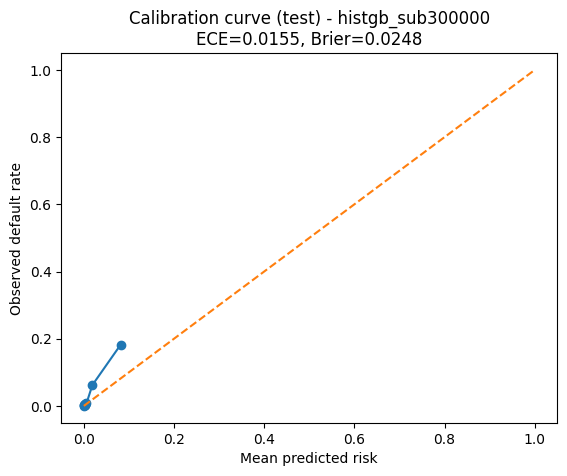

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# -----------------------------
# Helper: ECE (Expected Calibration Error)
# -----------------------------
def expected_calibration_error(y_true, p, n_bins=10, strategy="quantile"):
    frac_pos, mean_pred = calibration_curve(y_true, p, n_bins=n_bins, strategy=strategy)
    # bin weights (quantile bins are ~equal size, but calibration_curve doesn't return counts)
    # approximate by recomputing bin membership:
    p = np.asarray(p)
    y_true = np.asarray(y_true)

    if strategy == "quantile":
        qs = np.quantile(p, np.linspace(0, 1, n_bins + 1))
        # make last edge inclusive
        qs[-1] = np.nextafter(qs[-1], np.inf)
        bin_ids = np.digitize(p, qs[1:-1], right=False)
    else:
        edges = np.linspace(0.0, 1.0, n_bins + 1)
        edges[-1] = np.nextafter(edges[-1], np.inf)
        bin_ids = np.digitize(p, edges[1:-1], right=False)

    ece = 0.0
    n = len(p)
    for b in range(n_bins):
        m = (bin_ids == b)
        if not np.any(m):
            continue
        w = np.sum(m) / n
        ece += w * abs(np.mean(y_true[m]) - np.mean(p[m]))
    return ece, (frac_pos, mean_pred)

# -----------------------------
# Choose best model from results_df
# -----------------------------
best_name = results_df.iloc[0]["model"]

# IMPORTANT:
# - logreg_l2 and sgd_logloss use one-hot matrices: Xtr_oh, Xt_oh
# - histgb_sub300000 uses ordinal matrices: Xtr_ord, Xt_ord and the fitted estimator "histgb"
#   (not in models dict)

n_bins = 10
strategy = "quantile"

if "histgb" in best_name:
    # Use the fitted histgb estimator and ordinal test matrix
    # If you want to refit consistently, refit on same subsample strategy you used before.
    # Otherwise, comment the refit lines and use the already-trained histgb.
    # --- optional refit (consistent with training) ---
    # idx = sample_idx(Xtr_ord.shape[0], 300_000, seed=42)
    # histgb.fit(Xtr_ord[idx], y_train[idx])

    p_test = histgb.predict_proba(Xt_ord)[:, 1]

elif best_name in ("logreg_l2", "sgd_logloss"):
    # If you saved fitted estimators (recommended), use them.
    # Otherwise, refit quickly here:
    if best_name == "logreg_l2":
        logreg.fit(Xtr_oh, y_train)
        p_test = logreg.predict_proba(Xt_oh)[:, 1]
    else:
        sgd.fit(Xtr_oh, y_train)  # only if you have sgd defined; see note below
        p_test = sgd.predict_proba(Xt_oh)[:, 1]
else:
    raise ValueError(f"Unknown best model name: {best_name}. Check results_df['model'].")

# -----------------------------
# Calibration + plot
# -----------------------------
ece, (frac_pos, mean_pred) = expected_calibration_error(y_test, p_test, n_bins=n_bins, strategy=strategy)
brier = brier_score_loss(y_test, p_test)

plt.figure()
plt.plot(mean_pred, frac_pos, marker="o")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Mean predicted risk")
plt.ylabel("Observed default rate")
plt.title(f"Calibration curve (test) - {best_name}\nECE={ece:.4f}, Brier={brier:.4f}")
plt.show()

#Bias measurement framework

In [3]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    log_loss, brier_score_loss,
    confusion_matrix
)

# -----------------------------
# A) Helpers
# -----------------------------
def expected_calibration_error(y_true, p, n_bins=10):
    """
    Simple ECE using equal-width bins in [0,1].
    Returns NaN if too few samples.
    """
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)

    if len(y_true) < 50:
        return np.nan

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(p, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for b in range(n_bins):
        idx = (bin_ids == b)
        if not np.any(idx):
            continue
        conf = p[idx].mean()
        acc = y_true[idx].mean()
        w = idx.mean()
        ece += w * abs(acc - conf)
    return float(ece)

def safe_auc(y, p):
    # AUC is undefined if only one class present in y
    if len(np.unique(y)) < 2:
        return np.nan
    return roc_auc_score(y, p)

def safe_ap(y, p):
    if len(np.unique(y)) < 2:
        return np.nan
    return average_precision_score(y, p)

def rates_at_threshold(y_true, p, thr=0.5):
    """
    Computes threshold-dependent error rates.
    """
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    y_hat = (p >= thr).astype(int)

    # If only one class present, confusion_matrix can still work if labels fixed
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=[0, 1]).ravel()

    n = len(y_true)
    sel = (y_hat == 1).mean()  # selection/flagging rate

    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan
    prec = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    return dict(
        n=n,
        selection_rate=sel,
        tpr=tpr,
        fpr=fpr,
        fnr=fnr,
        precision=prec
    )

def pack_metrics(y, p, thr=0.5, ece_bins=10):
    """
    Discrimination + calibration + threshold metrics.
    """
    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)

    out = {
        "n": len(y),
        "pos_rate": float(y.mean()),
        "auc": safe_auc(y, p),
        "ap": safe_ap(y, p),
        "logloss": log_loss(y, p, labels=[0, 1]),
        "brier": brier_score_loss(y, p),
        "ece": expected_calibration_error(y, p, n_bins=ece_bins),
    }
    out.update(rates_at_threshold(y, p, thr=thr))
    return out

# -----------------------------
# B) Bias report core
# -----------------------------
def bias_report(
    df_meta: pd.DataFrame,
    y_true: np.ndarray,
    p_pred: np.ndarray,
    group_cols,
    stress_col="stress",
    thr=0.5,
    min_group_n=500,
    ece_bins=10,
):
    """
    df_meta: dataframe aligned row-for-row with y_true and p_pred
             should contain group columns + stress indicator.
    group_cols: list of columns to audit (categorical preferred)
    Returns:
      - long table of group metrics
      - summary table of worst-group gaps per (group_col, stress)
    """
    assert len(df_meta) == len(y_true) == len(p_pred), "Alignment mismatch."

    # Ensure stress column exists (if not, treat everything as 'all')
    if stress_col not in df_meta.columns:
        df_meta = df_meta.copy()
        df_meta[stress_col] = "all"

    rows = []
    for gcol in group_cols:
        if gcol not in df_meta.columns:
            continue

        # make sure groups are not crazy high-cardinality (optional protection)
        # If too many uniques, you can bin/quantile outside this function.
        for stress_val, df_s in df_meta.groupby(stress_col):
            idx_s = df_s.index.to_numpy()

            # overall (within stress slice) baseline row
            base = pack_metrics(y_true[idx_s], p_pred[idx_s], thr=thr, ece_bins=ece_bins)
            rows.append({
                "group_col": gcol,
                "stress": stress_val,
                "group": "__ALL__",
                **base
            })

            # group rows
            for grp, df_g in df_s.groupby(gcol):
                idx = df_g.index.to_numpy()
                if len(idx) < min_group_n:
                    continue
                m = pack_metrics(y_true[idx], p_pred[idx], thr=thr, ece_bins=ece_bins)
                rows.append({
                    "group_col": gcol,
                    "stress": stress_val,
                    "group": grp,
                    **m
                })

    long_df = pd.DataFrame(rows)

    # gap summaries: compare each group to best/worst within same (group_col, stress)
    # Exclude "__ALL__" from gap computation
    gap_rows = []
    for (gcol, stress_val), sub in long_df[long_df["group"] != "__ALL__"].groupby(["group_col", "stress"]):
        if sub.empty:
            continue

        def gap(metric):
            v = sub[metric].astype(float)
            return float(np.nanmax(v) - np.nanmin(v))

        # worst group by AUC (min auc) and by ECE (max ece), Brier (max brier)
        worst_auc = sub.loc[sub["auc"].astype(float).idxmin()] if sub["auc"].notna().any() else None
        worst_ece = sub.loc[sub["ece"].astype(float).idxmax()] if sub["ece"].notna().any() else None
        worst_brier = sub.loc[sub["brier"].astype(float).idxmax()] if sub["brier"].notna().any() else None

        gap_rows.append({
            "group_col": gcol,
            "stress": stress_val,
            "n_groups": int(sub["group"].nunique()),
            "auc_gap": gap("auc"),
            "ap_gap": gap("ap"),
            "brier_gap": gap("brier"),
            "ece_gap": gap("ece"),
            "selection_gap": gap("selection_rate"),
            "tpr_gap": gap("tpr"),
            "fpr_gap": gap("fpr"),
            "worst_auc_group": None if worst_auc is None else worst_auc["group"],
            "worst_auc": None if worst_auc is None else float(worst_auc["auc"]),
            "worst_ece_group": None if worst_ece is None else worst_ece["group"],
            "worst_ece": None if worst_ece is None else float(worst_ece["ece"]),
            "worst_brier_group": None if worst_brier is None else worst_brier["group"],
            "worst_brier": None if worst_brier is None else float(worst_brier["brier"]),
        })

    gap_df = pd.DataFrame(gap_rows).sort_values(["stress", "auc_gap"], ascending=[True, False])

    return long_df, gap_df

In [4]:
# df_meta must align with y_test and p_te row order.
# Since you created X_test, y_test from test_df in order, you can use:
df_meta_test = test_df.reset_index(drop=True)

# If you have a stress indicator column already, set it here.
# If not, create it from unemployment threshold (example uses column "unemployment").
if "stress" not in df_meta_test.columns:
    if "unemployment" in df_meta_test.columns:
        thr_u = final_df["unemployment"].quantile(0.75)
        df_meta_test["stress"] = (df_meta_test["unemployment"] > thr_u).astype(int)
    else:
        # fallback: everything treated as one regime
        df_meta_test["stress"] = "all"

In [5]:
group_cols = [
    "grade",
    "sub_grade",
    "home_ownership",
    "verification_status",
    "purpose",
    "term",
    "region",   # if exists
    "state",    # if exists
]

# keep only columns that exist
group_cols = [c for c in group_cols if c in df_meta_test.columns]
print("Auditing group columns:", group_cols)

Auditing group columns: ['grade', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'term', 'region', 'state']


In [6]:
# p_te must be length == len(y_test)
# If you used your baseline training script: p_te is already computed.

long_df, gap_df = bias_report(
    df_meta=df_meta_test,
    y_true=y_test,
    p_pred=p_te,            # <-- use the model you want to audit
    group_cols=group_cols,
    stress_col="stress",    # 0/1 or labels
    thr=0.20,               # choose an operating threshold (example 0.20)
    min_group_n=1000,
    ece_bins=10
)

display(gap_df.head(25))

/tmp/ipython-input-3988314646.py:145: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for grp, df_g in df_s.groupby(gcol):
/tmp/ipython-input-3988314646.py:145: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for grp, df_g in df_s.groupby(gcol):


,group_col,stress,n_groups,auc_gap,ap_gap,brier_gap,ece_gap,selection_gap,tpr_gap,fpr_gap,worst_auc_group,worst_auc,worst_ece_group,worst_ece,worst_brier_group,worst_brier
8,state,0,43,0.143673,0.190528,0.024267,0.021972,0.008610,0.134021,0.006776,LA,0.802774,NV,0.024862,NV,0.037242
4,purpose,0,11,0.056257,0.106573,0.019030,0.016344,0.017690,0.085366,0.014404,house,0.849070,moving,0.028467,moving,0.038520
10,sub_grade,0,20,0.051115,0.237013,0.065799,0.056962,0.037839,0.146479,0.029431,D5,0.843949,D4,0.061285,D4,0.073064
2,home_ownership,0,4,0.030433,0.167596,0.023028,0.022906,0.000614,0.022872,0.002166,ANY,0.866129,ANY,0.034256,ANY,0.044083
0,grade,0,4,0.023029,0.165164,0.039758,0.025397,0.014238,0.076835,0.010405,D,0.863195,D,0.031423,D,0.049565
6,region,0,4,0.022080,0.035376,0.002803,0.002515,0.001138,0.020087,0.000866,West,0.884346,Northeast,0.015702,South,0.025494
12,term,0,2,0.009301,0.010525,0.002285,0.012840,0.010343,0.112187,0.007566,36 months,0.899476,36 months,0.018742,36 months,0.024973
14,verification_status,0,3,0.008662,0.065534,0.010280,0.006151,0.005082,0.048776,0.003044,Verified,0.886409,Verified,0.019206,Verified,0.032148
11,sub_grade,1,20,0.092022,0.315483,0.073829,0.068294,0.033654,0.194245,0.016705,B1,0.850092,D4,0.072644,D4,0.080430
1,grade,1,4,0.036679,0.198240,0.044757,0.035564,0.013347,0.084954,0.008331,D,0.884245,D,0.043791,D,0.056032


In [7]:
# keep a compact table for the paper
latex_cols = [
    "group_col", "stress", "n_groups",
    "auc_gap", "ap_gap", "brier_gap", "ece_gap",
    "selection_gap", "tpr_gap", "fpr_gap",
    "worst_auc_group", "worst_auc",
]

tab = gap_df[latex_cols].copy()

# nice formatting
for c in ["auc_gap","ap_gap","brier_gap","ece_gap","selection_gap","tpr_gap","fpr_gap","worst_auc"]:
    tab[c] = tab[c].astype(float).round(4)

latex_str = tab.to_latex(index=False, escape=True)
print(latex_str)

\begin{tabular}{lrrrrrrrrrlr}
\toprule
group\_col & stress & n\_groups & auc\_gap & ap\_gap & brier\_gap & ece\_gap & selection\_gap & tpr\_gap & fpr\_gap & worst\_auc\_group & worst\_auc \\
\midrule
state & 0 & 43 & 0.143700 & 0.190500 & 0.024300 & 0.022000 & 0.008600 & 0.134000 & 0.006800 & LA & 0.802800 \\
purpose & 0 & 11 & 0.056300 & 0.106600 & 0.019000 & 0.016300 & 0.017700 & 0.085400 & 0.014400 & house & 0.849100 \\
sub\_grade & 0 & 20 & 0.051100 & 0.237000 & 0.065800 & 0.057000 & 0.037800 & 0.146500 & 0.029400 & D5 & 0.843900 \\
home\_ownership & 0 & 4 & 0.030400 & 0.167600 & 0.023000 & 0.022900 & 0.000600 & 0.022900 & 0.002200 & ANY & 0.866100 \\
grade & 0 & 4 & 0.023000 & 0.165200 & 0.039800 & 0.025400 & 0.014200 & 0.076800 & 0.010400 & D & 0.863200 \\
region & 0 & 4 & 0.022100 & 0.035400 & 0.002800 & 0.002500 & 0.001100 & 0.020100 & 0.000900 & West & 0.884300 \\
term & 0 & 2 & 0.009300 & 0.010500 & 0.002300 & 0.012800 & 0.010300 & 0.112200 & 0.007600 &  36 months & 0.899500 

# Uncertainty quantification analysis

                    regime         n  pos_rate  log_loss   brier     ece
0               Non-stress  396555.0    0.0273    0.0981  0.0246  0.0157
1                   Stress   40598.0    0.0287    0.1062  0.0262  0.0145
2  Δ (Stress − Non-stress)       NaN       NaN    0.0081  0.0015 -0.0013


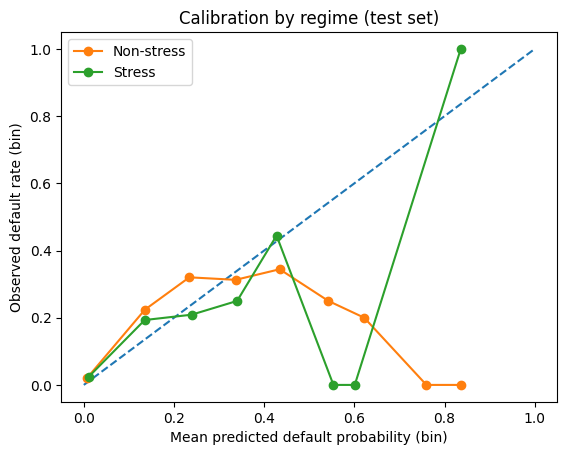

\begin{tabular}{lrrrrr}
\toprule
regime & n & pos\_rate & log\_loss & brier & ece \\
\midrule
Non-stress & 396555.000000 & 0.027300 & 0.098100 & 0.024600 & 0.015700 \\
Stress & 40598.000000 & 0.028700 & 0.106200 & 0.026200 & 0.014500 \\
Δ (Stress − Non-stress) & NaN & NaN & 0.008100 & 0.001500 & -0.001300 \\
\bottomrule
\end{tabular}



In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import log_loss, brier_score_loss

# -----------------------------
# 0) Inputs you MUST already have
# -----------------------------
# y_test: array-like (0/1)
# p_te:   array-like probabilities in [0,1]
# test_df: DataFrame aligned row-for-row with y_test and p_te

y_test = np.asarray(y_test).astype(int)
p_te = np.asarray(p_te).astype(float)

assert len(y_test) == len(p_te), "y_test and p_te length mismatch."
assert len(test_df) == len(y_test), "test_df and y_test are not aligned."

# -----------------------------
# 1) ECE helper (same as before)
# -----------------------------
def expected_calibration_error(y_true, p, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)

    if len(y_true) < 50:
        return np.nan

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(p, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    ece = 0.0
    for b in range(n_bins):
        idx = (bin_ids == b)
        if not np.any(idx):
            continue
        conf = p[idx].mean()
        acc = y_true[idx].mean()
        w = idx.mean()
        ece += w * abs(acc - conf)
    return float(ece)

# -----------------------------
# 2) Pick stress column (or create it)
# -----------------------------
df_meta = test_df.reset_index(drop=True).copy()

if "stress" in df_meta.columns:
    stress_col = "stress"
elif "stress_regime" in df_meta.columns:
    stress_col = "stress_regime"
else:
    # Fallback creation using unemployment (only if you really need it)
    # NOTE: ideally you already have stress defined in your manuscript pipeline
    if "unemployment" in df_meta.columns:
        thr_u = df_meta["unemployment"].quantile(0.75)
        df_meta["stress"] = (df_meta["unemployment"] > thr_u).astype(int)
        stress_col = "stress"
    elif "unem_rate" in df_meta.columns:
        thr_u = df_meta["unem_rate"].quantile(0.75)
        df_meta["stress"] = (df_meta["unem_rate"] > thr_u).astype(int)
        stress_col = "stress"
    else:
        raise ValueError("No stress column found (stress / stress_regime) and no unemployment proxy to build it.")

# ensure 0/1
df_meta[stress_col] = pd.to_numeric(df_meta[stress_col], errors="coerce").astype(int)

# -----------------------------
# 3) Compute metrics by regime
# -----------------------------
def regime_metrics(y, p, n_bins=10):
    return {
        "n": int(len(y)),
        "pos_rate": float(np.mean(y)),
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
        "brier": float(brier_score_loss(y, p)),
        "ece": float(expected_calibration_error(y, p, n_bins=n_bins)),
    }

rows = []
for s in [0, 1]:
    idx = (df_meta[stress_col].values == s)
    y_s = y_test[idx]
    p_s = p_te[idx]
    m = regime_metrics(y_s, p_s, n_bins=10)
    rows.append({
        "regime": "Non-stress" if s == 0 else "Stress",
        **m
    })

uncertainty_tbl = pd.DataFrame(rows)

# Add deltas (Stress - Non-stress)
if len(uncertainty_tbl) == 2:
    delta = (uncertainty_tbl.loc[uncertainty_tbl["regime"] == "Stress", ["log_loss","brier","ece"]].values -
             uncertainty_tbl.loc[uncertainty_tbl["regime"] == "Non-stress", ["log_loss","brier","ece"]].values)[0]
    delta_row = {
        "regime": "Δ (Stress − Non-stress)",
        "n": np.nan,
        "pos_rate": np.nan,
        "log_loss": float(delta[0]),
        "brier": float(delta[1]),
        "ece": float(delta[2]),
    }
    uncertainty_tbl = pd.concat([uncertainty_tbl, pd.DataFrame([delta_row])], ignore_index=True)

# Round for display
uncertainty_tbl_display = uncertainty_tbl.copy()
for c in ["pos_rate", "log_loss", "brier", "ece"]:
    uncertainty_tbl_display[c] = pd.to_numeric(uncertainty_tbl_display[c], errors="coerce").round(4)

print(uncertainty_tbl_display)

# -----------------------------
# 4) Calibration curve plot: stress vs non-stress (same figure)
# -----------------------------
def calibration_points(y_true, p, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(p, bins) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    xs, ys = [], []
    for b in range(n_bins):
        idx = (bin_ids == b)
        if not np.any(idx):
            continue
        xs.append(float(np.mean(p[idx])))
        ys.append(float(np.mean(y_true[idx])))
    return np.array(xs), np.array(ys)

fig = plt.figure()
ax = plt.gca()

# Diagonal (perfect calibration)
ax.plot([0, 1], [0, 1], linestyle="--")

# Non-stress
idx0 = (df_meta[stress_col].values == 0)
x0, y0 = calibration_points(y_test[idx0], p_te[idx0], n_bins=10)
ax.plot(x0, y0, marker="o", label="Non-stress")

# Stress
idx1 = (df_meta[stress_col].values == 1)
x1, y1 = calibration_points(y_test[idx1], p_te[idx1], n_bins=10)
ax.plot(x1, y1, marker="o", label="Stress")

ax.set_xlabel("Mean predicted default probability (bin)")
ax.set_ylabel("Observed default rate (bin)")
ax.set_title("Calibration by regime (test set)")
ax.legend()
plt.show()

# -----------------------------
# 5) LaTeX table for Results section
# -----------------------------
latex_tbl = uncertainty_tbl_display.copy()
latex_tbl.rename(columns={
    "pos_rate": "pos\\_rate",
    "log_loss": "log\\_loss"
}, inplace=True)

latex_str = latex_tbl.to_latex(index=False, escape=False)
print(latex_str)

In [9]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# -----------------------------
# A) Core safety metrics @ threshold
# -----------------------------
def safety_rates(y_true, p_pred, thr=0.20):
    """
    Returns selection rate, TPR, FPR, FNR, precision, counts.
    """
    y_true = np.asarray(y_true).astype(int)
    p_pred = np.asarray(p_pred).astype(float)
    y_hat = (p_pred >= thr).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=[0, 1]).ravel()
    n = len(y_true)

    sel = (y_hat == 1).mean()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan
    prec = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    return {
        "n": n,
        "pos_rate": float(y_true.mean()),
        "threshold": float(thr),
        "selection_rate": float(sel),
        "TPR": float(tpr) if not np.isnan(tpr) else np.nan,
        "FPR": float(fpr) if not np.isnan(fpr) else np.nan,
        "FNR": float(fnr) if not np.isnan(fnr) else np.nan,
        "precision": float(prec) if not np.isnan(prec) else np.nan,
        "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
    }

# -----------------------------
# B) Regime-wise safety report
# -----------------------------
def safety_by_regime(df_meta, y_true, p_pred, stress_col="stress", thr_list=(0.20,)):
    """
    Returns a tidy table of safety metrics by regime and threshold.
    """
    assert len(df_meta) == len(y_true) == len(p_pred), "Alignment mismatch."
    if stress_col not in df_meta.columns:
        raise ValueError(f"Missing '{stress_col}' in df_meta.")

    rows = []
    for thr in thr_list:
        for s_val, df_s in df_meta.groupby(stress_col, observed=False):
            idx = df_s.index.to_numpy()
            out = safety_rates(y_true[idx], p_pred[idx], thr=thr)
            out["regime"] = "Stress" if int(s_val) == 1 else "Non-stress"
            rows.append(out)

        # add delta row (Stress - Non-stress) for each metric
        sub = pd.DataFrame(rows)
        sub_thr = sub[sub["threshold"] == float(thr)].copy()
        if set(sub_thr["regime"]) >= {"Stress", "Non-stress"}:
            a = sub_thr[sub_thr["regime"] == "Stress"].iloc[0]
            b = sub_thr[sub_thr["regime"] == "Non-stress"].iloc[0]
            delta = {
                "regime": r"$\Delta$ (Stress $-$ Non-stress)",
                "threshold": float(thr),
                "n": np.nan,
                "pos_rate": np.nan,
                "selection_rate": a["selection_rate"] - b["selection_rate"],
                "TPR": a["TPR"] - b["TPR"],
                "FPR": a["FPR"] - b["FPR"],
                "FNR": a["FNR"] - b["FNR"],
                "precision": a["precision"] - b["precision"],
                "tp": np.nan, "fp": np.nan, "tn": np.nan, "fn": np.nan,
            }
            rows.append(delta)

    out_df = pd.DataFrame(rows)
    # nice ordering
    out_df = out_df[[
        "regime", "threshold", "n", "pos_rate",
        "selection_rate", "TPR", "FPR", "FNR", "precision",
        "tp", "fp", "tn", "fn"
    ]]
    return out_df

# -----------------------------
# C) Worst-slice safety under stress: max FNR subgroup
# -----------------------------
def worst_slice_fnr_under_stress(
    df_meta,
    y_true,
    p_pred,
    group_cols,
    stress_col="stress",
    thr=0.20,
    min_group_n=1000
):
    """
    Finds subgroup (within stress regime) with highest FNR (missed defaults).
    Returns a table sorted by FNR desc.
    """
    assert len(df_meta) == len(y_true) == len(p_pred), "Alignment mismatch."
    df_meta = df_meta.copy()

    if stress_col not in df_meta.columns:
        raise ValueError(f"Missing '{stress_col}' in df_meta.")

    # stress slice only
    df_s = df_meta[df_meta[stress_col] == 1]
    idx_s = df_s.index.to_numpy()

    rows = []
    for gcol in group_cols:
        if gcol not in df_s.columns:
            continue

        for grp, df_g in df_s.groupby(gcol, observed=False):
            idx = df_g.index.to_numpy()
            if len(idx) < min_group_n:
                continue

            m = safety_rates(y_true[idx], p_pred[idx], thr=thr)
            rows.append({
                "group_col": gcol,
                "group": grp,
                "n": m["n"],
                "pos_rate": m["pos_rate"],
                "threshold": m["threshold"],
                "selection_rate": m["selection_rate"],
                "TPR": m["TPR"],
                "FPR": m["FPR"],
                "FNR": m["FNR"],
                "tp": m["tp"], "fp": m["fp"], "tn": m["tn"], "fn": m["fn"],
            })

    worst_df = pd.DataFrame(rows)
    if worst_df.empty:
        return worst_df

    worst_df = worst_df.sort_values(["FNR", "n"], ascending=[False, False]).reset_index(drop=True)
    return worst_df

# =============================
# RUN (you can paste this block)
# =============================

# --- You already have df_meta_test, y_test, p_te ---
# Ensure stress is 0/1:
# df_meta_test["stress"] = df_meta_test["stress"].astype(int)

# Choose the same threshold you used earlier
thr_main = 0.20

# Optional stability thresholds
thr_list = (0.10, 0.20, 0.30)

# 1) Regime-wise safety table
safety_tbl = safety_by_regime(
    df_meta=df_meta_test,
    y_true=y_test,
    p_pred=p_te,
    stress_col="stress",
    thr_list=thr_list
)

# Display compact view (main threshold only)
print("Safety metrics by regime @ threshold =", thr_main)
display(safety_tbl[safety_tbl["threshold"] == thr_main].copy())

# 2) Worst-slice FNR under stress (failure mode: missed defaults)
group_cols = [
    "grade", "sub_grade", "home_ownership", "verification_status",
    "purpose", "term", "region", "state"
]
group_cols = [c for c in group_cols if c in df_meta_test.columns]

worst_fnr_tbl = worst_slice_fnr_under_stress(
    df_meta=df_meta_test,
    y_true=y_test,
    p_pred=p_te,
    group_cols=group_cols,
    stress_col="stress",
    thr=thr_main,
    min_group_n=1000
)

print("Worst-slice (stress regime) by highest FNR @ thr =", thr_main)
display(worst_fnr_tbl.head(15))

# -----------------------------
# D) LaTeX outputs (paste into paper)
# -----------------------------

# Safety by regime (stability across thresholds)
latex_safety = safety_tbl.copy()
for c in ["pos_rate","selection_rate","TPR","FPR","FNR","precision"]:
    latex_safety[c] = pd.to_numeric(latex_safety[c], errors="coerce").round(4)

# Keep the columns you likely want in Results
latex_safety = latex_safety[[
    "threshold","regime","n","pos_rate","selection_rate","TPR","FPR","FNR","precision"
]]

print("\nLaTeX: Safety metrics by regime (stability table)")
print(latex_safety.to_latex(index=False, escape=False))

# Worst-slice failure mode table (top 10)
if not worst_fnr_tbl.empty:
    top10 = worst_fnr_tbl.head(10).copy()
    for c in ["pos_rate","selection_rate","TPR","FPR","FNR"]:
        top10[c] = pd.to_numeric(top10[c], errors="coerce").round(4)

    top10 = top10[[
        "group_col","group","n","pos_rate","selection_rate","TPR","FPR","FNR"
    ]]

    print("\nLaTeX: Worst-slice (stress) by highest FNR")
    print(top10.to_latex(index=False, escape=True))
else:
    print("\nNo worst-slice table produced (likely due to min_group_n too high or missing group columns).")

Safety metrics by regime @ threshold = 0.2


,regime,threshold,n,pos_rate,selection_rate,TPR,FPR,FNR,precision,tp,fp,tn,fn
3,Non-stress,0.2,340935.0,0.026747,0.003763,0.041123,0.002736,0.958877,0.292284,375.0,908.0,330908.0,8744.0
4,Stress,0.2,96218.0,0.029994,0.003679,0.045045,0.002400,0.954955,0.367232,130.0,224.0,93108.0,2756.0
5,$\Delta$ (Stress $-$ Non-stress),0.2,NaN,NaN,-0.000084,0.003922,-0.000336,-0.003922,0.074948,NaN,NaN,NaN,NaN


Worst-slice (stress regime) by highest FNR @ thr = 0.2


,group_col,group,n,pos_rate,threshold,selection_rate,TPR,FPR,FNR,tp,fp,tn,fn
0,grade,A,31206,0.011729,0.2,0.000064,0.000000,0.000065,1.000000,0,2,30838,366
1,sub_grade,A4,8938,0.013202,0.2,0.000112,0.000000,0.000113,1.000000,0,1,8819,118
2,sub_grade,A1,6780,0.006785,0.2,0.000147,0.000000,0.000149,1.000000,0,1,6733,46
3,sub_grade,A5,6399,0.014377,0.2,0.000000,0.000000,0.000000,1.000000,0,0,6307,92
4,sub_grade,B1,5544,0.018218,0.2,0.000361,0.000000,0.000367,1.000000,0,2,5441,101
5,sub_grade,A2,4667,0.011142,0.2,0.000000,0.000000,0.000000,1.000000,0,0,4615,52
6,sub_grade,A3,4422,0.013116,0.2,0.000000,0.000000,0.000000,1.000000,0,0,4364,58
7,sub_grade,B3,4415,0.023783,0.2,0.001359,0.000000,0.001392,1.000000,0,6,4304,105
8,term,36 months,66831,0.029462,0.2,0.000389,0.005587,0.000231,0.994413,11,15,64847,1958
9,grade,B,27665,0.022953,0.2,0.001374,0.011024,0.001147,0.988976,7,31,26999,628



LaTeX: Safety metrics by regime (stability table)
\begin{tabular}{rlrrrrrrr}
\toprule
threshold & regime & n & pos_rate & selection_rate & TPR & FPR & FNR & precision \\
\midrule
0.100000 & Non-stress & 340935.000000 & 0.026700 & 0.026200 & 0.218000 & 0.020900 & 0.782000 & 0.222700 \\
0.100000 & Stress & 96218.000000 & 0.030000 & 0.022800 & 0.212100 & 0.016900 & 0.787900 & 0.279500 \\
0.100000 & $\Delta$ (Stress $-$ Non-stress) & NaN & NaN & -0.003400 & -0.005900 & -0.004000 & 0.005900 & 0.056700 \\
0.200000 & Non-stress & 340935.000000 & 0.026700 & 0.003800 & 0.041100 & 0.002700 & 0.958900 & 0.292300 \\
0.200000 & Stress & 96218.000000 & 0.030000 & 0.003700 & 0.045000 & 0.002400 & 0.955000 & 0.367200 \\
0.200000 & $\Delta$ (Stress $-$ Non-stress) & NaN & NaN & -0.000100 & 0.003900 & -0.000300 & -0.003900 & 0.074900 \\
0.300000 & Non-stress & 340935.000000 & 0.026700 & 0.000800 & 0.009200 & 0.000600 & 0.990800 & 0.293700 \\
0.300000 & Stress & 96218.000000 & 0.030000 & 0.000700 & 0.00

In [10]:
# ===============================
# Inspect environment contents
# ===============================

import os

def tree(path="/content", level=2):
    for root, dirs, files in os.walk(path):
        depth = root.replace(path, "").count(os.sep)
        if depth > level:
            continue
        indent = "  " * depth
        print(f"{indent}{os.path.basename(root)}/")
        for f in files:
            print(f"{indent}  {f}")

print("=== /content directory ===")
tree("/content", level=3)

=== /content directory ===
content/
  wb3ndt69gf-3.zip
  final_modelling_frame.parquet
  final_modelling_frame_with_split.parquet
  .config/
    config_sentinel
    active_config
    default_configs.db
    gce
    .last_survey_prompt.yaml
    .last_opt_in_prompt.yaml
    hidden_gcloud_config_universe_descriptor_data_cache_configs.db
    .last_update_check.json
    configurations/
      config_default
    logs/
      2025.12.09/
        14.41.18.717681.log
        14.41.42.675750.log
        14.40.47.605300.log
        14.41.33.792924.log
        14.41.27.893750.log
        14.41.43.412452.log
  wb3ndt69gf-3_extracted/
    P2P_Macro_Data.zip
    Labels.do
    P2P_Macro_Codes.do
    P2P_Macro_Data.dta
  sample_data/
    anscombe.json
    README.md
    mnist_train_small.csv
    california_housing_test.csv
    california_housing_train.csv
    mnist_test.csv


In [11]:
# ============================================================
# P2P LENDING MODEL - COLAB NOTEBOOK VERSION
# Copy each cell section separately into Colab
# ============================================================

# ============================================================
# CELL 1: Install dependencies & setup
# ============================================================

# !pip install -q psutil  # For memory monitoring

import gc
import warnings
import numpy as np
import pandas as pd
import time

warnings.filterwarnings('ignore')

def clear_memory():
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except:
        pass

def log_memory(msg=""):
    try:
        import psutil
        mem = psutil.Process().memory_info().rss / 1024**2
        print(f"[MEM] {msg}: {mem:.0f} MB")
    except:
        pass

print("Setup complete!")


# ============================================================
# CELL 2: Load data and detect features
# ============================================================

from pandas.api.types import is_datetime64_any_dtype, is_object_dtype
from pandas import CategoricalDtype

# Load data
print("Loading data...")
df = pd.read_parquet("/content/final_modelling_frame_with_split.parquet")
log_memory("After load")

TARGET_COL = "badloan"
TIME_COL = "issue_date"
STRESS_COL = "stress_regime"

# Convert stress_regime
df[STRESS_COL] = pd.to_numeric(df[STRESS_COL], errors="coerce").fillna(0).astype(np.int8)

# Define columns to exclude
AUDIT_COLS = ["grade", "sub_grade", "purpose", "state", "term", "region", "verification_status"]
AUDIT_COLS = [c for c in AUDIT_COLS if c in df.columns]
META_COLS = [TIME_COL, STRESS_COL] + AUDIT_COLS
exclude = set([TARGET_COL, TIME_COL, STRESS_COL, "split"]) | set(META_COLS)

# Feature detection
feature_cols = [c for c in df.columns if c not in exclude]
datetime_cols = [c for c in feature_cols if is_datetime64_any_dtype(df[c])]
feature_cols = [c for c in feature_cols if c not in datetime_cols]

FEATURES_CATEGORICAL = [
    c for c in feature_cols
    if is_object_dtype(df[c]) or isinstance(df[c].dtype, CategoricalDtype)
]
FEATURES_NUMERIC = [c for c in feature_cols if c not in FEATURES_CATEGORICAL]

print(f"Numeric features: {len(FEATURES_NUMERIC)}")
print(f"Categorical features: {len(FEATURES_CATEGORICAL)}")

# Downcast to save memory
print("Downcasting...")
for c in FEATURES_NUMERIC:
    df[c] = pd.to_numeric(df[c], errors="coerce", downcast="float")
df[TARGET_COL] = df[TARGET_COL].astype(np.int8)

clear_memory()
log_memory("After feature detection")


# ============================================================
# CELL 3: Create splits (using masks, not copies!)
# ============================================================

train_mask = df["split"] == "train"
val_mask = df["split"] == "val"
test_mask = df["split"] == "test"

print(f"Train: {train_mask.sum():,}")
print(f"Val:   {val_mask.sum():,}")
print(f"Test:  {test_mask.sum():,}")


# ============================================================
# CELL 4: Memory-efficient preprocessing
# ============================================================

from sklearn.preprocessing import StandardScaler, LabelEncoder

t0 = time.time()
log_memory("Start preprocessing")

# Config
SVD_DIM = 256  # Reduce to 128 if still OOM
MAX_CATEGORIES = 50  # Limit cardinality per categorical

# ---- Extract targets ----
y_train = df.loc[train_mask, TARGET_COL].values.astype(np.int8)
y_val = df.loc[val_mask, TARGET_COL].values.astype(np.int8)
y_test = df.loc[test_mask, TARGET_COL].values.astype(np.int8)

print(f"Positive rates: train={y_train.mean():.4f}, val={y_val.mean():.4f}, test={y_test.mean():.4f}")

# ---- Process NUMERIC features ----
print("\nProcessing numeric features...")
X_train_num = df.loc[train_mask, FEATURES_NUMERIC].values.astype(np.float32)
X_val_num = df.loc[val_mask, FEATURES_NUMERIC].values.astype(np.float32)
X_test_num = df.loc[test_mask, FEATURES_NUMERIC].values.astype(np.float32)

# Fill NaN with column means
col_means = np.nanmean(X_train_num, axis=0)
col_means = np.nan_to_num(col_means, nan=0.0)
for i in range(X_train_num.shape[1]):
    X_train_num[np.isnan(X_train_num[:, i]), i] = col_means[i]
    X_val_num[np.isnan(X_val_num[:, i]), i] = col_means[i]
    X_test_num[np.isnan(X_test_num[:, i]), i] = col_means[i]

# Scale
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num).astype(np.float32)
X_val_num = scaler.transform(X_val_num).astype(np.float32)
X_test_num = scaler.transform(X_test_num).astype(np.float32)

print(f"Numeric shape: {X_train_num.shape}")
log_memory("After numeric")

# ---- Process CATEGORICAL features (Label Encoding - not One-Hot!) ----
print("\nProcessing categorical features...")
cat_encoded_train = []
cat_encoded_val = []
cat_encoded_test = []

for i, col in enumerate(FEATURES_CATEGORICAL):
    train_vals = df.loc[train_mask, col].astype(str).values
    val_vals = df.loc[val_mask, col].astype(str).values
    test_vals = df.loc[test_mask, col].astype(str).values

    # Limit to top categories
    value_counts = pd.Series(train_vals).value_counts()
    top_cats = set(value_counts.head(MAX_CATEGORIES).index)

    train_vals = np.where(np.isin(train_vals, list(top_cats)), train_vals, "OTHER")
    val_vals = np.where(np.isin(val_vals, list(top_cats)), val_vals, "OTHER")
    test_vals = np.where(np.isin(test_vals, list(top_cats)), test_vals, "OTHER")

    # Label encode
    le = LabelEncoder()
    le.fit(np.concatenate([train_vals, ["OTHER"]]))

    cat_encoded_train.append(le.transform(train_vals).astype(np.int16))

    # Safe transform for val/test
    def safe_transform(vals):
        result = []
        other_code = le.transform(["OTHER"])[0]
        for v in vals:
            try:
                result.append(le.transform([v])[0])
            except:
                result.append(other_code)
        return np.array(result, dtype=np.int16)

    cat_encoded_val.append(safe_transform(val_vals))
    cat_encoded_test.append(safe_transform(test_vals))

    if (i + 1) % 10 == 0:
        print(f"  {i + 1}/{len(FEATURES_CATEGORICAL)} done")

# Stack and scale categorical
if cat_encoded_train:
    X_train_cat = np.column_stack(cat_encoded_train).astype(np.float32)
    X_val_cat = np.column_stack(cat_encoded_val).astype(np.float32)
    X_test_cat = np.column_stack(cat_encoded_test).astype(np.float32)

    cat_scaler = StandardScaler()
    X_train_cat = cat_scaler.fit_transform(X_train_cat).astype(np.float32)
    X_val_cat = cat_scaler.transform(X_val_cat).astype(np.float32)
    X_test_cat = cat_scaler.transform(X_test_cat).astype(np.float32)
else:
    X_train_cat = np.zeros((len(y_train), 0), dtype=np.float32)
    X_val_cat = np.zeros((len(y_val), 0), dtype=np.float32)
    X_test_cat = np.zeros((len(y_test), 0), dtype=np.float32)

del cat_encoded_train, cat_encoded_val, cat_encoded_test
clear_memory()
print(f"Categorical shape: {X_train_cat.shape}")
log_memory("After categorical")

# ---- Combine features ----
print("\nCombining features...")
X_train = np.hstack([X_train_num, X_train_cat]).astype(np.float32)
X_val = np.hstack([X_val_num, X_val_cat]).astype(np.float32)
X_test = np.hstack([X_test_num, X_test_cat]).astype(np.float32)

del X_train_num, X_val_num, X_test_num
del X_train_cat, X_val_cat, X_test_cat
clear_memory()

print(f"Combined shape: {X_train.shape}")
log_memory("After combine")

# ---- SVD compression (only if needed) ----
if X_train.shape[1] > SVD_DIM:
    print(f"\nSVD: {X_train.shape[1]} -> {SVD_DIM} dims...")
    from sklearn.decomposition import TruncatedSVD

    svd = TruncatedSVD(n_components=SVD_DIM, random_state=42, algorithm='randomized')
    X_train = svd.fit_transform(X_train).astype(np.float32)
    X_val = svd.transform(X_val).astype(np.float32)
    X_test = svd.transform(X_test).astype(np.float32)

    print(f"Explained variance: {svd.explained_variance_ratio_.sum():.4f}")

# Free the dataframe!
del df
clear_memory()

print(f"\nFinal shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}")
print(f"Elapsed: {time.time() - t0:.1f}s")
log_memory("Preprocessing complete")


# ============================================================
# CELL 5: Model definitions
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class SimpleMLP(nn.Module):
    def __init__(self, n_features, hidden_dim=128, n_layers=2, dropout=0.3):
        super().__init__()
        layers = []
        in_dim = n_features
        for _ in range(n_layers):
            layers.extend([
                nn.Linear(in_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            in_dim = hidden_dim
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


class ConvNetTabular(nn.Module):
    def __init__(self, n_features, channels=32):
        super().__init__()
        self.conv1 = nn.Conv1d(1, channels, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels * 2, 3, padding=1)
        self.bn2 = nn.BatchNorm1d(channels * 2)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(channels * 2, 1)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = x.mean(dim=-1)
        x = self.dropout(x)
        return self.head(x).squeeze(1)


class GhostModule(nn.Module):
    def __init__(self, in_dim, out_dim, ratio=2):
        super().__init__()
        primary = int(math.ceil(out_dim / ratio))
        cheap = out_dim - primary
        self.p = nn.Linear(in_dim, primary)
        self.c = nn.Linear(primary, cheap) if cheap > 0 else None
        self.bn = nn.BatchNorm1d(out_dim)

    def forward(self, x):
        p = F.relu(self.p(x))
        h = torch.cat([p, F.relu(self.c(p))], dim=1) if self.c else p
        return F.relu(self.bn(h))


class GhostNetTabular(nn.Module):
    def __init__(self, n_features, width=128, depth=2):
        super().__init__()
        self.inp = nn.Linear(n_features, width)
        self.bn_inp = nn.BatchNorm1d(width)
        self.blocks = nn.ModuleList([GhostModule(width, width) for _ in range(depth)])
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(width, 1)

    def forward(self, x):
        x = F.relu(self.bn_inp(self.inp(x)))
        for block in self.blocks:
            x = block(x) + x  # Residual
        x = self.dropout(x)
        return self.head(x).squeeze(1)


print("Models defined!")


# ============================================================
# CELL 6: Training setup
# ============================================================

from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

n_features = X_train.shape[1]
print(f"Features: {n_features}")

# Class weight for imbalanced data
pos_weight = (1 - y_train.mean()) / y_train.mean()
print(f"Positive weight: {pos_weight:.2f}")

# Create dataloaders
BATCH_SIZE = 512

train_ds = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)
test_ds = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0)

# Free numpy arrays
del X_train, X_val, X_test
clear_memory()

print("Dataloaders ready!")


# ============================================================
# CELL 7: Training function
# ============================================================

def train_model(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model = model.to(DEVICE)

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([pos_weight]).to(DEVICE)
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', patience=3, factor=0.5
    )

    best_auc = 0
    best_state = None
    patience = 0

    for epoch in range(epochs):
        # Train
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * len(xb)
        train_loss /= len(train_loader.dataset)

        # Validate
        model.eval()
        preds, targets = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                preds.extend(torch.sigmoid(model(xb)).cpu().numpy())
                targets.extend(yb.numpy())

        val_auc = roc_auc_score(targets, preds)
        scheduler.step(val_auc)

        print(f"Epoch {epoch+1:2d} | Loss: {train_loss:.4f} | Val AUC: {val_auc:.4f}")

        if val_auc > best_auc:
            best_auc = val_auc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1
            if patience >= 5:
                print("Early stopping!")
                break

    if best_state:
        model.load_state_dict(best_state)

    return model, best_auc


# ============================================================
# CELL 8: Train all models
# ============================================================

results = {}

# SimpleMLP
print("\n" + "="*50)
print("Training SimpleMLP")
print("="*50)
mlp = SimpleMLP(n_features, hidden_dim=128, n_layers=2)
print(f"Params: {sum(p.numel() for p in mlp.parameters()):,}")
mlp, auc = train_model(mlp, train_loader, val_loader, epochs=20)
results['SimpleMLP'] = auc
clear_memory()

# GhostNet
print("\n" + "="*50)
print("Training GhostNetTabular")
print("="*50)
ghost = GhostNetTabular(n_features, width=128, depth=2)
print(f"Params: {sum(p.numel() for p in ghost.parameters()):,}")
ghost, auc = train_model(ghost, train_loader, val_loader, epochs=20)
results['GhostNet'] = auc
clear_memory()

# ConvNet
print("\n" + "="*50)
print("Training ConvNetTabular")
print("="*50)
conv = ConvNetTabular(n_features, channels=32)
print(f"Params: {sum(p.numel() for p in conv.parameters()):,}")
conv, auc = train_model(conv, train_loader, val_loader, epochs=20)
results['ConvNet'] = auc
clear_memory()

print("\n" + "="*50)
print("RESULTS")
print("="*50)
for name, auc in sorted(results.items(), key=lambda x: -x[1]):
    print(f"{name:15s}: {auc:.4f}")


# ============================================================
# CELL 9: Evaluate best model on test set
# ============================================================

from sklearn.metrics import classification_report

best_name = max(results, key=results.get)
best_model = {'SimpleMLP': mlp, 'GhostNet': ghost, 'ConvNet': conv}[best_name]

print(f"\nEvaluating {best_name} on test set...")

best_model.eval()
preds, targets = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        preds.extend(torch.sigmoid(best_model(xb)).cpu().numpy())
        targets.extend(yb.numpy())

preds = np.array(preds)
targets = np.array(targets)

test_auc = roc_auc_score(targets, preds)
print(f"\nTest AUC: {test_auc:.4f}")

print("\nClassification Report (threshold=0.5):")
print(classification_report(targets, (preds > 0.5).astype(int)))

print("\nDone!")

Setup complete!
Loading data...
[MEM] After load: 26853 MB
Numeric features: 181
Categorical features: 29
Downcasting...
[MEM] After feature detection: 26580 MB
Train: 1,889,927
Val:   376,350
Test:  437,153
[MEM] Start preprocessing: 26588 MB
Positive rates: train=0.1040, val=0.0212, test=0.0275

Processing numeric features...
Numeric shape: (1889927, 181)
[MEM] After numeric: 28456 MB

Processing categorical features...
  10/29 done
  20/29 done
Categorical shape: (1889927, 29)
[MEM] After categorical: 29091 MB

Combining features...
Combined shape: (1889927, 210)
[MEM] After combine: 26744 MB

Final shapes: train=(1889927, 210), val=(376350, 210), test=(437153, 210)
Elapsed: 2139.2s
[MEM] Preprocessing complete: 26097 MB
Models defined!
Device: cuda
Features: 210
Positive weight: 8.61
Dataloaders ready!

Training SimpleMLP
Params: 44,161
Epoch  1 | Loss: 0.0152 | Val AUC: 1.0000
Epoch  2 | Loss: 0.0019 | Val AUC: 1.0000
Epoch  3 | Loss: 0.0009 | Val AUC: 1.0000
Epoch  4 | Loss: 0.00

In [12]:
# ===============================
# P2P Lending Model - Memory-Optimized Version
# Designed for Google Colab with limited RAM
# ===============================

import gc
import warnings
warnings.filterwarnings('ignore')

# ===============================
# PART 0: Memory utilities
# ===============================

def clear_memory():
    """Force garbage collection and clear CUDA cache if available."""
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except ImportError:
        pass

def memory_usage_mb():
    """Return current memory usage in MB."""
    import psutil
    process = psutil.Process()
    return process.memory_info().rss / 1024 / 1024

def log_memory(msg=""):
    """Print current memory usage."""
    try:
        print(f"[MEM] {msg}: {memory_usage_mb():.0f} MB")
    except:
        print(f"[MEM] {msg}: (psutil not available)")


# ===============================
# PART 1: Data loading & feature detection
# ===============================

import pandas as pd
import numpy as np
from pandas.api.types import is_datetime64_any_dtype, is_object_dtype
from pandas import CategoricalDtype

def load_and_prepare_data(filepath="/content/final_modelling_frame_with_split.parquet"):
    """Load data and identify feature columns."""

    print("=" * 50)
    print("PART 1: Loading data and detecting features")
    print("=" * 50)
    log_memory("Before loading")

    # Load with memory optimization
    df = pd.read_parquet(filepath)
    log_memory("After loading parquet")

    TARGET_COL = "badloan"
    TIME_COL = "issue_date"
    STRESS_COL = "stress_regime"

    # Sanity checks
    for col in [TARGET_COL, TIME_COL, STRESS_COL]:
        assert col in df.columns, f"Missing {col}"

    # Convert stress_regime
    df[STRESS_COL] = pd.to_numeric(df[STRESS_COL], errors="coerce").fillna(0).astype(np.int8)

    # Define audit/meta columns
    AUDIT_COLS = ["grade", "sub_grade", "purpose", "state", "term", "region", "verification_status"]
    AUDIT_COLS = [c for c in AUDIT_COLS if c in df.columns]
    META_COLS = [TIME_COL, STRESS_COL] + AUDIT_COLS

    # Exclude non-features
    exclude = set([TARGET_COL, TIME_COL, STRESS_COL, "split"]) | set(META_COLS)
    feature_cols = [c for c in df.columns if c not in exclude]

    # Drop datetime columns
    datetime_cols = [c for c in feature_cols if is_datetime64_any_dtype(df[c])]
    if datetime_cols:
        print(f"Dropping datetime columns: {datetime_cols}")
    feature_cols = [c for c in feature_cols if c not in datetime_cols]

    # Detect categorical vs numeric
    FEATURES_CATEGORICAL = [
        c for c in feature_cols
        if is_object_dtype(df[c]) or isinstance(df[c].dtype, CategoricalDtype)
    ]
    FEATURES_NUMERIC = [c for c in feature_cols if c not in FEATURES_CATEGORICAL]

    print(f"Features -> numeric: {len(FEATURES_NUMERIC)}, categorical: {len(FEATURES_CATEGORICAL)}")

    # ---- MEMORY OPTIMIZATION: Downcast numeric columns ----
    print("Downcasting numeric columns...")
    for c in FEATURES_NUMERIC:
        df[c] = pd.to_numeric(df[c], errors="coerce", downcast="float")

    # Convert target to int8
    df[TARGET_COL] = df[TARGET_COL].astype(np.int8)

    clear_memory()
    log_memory("After Part 1")

    return df, FEATURES_NUMERIC, FEATURES_CATEGORICAL, TARGET_COL


# ===============================
# PART 2: Train / Val / Test split
# ===============================

def create_splits(df, split_col="split"):
    """Create train/val/test splits efficiently."""

    print("\n" + "=" * 50)
    print("PART 2: Creating splits")
    print("=" * 50)

    train_mask = df[split_col] == "train"
    val_mask = df[split_col] == "val"
    test_mask = df[split_col] == "test"

    print(f"Train: {train_mask.sum():,}")
    print(f"Val:   {val_mask.sum():,}")
    print(f"Test:  {test_mask.sum():,}")

    return train_mask, val_mask, test_mask


# ===============================
# PART 3: Memory-efficient preprocessing
# ===============================

from sklearn.preprocessing import StandardScaler, LabelEncoder
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
import time

def preprocess_features_memory_efficient(
    df,
    train_mask,
    val_mask,
    test_mask,
    features_numeric,
    features_categorical,
    target_col,
    svd_dim=256,  # Reduced from 1024!
    max_categories=50  # Limit high-cardinality categoricals
):
    """
    Memory-efficient preprocessing pipeline.
    Key optimizations:
    1. Label encoding instead of one-hot (massive memory savings)
    2. Process in chunks where possible
    3. Delete intermediate objects immediately
    4. Use float32 throughout
    """

    print("\n" + "=" * 50)
    print("PART 3: Memory-efficient preprocessing")
    print("=" * 50)
    t0 = time.time()
    log_memory("Start preprocessing")

    # ---- Extract targets first ----
    y_train = df.loc[train_mask, target_col].values.astype(np.int8)
    y_val = df.loc[val_mask, target_col].values.astype(np.int8)
    y_test = df.loc[test_mask, target_col].values.astype(np.int8)

    print(f"Target shapes: train={len(y_train)}, val={len(y_val)}, test={len(y_test)}")
    print(f"Positive rates: train={y_train.mean():.4f}, val={y_val.mean():.4f}, test={y_test.mean():.4f}")

    # ---- Process NUMERIC features ----
    print("\n[3.1] Processing numeric features...")
    log_memory("Before numeric")

    # Extract numeric data
    X_train_num = df.loc[train_mask, features_numeric].values.astype(np.float32)
    X_val_num = df.loc[val_mask, features_numeric].values.astype(np.float32)
    X_test_num = df.loc[test_mask, features_numeric].values.astype(np.float32)

    # Handle NaN
    col_means = np.nanmean(X_train_num, axis=0)
    col_means = np.nan_to_num(col_means, nan=0.0)

    for i in range(X_train_num.shape[1]):
        mask = np.isnan(X_train_num[:, i])
        X_train_num[mask, i] = col_means[i]
        mask = np.isnan(X_val_num[:, i])
        X_val_num[mask, i] = col_means[i]
        mask = np.isnan(X_test_num[:, i])
        X_test_num[mask, i] = col_means[i]

    # Scale numeric features
    scaler = StandardScaler()
    X_train_num = scaler.fit_transform(X_train_num).astype(np.float32)
    X_val_num = scaler.transform(X_val_num).astype(np.float32)
    X_test_num = scaler.transform(X_test_num).astype(np.float32)

    print(f"Numeric shape: {X_train_num.shape}")
    log_memory("After numeric scaling")

    # ---- Process CATEGORICAL features (Label Encoding) ----
    print("\n[3.2] Processing categorical features (label encoding)...")

    cat_encoded_train = []
    cat_encoded_val = []
    cat_encoded_test = []

    for i, col in enumerate(features_categorical):
        # Get values
        train_vals = df.loc[train_mask, col].astype(str).values
        val_vals = df.loc[val_mask, col].astype(str).values
        test_vals = df.loc[test_mask, col].astype(str).values

        # Limit to top categories (memory optimization)
        value_counts = pd.Series(train_vals).value_counts()
        top_categories = set(value_counts.head(max_categories).index)

        # Replace rare categories with "OTHER"
        train_vals = np.where(np.isin(train_vals, list(top_categories)), train_vals, "OTHER")
        val_vals = np.where(np.isin(val_vals, list(top_categories)), val_vals, "OTHER")
        test_vals = np.where(np.isin(test_vals, list(top_categories)), test_vals, "OTHER")

        # Label encode
        le = LabelEncoder()
        le.fit(np.concatenate([train_vals, ["OTHER"]]))

        # Transform with unknown handling
        def safe_transform(le, vals):
            result = np.zeros(len(vals), dtype=np.int16)
            for j, v in enumerate(vals):
                try:
                    result[j] = le.transform([v])[0]
                except ValueError:
                    result[j] = le.transform(["OTHER"])[0]
            return result

        cat_encoded_train.append(le.transform(train_vals).astype(np.int16))
        cat_encoded_val.append(safe_transform(le, val_vals))
        cat_encoded_test.append(safe_transform(le, test_vals))

        if (i + 1) % 10 == 0:
            print(f"  Processed {i + 1}/{len(features_categorical)} categorical features")

    # Stack categorical features
    if cat_encoded_train:
        X_train_cat = np.column_stack(cat_encoded_train).astype(np.float32)
        X_val_cat = np.column_stack(cat_encoded_val).astype(np.float32)
        X_test_cat = np.column_stack(cat_encoded_test).astype(np.float32)

        # Scale categorical encodings
        cat_scaler = StandardScaler()
        X_train_cat = cat_scaler.fit_transform(X_train_cat).astype(np.float32)
        X_val_cat = cat_scaler.transform(X_val_cat).astype(np.float32)
        X_test_cat = cat_scaler.transform(X_test_cat).astype(np.float32)

        print(f"Categorical shape: {X_train_cat.shape}")
    else:
        X_train_cat = np.zeros((len(y_train), 0), dtype=np.float32)
        X_val_cat = np.zeros((len(y_val), 0), dtype=np.float32)
        X_test_cat = np.zeros((len(y_test), 0), dtype=np.float32)

    # Clear intermediate lists
    del cat_encoded_train, cat_encoded_val, cat_encoded_test
    clear_memory()
    log_memory("After categorical encoding")

    # ---- Combine features ----
    print("\n[3.3] Combining features...")
    X_train = np.hstack([X_train_num, X_train_cat]).astype(np.float32)
    X_val = np.hstack([X_val_num, X_val_cat]).astype(np.float32)
    X_test = np.hstack([X_test_num, X_test_cat]).astype(np.float32)

    # Delete separate arrays
    del X_train_num, X_val_num, X_test_num
    del X_train_cat, X_val_cat, X_test_cat
    clear_memory()

    print(f"Combined shape: {X_train.shape}")
    log_memory("After combining")

    # ---- Optional: SVD compression if still too large ----
    if X_train.shape[1] > svd_dim:
        print(f"\n[3.4] SVD compression: {X_train.shape[1]} -> {svd_dim} dims...")

        svd = TruncatedSVD(n_components=svd_dim, random_state=42, algorithm='randomized')
        X_train = svd.fit_transform(X_train).astype(np.float32)
        X_val = svd.transform(X_val).astype(np.float32)
        X_test = svd.transform(X_test).astype(np.float32)

        print(f"Explained variance ratio: {svd.explained_variance_ratio_.sum():.4f}")
        print(f"Final shape: {X_train.shape}")

    clear_memory()
    log_memory("After SVD")

    elapsed = time.time() - t0
    print(f"\nPreprocessing complete in {elapsed:.1f} seconds")

    return X_train, X_val, X_test, y_train, y_val, y_test


# ===============================
# PART 4: Lightweight Models
# ===============================

import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class ConvNetTabular(nn.Module):
    """1D CNN for tabular data."""
    def __init__(self, n_features, channels=32):
        super().__init__()
        self.conv1 = nn.Conv1d(1, channels, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels * 2, 3, padding=1)
        self.bn2 = nn.BatchNorm1d(channels * 2)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(channels * 2, 1)

    def forward(self, x):
        x = x.unsqueeze(1)  # (B, 1, F)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = x.mean(dim=-1)  # Global average pooling
        x = self.dropout(x)
        return self.head(x).squeeze(1)


class GhostModule(nn.Module):
    """Ghost module for efficient feature generation."""
    def __init__(self, in_dim, out_dim, ratio=2):
        super().__init__()
        primary = int(math.ceil(out_dim / ratio))
        cheap = out_dim - primary
        self.p = nn.Linear(in_dim, primary)
        self.c = nn.Linear(primary, cheap) if cheap > 0 else None
        self.bn = nn.BatchNorm1d(out_dim)

    def forward(self, x):
        p = F.relu(self.p(x))
        if self.c:
            h = torch.cat([p, F.relu(self.c(p))], dim=1)
        else:
            h = p
        return F.relu(self.bn(h))


class GhostNetTabular(nn.Module):
    """GhostNet-inspired architecture for tabular data."""
    def __init__(self, n_features, width=128, depth=2):  # Reduced width/depth
        super().__init__()
        self.inp = nn.Linear(n_features, width)
        self.bn_inp = nn.BatchNorm1d(width)
        self.blocks = nn.ModuleList([GhostModule(width, width) for _ in range(depth)])
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(width, 1)

    def forward(self, x):
        x = F.relu(self.bn_inp(self.inp(x)))
        for block in self.blocks:
            x = block(x) + x  # Residual connection
        x = self.dropout(x)
        return self.head(x).squeeze(1)


class SimpleMLP(nn.Module):
    """Simple baseline MLP - often competitive on tabular data."""
    def __init__(self, n_features, hidden_dim=128, n_layers=2, dropout=0.3):
        super().__init__()
        layers = []
        in_dim = n_features
        for _ in range(n_layers):
            layers.extend([
                nn.Linear(in_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            in_dim = hidden_dim
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


# ===============================
# PART 5: Training utilities
# ===============================

from torch.utils.data import DataLoader, TensorDataset

def create_dataloaders(X_train, X_val, X_test, y_train, y_val, y_test, batch_size=512):
    """Create PyTorch dataloaders."""

    train_ds = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    )
    val_ds = TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32)
    )
    test_ds = TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32)
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size * 2, shuffle=False, num_workers=0, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size * 2, shuffle=False, num_workers=0, pin_memory=True)

    return train_loader, val_loader, test_loader


def train_model(model, train_loader, val_loader, device, epochs=20, lr=1e-3, pos_weight=None):
    """Train a model with early stopping."""
    from sklearn.metrics import roc_auc_score

    model = model.to(device)

    # Class weighting for imbalanced data
    if pos_weight is not None:
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]).to(device))
    else:
        criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)

    best_auc = 0
    best_state = None
    patience_counter = 0
    max_patience = 5

    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss += loss.item() * len(xb)

        train_loss /= len(train_loader.dataset)

        # Validation
        model.eval()
        val_preds = []
        val_targets = []
        val_loss = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                val_loss += loss.item() * len(xb)
                val_preds.extend(torch.sigmoid(logits).cpu().numpy())
                val_targets.extend(yb.cpu().numpy())

        val_loss /= len(val_loader.dataset)
        val_auc = roc_auc_score(val_targets, val_preds)

        scheduler.step(val_auc)

        print(f"Epoch {epoch+1:2d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f}")

        # Early stopping
        if val_auc > best_auc:
            best_auc = val_auc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= max_patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    # Restore best model
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, best_auc


def evaluate_model(model, test_loader, device):
    """Evaluate model on test set."""
    from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

    model.eval()
    test_preds = []
    test_targets = []

    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            logits = model(xb)
            test_preds.extend(torch.sigmoid(logits).cpu().numpy())
            test_targets.extend(yb.numpy())

    test_preds = np.array(test_preds)
    test_targets = np.array(test_targets)

    test_auc = roc_auc_score(test_targets, test_preds)
    print(f"\nTest AUC: {test_auc:.4f}")

    # Classification report at threshold 0.5
    pred_labels = (test_preds > 0.5).astype(int)
    print("\nClassification Report:")
    print(classification_report(test_targets, pred_labels))

    return test_auc, test_preds


# ===============================
# MAIN EXECUTION
# ===============================

def main():
    """Run the complete pipeline."""

    print("\n" + "=" * 60)
    print("P2P LENDING MODEL - MEMORY-OPTIMIZED PIPELINE")
    print("=" * 60)

    # Part 1: Load data
    df, features_numeric, features_categorical, target_col = load_and_prepare_data()

    # Part 2: Create splits
    train_mask, val_mask, test_mask = create_splits(df)

    # Part 3: Preprocess (memory-efficient)
    X_train, X_val, X_test, y_train, y_val, y_test = preprocess_features_memory_efficient(
        df=df,
        train_mask=train_mask,
        val_mask=val_mask,
        test_mask=test_mask,
        features_numeric=features_numeric,
        features_categorical=features_categorical,
        target_col=target_col,
        svd_dim=256,  # Reduce if still OOM
        max_categories=50
    )

    # Free the dataframe
    del df
    clear_memory()
    log_memory("After freeing dataframe")

    # Part 4: Setup models
    print("\n" + "=" * 50)
    print("PART 4: Model setup")
    print("=" * 50)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Device: {device}")

    n_features = X_train.shape[1]
    print(f"Number of features: {n_features}")

    # Calculate class weight for imbalanced data
    pos_weight = (1 - y_train.mean()) / y_train.mean()
    print(f"Positive weight: {pos_weight:.2f}")

    # Create dataloaders
    train_loader, val_loader, test_loader = create_dataloaders(
        X_train, X_val, X_test, y_train, y_val, y_test,
        batch_size=512
    )

    # Free numpy arrays (data is now in tensors)
    del X_train, X_val, X_test
    clear_memory()

    # Part 5: Train models
    print("\n" + "=" * 50)
    print("PART 5: Training")
    print("=" * 50)

    results = {}

    # Model 1: Simple MLP (baseline)
    print("\n--- Training SimpleMLP ---")
    mlp = SimpleMLP(n_features, hidden_dim=128, n_layers=2)
    print(f"Parameters: {sum(p.numel() for p in mlp.parameters()):,}")
    mlp, mlp_auc = train_model(mlp, train_loader, val_loader, device, epochs=20, pos_weight=pos_weight)
    results['SimpleMLP'] = mlp_auc
    clear_memory()

    # Model 2: GhostNet
    print("\n--- Training GhostNetTabular ---")
    ghost = GhostNetTabular(n_features, width=128, depth=2)
    print(f"Parameters: {sum(p.numel() for p in ghost.parameters()):,}")
    ghost, ghost_auc = train_model(ghost, train_loader, val_loader, device, epochs=20, pos_weight=pos_weight)
    results['GhostNet'] = ghost_auc
    clear_memory()

    # Model 3: ConvNet
    print("\n--- Training ConvNetTabular ---")
    conv = ConvNetTabular(n_features, channels=32)
    print(f"Parameters: {sum(p.numel() for p in conv.parameters()):,}")
    conv, conv_auc = train_model(conv, train_loader, val_loader, device, epochs=20, pos_weight=pos_weight)
    results['ConvNet'] = conv_auc
    clear_memory()

    # Summary
    print("\n" + "=" * 50)
    print("RESULTS SUMMARY")
    print("=" * 50)
    for name, auc in sorted(results.items(), key=lambda x: -x[1]):
        print(f"{name:20s}: Val AUC = {auc:.4f}")

    # Evaluate best model on test set
    best_model_name = max(results, key=results.get)
    print(f"\nEvaluating best model ({best_model_name}) on test set...")

    if best_model_name == 'SimpleMLP':
        test_auc, _ = evaluate_model(mlp, test_loader, device)
    elif best_model_name == 'GhostNet':
        test_auc, _ = evaluate_model(ghost, test_loader, device)
    else:
        test_auc, _ = evaluate_model(conv, test_loader, device)

    print("\n" + "=" * 50)
    print("PIPELINE COMPLETE")
    print("=" * 50)
    log_memory("Final")

    return results


# Run if executed directly
if __name__ == "__main__":
    main()


P2P LENDING MODEL - MEMORY-OPTIMIZED PIPELINE
PART 1: Loading data and detecting features
[MEM] Before loading: 25824 MB
[MEM] After loading parquet: 28947 MB
Dropping datetime columns: ['last_date', 'daily_date', 'issue_daily']
Features -> numeric: 181, categorical: 29
Downcasting numeric columns...
[MEM] After Part 1: 27600 MB

PART 2: Creating splits
Train: 1,889,927
Val:   376,350
Test:  437,153

PART 3: Memory-efficient preprocessing
[MEM] Start preprocessing: 27605 MB
Target shapes: train=1889927, val=376350, test=437153
Positive rates: train=0.1040, val=0.0212, test=0.0275

[3.1] Processing numeric features...
[MEM] Before numeric: 27634 MB
Numeric shape: (1889927, 181)
[MEM] After numeric scaling: 29472 MB

[3.2] Processing categorical features (label encoding)...
  Processed 10/29 categorical features
  Processed 20/29 categorical features
Categorical shape: (1889927, 29)
[MEM] After categorical encoding: 30108 MB

[3.3] Combining features...
Combined shape: (1889927, 210)
[M

In [13]:
# ============================================================
# P2P LENDING MODEL - COLAB NOTEBOOK VERSION (IMPROVED)
# With: Leakage filtering, sanity checks, faster encoding,
#       baseline models, expanded metrics, split integrity
# ============================================================

# ============================================================
# CELL 1: Install dependencies & setup
# ============================================================

# !pip install -q psutil  # For memory monitoring

import gc
import warnings
import numpy as np
import pandas as pd
import time

warnings.filterwarnings('ignore')

def clear_memory():
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except:
        pass

def log_memory(msg=""):
    try:
        import psutil
        mem = psutil.Process().memory_info().rss / 1024**2
        print(f"[MEM] {msg}: {mem:.0f} MB")
    except:
        pass

print("Setup complete!")


# ============================================================
# CELL 2: Load data and detect features (WITH LEAKAGE FILTER)
# ============================================================

from pandas.api.types import is_datetime64_any_dtype, is_object_dtype
from pandas import CategoricalDtype

# ------------------------------
# A) LEAKAGE FILTER FUNCTION
# ------------------------------
def drop_leakage_features(feature_cols):
    """
    Remove features that could cause data leakage.
    These are post-loan features that wouldn't be known at origination.
    """
    LEAKAGE_KEYWORDS = [
        'pymnt', 'payment', 'paid', 'last_pymnt', 'next_pymnt',
        'recover', 'recovery', 'collection', 'coll',
        'chargeoff', 'charge_off', 'charged_off',
        'settlement', 'hardship', 'deferral',
        'bankrupt', 'bankruptcy', 'repos',
        'writeoff', 'write_off',
        'total_', 'tot_', 'received', 'rec_',
        'fee', 'fees', 'int_paid',
        'principal', 'prncp', 'out_prncp', 'outstanding',
        'balance', 'bal_', 'rem_', 'remaining',
        'dq', 'delinq', 'days_past_due', 'dpd', 'late',
        'mths_since_last', 'months_since_last',
        'loan_status', 'default', 'badloan', 'loss', 'written'
    ]

    removed = []
    clean_cols = []

    for col in feature_cols:
        col_lower = col.lower()
        is_leaky = any(kw in col_lower for kw in LEAKAGE_KEYWORDS)
        if is_leaky:
            removed.append(col)
        else:
            clean_cols.append(col)

    print(f"\n[LEAKAGE FILTER] Removed {len(removed)} potentially leaky features")
    if removed:
        print(f"[LEAKAGE FILTER] First 30 removed: {removed[:30]}")
        if len(removed) > 30:
            print(f"[LEAKAGE FILTER] ... and {len(removed) - 30} more")

    return clean_cols


# Load data
print("Loading data...")
df = pd.read_parquet("/content/final_modelling_frame_with_split.parquet")
log_memory("After load")

TARGET_COL = "badloan"
TIME_COL = "issue_date"
STRESS_COL = "stress_regime"

# Convert stress_regime
df[STRESS_COL] = pd.to_numeric(df[STRESS_COL], errors="coerce").fillna(0).astype(np.int8)

# Define columns to exclude
AUDIT_COLS = ["grade", "sub_grade", "purpose", "state", "term", "region", "verification_status"]
AUDIT_COLS = [c for c in AUDIT_COLS if c in df.columns]
META_COLS = [TIME_COL, STRESS_COL] + AUDIT_COLS
exclude = set([TARGET_COL, TIME_COL, STRESS_COL, "split"]) | set(META_COLS)

# Feature detection
feature_cols = [c for c in df.columns if c not in exclude]
datetime_cols = [c for c in feature_cols if is_datetime64_any_dtype(df[c])]
if datetime_cols:
    print(f"Dropping datetime columns: {datetime_cols}")
feature_cols = [c for c in feature_cols if c not in datetime_cols]

# A) Apply leakage filter
feature_cols = drop_leakage_features(feature_cols)

FEATURES_CATEGORICAL = [
    c for c in feature_cols
    if is_object_dtype(df[c]) or isinstance(df[c].dtype, CategoricalDtype)
]
FEATURES_NUMERIC = [c for c in feature_cols if c not in FEATURES_CATEGORICAL]

print(f"\nNumeric features: {len(FEATURES_NUMERIC)}")
print(f"Categorical features: {len(FEATURES_CATEGORICAL)}")

# ------------------------------
# B) LEAKAGE SANITY CHECK
# ------------------------------
print("\n" + "="*50)
print("LEAKAGE SANITY CHECK")
print("="*50)

# Assert target not in features
assert TARGET_COL not in FEATURES_NUMERIC, f"LEAKAGE: {TARGET_COL} in numeric features!"
assert TARGET_COL not in FEATURES_CATEGORICAL, f"LEAKAGE: {TARGET_COL} in categorical features!"
print("✓ Target column not in features")

# Compute correlations on train sample
train_mask_check = df["split"] == "train"
sample_size = min(200000, train_mask_check.sum())
sample_idx = df[train_mask_check].sample(n=sample_size, random_state=42).index

# Get numeric features and target for correlation
numeric_sample = df.loc[sample_idx, FEATURES_NUMERIC].copy()
target_sample = df.loc[sample_idx, TARGET_COL]

# Compute correlations
correlations = {}
for col in FEATURES_NUMERIC:
    try:
        corr = numeric_sample[col].corr(target_sample)
        if pd.notna(corr):
            correlations[col] = corr
    except:
        pass

# Sort by absolute correlation
sorted_corr = sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True)

print(f"\nTop 50 correlations with target (on {sample_size:,} train samples):")
print("-" * 60)
high_corr_warning = False
for i, (col, corr) in enumerate(sorted_corr[:50]):
    flag = "⚠️ HIGH" if abs(corr) > 0.95 else ""
    if abs(corr) > 0.95:
        high_corr_warning = True
    print(f"{i+1:3d}. {col:40s} : {corr:+.4f} {flag}")

if high_corr_warning:
    print("\n⚠️  WARNING: Some features have correlation > 0.95 with target!")
    print("    This may indicate data leakage. Please review these features.")
else:
    print("\n✓ No features with suspiciously high correlation (>0.95)")

del numeric_sample, target_sample
clear_memory()

# Downcast to save memory
print("\nDowncasting...")
for c in FEATURES_NUMERIC:
    df[c] = pd.to_numeric(df[c], errors="coerce", downcast="float")
df[TARGET_COL] = df[TARGET_COL].astype(np.int8)

clear_memory()
log_memory("After feature detection")


# ============================================================
# CELL 3: Create splits with INTEGRITY CHECKS
# ============================================================

train_mask = df["split"] == "train"
val_mask = df["split"] == "val"
test_mask = df["split"] == "test"

print(f"Train: {train_mask.sum():,}")
print(f"Val:   {val_mask.sum():,}")
print(f"Test:  {test_mask.sum():,}")

# ------------------------------
# F) SPLIT INTEGRITY CHECKS
# ------------------------------
print("\n" + "="*50)
print("SPLIT INTEGRITY CHECKS")
print("="*50)

# Label rate by split
print("\n1. Label rate by split:")
print("-" * 40)
for split_name, mask in [("train", train_mask), ("val", val_mask), ("test", test_mask)]:
    rate = df.loc[mask, TARGET_COL].mean()
    count = mask.sum()
    pos_count = df.loc[mask, TARGET_COL].sum()
    print(f"   {split_name:6s}: {rate:.4f} ({pos_count:,} / {count:,})")

# Label rate by split × stress_regime
print("\n2. Label rate by split × stress_regime:")
print("-" * 40)
for split_name, mask in [("train", train_mask), ("val", val_mask), ("test", test_mask)]:
    print(f"   {split_name}:")
    split_df = df[mask]
    for regime in sorted(split_df[STRESS_COL].unique()):
        regime_mask = split_df[STRESS_COL] == regime
        rate = split_df.loc[regime_mask, TARGET_COL].mean()
        count = regime_mask.sum()
        print(f"      regime {regime}: {rate:.4f} (n={count:,})")

# Min/max issue_date per split
print("\n3. Issue date range by split:")
print("-" * 40)
for split_name, mask in [("train", train_mask), ("val", val_mask), ("test", test_mask)]:
    dates = pd.to_datetime(df.loc[mask, TIME_COL])
    print(f"   {split_name:6s}: {dates.min()} to {dates.max()}")

# Check for temporal leakage
train_max = pd.to_datetime(df.loc[train_mask, TIME_COL]).max()
val_min = pd.to_datetime(df.loc[val_mask, TIME_COL]).min()
test_min = pd.to_datetime(df.loc[test_mask, TIME_COL]).min()

if val_min < train_max:
    print("\n⚠️  WARNING: Validation dates overlap with training dates!")
if test_min < train_max:
    print("\n⚠️  WARNING: Test dates overlap with training dates!")
if val_min >= train_max and test_min >= train_max:
    print("\n✓ Temporal ordering looks correct (train < val, train < test)")


# ============================================================
# CELL 4: Memory-efficient preprocessing (WITH FAST ENCODING)
# ============================================================

from sklearn.preprocessing import StandardScaler, LabelEncoder

t0 = time.time()
log_memory("Start preprocessing")

# Config
SVD_DIM = 256  # Reduce to 128 if still OOM
MAX_CATEGORIES = 50  # Limit cardinality per categorical

# ---- Extract targets ----
y_train = df.loc[train_mask, TARGET_COL].values.astype(np.int8)
y_val = df.loc[val_mask, TARGET_COL].values.astype(np.int8)
y_test = df.loc[test_mask, TARGET_COL].values.astype(np.int8)

print(f"Positive rates: train={y_train.mean():.4f}, val={y_val.mean():.4f}, test={y_test.mean():.4f}")

# ---- Process NUMERIC features ----
print("\nProcessing numeric features...")
X_train_num = df.loc[train_mask, FEATURES_NUMERIC].values.astype(np.float32)
X_val_num = df.loc[val_mask, FEATURES_NUMERIC].values.astype(np.float32)
X_test_num = df.loc[test_mask, FEATURES_NUMERIC].values.astype(np.float32)

# Fill NaN with column means
col_means = np.nanmean(X_train_num, axis=0)
col_means = np.nan_to_num(col_means, nan=0.0)
for i in range(X_train_num.shape[1]):
    X_train_num[np.isnan(X_train_num[:, i]), i] = col_means[i]
    X_val_num[np.isnan(X_val_num[:, i]), i] = col_means[i]
    X_test_num[np.isnan(X_test_num[:, i]), i] = col_means[i]

# Scale
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num).astype(np.float32)
X_val_num = scaler.transform(X_val_num).astype(np.float32)
X_test_num = scaler.transform(X_test_num).astype(np.float32)

print(f"Numeric shape: {X_train_num.shape}")
log_memory("After numeric")

# ---- Process CATEGORICAL features (FAST Label Encoding) ----
print("\nProcessing categorical features (fast vectorized encoding)...")
cat_encoded_train = []
cat_encoded_val = []
cat_encoded_test = []

for i, col in enumerate(FEATURES_CATEGORICAL):
    train_vals = df.loc[train_mask, col].astype(str).values
    val_vals = df.loc[val_mask, col].astype(str).values
    test_vals = df.loc[test_mask, col].astype(str).values

    # Limit to top categories
    value_counts = pd.Series(train_vals).value_counts()
    top_cats = set(value_counts.head(MAX_CATEGORIES).index)

    train_vals = np.where(np.isin(train_vals, list(top_cats)), train_vals, "OTHER")
    val_vals = np.where(np.isin(val_vals, list(top_cats)), val_vals, "OTHER")
    test_vals = np.where(np.isin(test_vals, list(top_cats)), test_vals, "OTHER")

    # Label encode
    le = LabelEncoder()
    le.fit(np.concatenate([train_vals, ["OTHER"]]))

    # C) FAST VECTORIZED TRANSFORM using mapping
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    other_code = mapping["OTHER"]

    # Transform train (all values are known)
    cat_encoded_train.append(le.transform(train_vals).astype(np.int16))

    # Transform val/test using vectorized mapping
    val_series = pd.Series(val_vals)
    cat_encoded_val.append(val_series.map(mapping).fillna(other_code).astype(np.int16).values)

    test_series = pd.Series(test_vals)
    cat_encoded_test.append(test_series.map(mapping).fillna(other_code).astype(np.int16).values)

    if (i + 1) % 10 == 0:
        print(f"  {i + 1}/{len(FEATURES_CATEGORICAL)} done")

# Stack and scale categorical
if cat_encoded_train:
    X_train_cat = np.column_stack(cat_encoded_train).astype(np.float32)
    X_val_cat = np.column_stack(cat_encoded_val).astype(np.float32)
    X_test_cat = np.column_stack(cat_encoded_test).astype(np.float32)

    cat_scaler = StandardScaler()
    X_train_cat = cat_scaler.fit_transform(X_train_cat).astype(np.float32)
    X_val_cat = cat_scaler.transform(X_val_cat).astype(np.float32)
    X_test_cat = cat_scaler.transform(X_test_cat).astype(np.float32)
else:
    X_train_cat = np.zeros((len(y_train), 0), dtype=np.float32)
    X_val_cat = np.zeros((len(y_val), 0), dtype=np.float32)
    X_test_cat = np.zeros((len(y_test), 0), dtype=np.float32)

del cat_encoded_train, cat_encoded_val, cat_encoded_test
clear_memory()
print(f"Categorical shape: {X_train_cat.shape}")
log_memory("After categorical")

# ---- Combine features ----
print("\nCombining features...")
X_train = np.hstack([X_train_num, X_train_cat]).astype(np.float32)
X_val = np.hstack([X_val_num, X_val_cat]).astype(np.float32)
X_test = np.hstack([X_test_num, X_test_cat]).astype(np.float32)

del X_train_num, X_val_num, X_test_num
del X_train_cat, X_val_cat, X_test_cat
clear_memory()

print(f"Combined shape: {X_train.shape}")
log_memory("After combine")

# ---- SVD compression (only if needed) ----
if X_train.shape[1] > SVD_DIM:
    print(f"\nSVD: {X_train.shape[1]} -> {SVD_DIM} dims...")
    from sklearn.decomposition import TruncatedSVD

    svd = TruncatedSVD(n_components=SVD_DIM, random_state=42, algorithm='randomized')
    X_train = svd.fit_transform(X_train).astype(np.float32)
    X_val = svd.transform(X_val).astype(np.float32)
    X_test = svd.transform(X_test).astype(np.float32)

    print(f"Explained variance: {svd.explained_variance_ratio_.sum():.4f}")

# Free the dataframe!
del df
clear_memory()

print(f"\nFinal shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}")
print(f"Elapsed: {time.time() - t0:.1f}s")
log_memory("Preprocessing complete")


# ============================================================
# CELL 5: Evaluation metrics function
# ============================================================

from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss,
    brier_score_loss, classification_report
)

def compute_metrics(y_true, y_prob, prefix=""):
    """
    E) Compute comprehensive evaluation metrics.
    """
    metrics = {}

    # ROC-AUC
    metrics['roc_auc'] = roc_auc_score(y_true, y_prob)

    # PR-AUC (Average Precision)
    metrics['pr_auc'] = average_precision_score(y_true, y_prob)

    # Log Loss
    metrics['logloss'] = log_loss(y_true, y_prob)

    # Brier Score
    metrics['brier'] = brier_score_loss(y_true, y_prob)

    # KS Statistic
    try:
        from scipy import stats
        pos_probs = y_prob[y_true == 1]
        neg_probs = y_prob[y_true == 0]
        ks_stat, _ = stats.ks_2samp(pos_probs, neg_probs)
        metrics['ks_stat'] = ks_stat
    except:
        metrics['ks_stat'] = np.nan

    return metrics


def print_metrics(metrics, name=""):
    """Print metrics in a formatted way."""
    print(f"\n{'='*50}")
    print(f"Metrics for {name}")
    print(f"{'='*50}")
    print(f"  ROC-AUC  : {metrics['roc_auc']:.4f}")
    print(f"  PR-AUC   : {metrics['pr_auc']:.4f}")
    print(f"  Log Loss : {metrics['logloss']:.4f}")
    print(f"  Brier    : {metrics['brier']:.4f}")
    print(f"  KS Stat  : {metrics['ks_stat']:.4f}")


# ============================================================
# CELL 6: Baseline Logistic Regression
# ============================================================

from sklearn.linear_model import LogisticRegression

print("\n" + "="*60)
print("D) BASELINE: LOGISTIC REGRESSION")
print("="*60)

lr_model = LogisticRegression(
    max_iter=200,
    n_jobs=-1,
    class_weight="balanced",
    random_state=42
)

print("Training Logistic Regression...")
t0 = time.time()
lr_model.fit(X_train, y_train)
print(f"Training time: {time.time() - t0:.1f}s")

# Validation predictions
lr_val_probs = lr_model.predict_proba(X_val)[:, 1]
lr_val_metrics = compute_metrics(y_val, lr_val_probs)
print_metrics(lr_val_metrics, "Logistic Regression (Validation)")

# Test predictions
lr_test_probs = lr_model.predict_proba(X_test)[:, 1]
lr_test_metrics = compute_metrics(y_test, lr_test_probs)
print_metrics(lr_test_metrics, "Logistic Regression (Test)")

# Store baseline results
baseline_results = {
    'LogisticRegression': {
        'val': lr_val_metrics,
        'test': lr_test_metrics
    }
}

print(f"\nBaseline Val ROC-AUC: {lr_val_metrics['roc_auc']:.4f}")
print(f"Baseline Test ROC-AUC: {lr_test_metrics['roc_auc']:.4f}")


# ============================================================
# CELL 7: Model definitions
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class SimpleMLP(nn.Module):
    def __init__(self, n_features, hidden_dim=128, n_layers=2, dropout=0.3):
        super().__init__()
        layers = []
        in_dim = n_features
        for _ in range(n_layers):
            layers.extend([
                nn.Linear(in_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            in_dim = hidden_dim
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


class ConvNetTabular(nn.Module):
    def __init__(self, n_features, channels=32):
        super().__init__()
        self.conv1 = nn.Conv1d(1, channels, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels * 2, 3, padding=1)
        self.bn2 = nn.BatchNorm1d(channels * 2)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(channels * 2, 1)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = x.mean(dim=-1)
        x = self.dropout(x)
        return self.head(x).squeeze(1)


class GhostModule(nn.Module):
    def __init__(self, in_dim, out_dim, ratio=2):
        super().__init__()
        primary = int(math.ceil(out_dim / ratio))
        cheap = out_dim - primary
        self.p = nn.Linear(in_dim, primary)
        self.c = nn.Linear(primary, cheap) if cheap > 0 else None
        self.bn = nn.BatchNorm1d(out_dim)

    def forward(self, x):
        p = F.relu(self.p(x))
        h = torch.cat([p, F.relu(self.c(p))], dim=1) if self.c else p
        return F.relu(self.bn(h))


class GhostNetTabular(nn.Module):
    def __init__(self, n_features, width=128, depth=2):
        super().__init__()
        self.inp = nn.Linear(n_features, width)
        self.bn_inp = nn.BatchNorm1d(width)
        self.blocks = nn.ModuleList([GhostModule(width, width) for _ in range(depth)])
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(width, 1)

    def forward(self, x):
        x = F.relu(self.bn_inp(self.inp(x)))
        for block in self.blocks:
            x = block(x) + x  # Residual
        x = self.dropout(x)
        return self.head(x).squeeze(1)


print("Models defined!")


# ============================================================
# CELL 8: Training setup
# ============================================================

from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

n_features = X_train.shape[1]
print(f"Features: {n_features}")

# Class weight for imbalanced data
pos_weight = (1 - y_train.mean()) / y_train.mean()
print(f"Positive weight: {pos_weight:.2f}")

# Create dataloaders
BATCH_SIZE = 512

train_ds = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)
test_ds = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0)

# Keep numpy arrays for now (needed for comparison)
# del X_train, X_val, X_test
# clear_memory()

print("Dataloaders ready!")


# ============================================================
# CELL 9: Training function (WITH EXPANDED METRICS)
# ============================================================

def train_model(model, train_loader, val_loader, y_val_np, epochs=20, lr=1e-3):
    """Train model and return comprehensive metrics."""
    model = model.to(DEVICE)

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([pos_weight]).to(DEVICE)
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', patience=3, factor=0.5
    )

    best_auc = 0
    best_state = None
    best_metrics = None
    patience = 0

    for epoch in range(epochs):
        # Train
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * len(xb)
        train_loss /= len(train_loader.dataset)

        # Validate
        model.eval()
        preds, targets = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                preds.extend(torch.sigmoid(model(xb)).cpu().numpy())
                targets.extend(yb.numpy())

        preds = np.array(preds)
        targets = np.array(targets)

        # E) Compute all metrics
        val_metrics = compute_metrics(targets, preds)
        val_auc = val_metrics['roc_auc']

        scheduler.step(val_auc)

        print(f"Epoch {epoch+1:2d} | Loss: {train_loss:.4f} | "
              f"AUC: {val_auc:.4f} | PR-AUC: {val_metrics['pr_auc']:.4f} | "
              f"Brier: {val_metrics['brier']:.4f}")

        if val_auc > best_auc:
            best_auc = val_auc
            best_metrics = val_metrics
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1
            if patience >= 5:
                print("Early stopping!")
                break

    if best_state:
        model.load_state_dict(best_state)

    return model, best_metrics


def evaluate_model(model, test_loader, y_test_np, name="Model"):
    """E) Evaluate model with comprehensive metrics."""
    model.eval()
    preds = []

    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(DEVICE)
            preds.extend(torch.sigmoid(model(xb)).cpu().numpy())

    preds = np.array(preds)

    # Compute all metrics
    test_metrics = compute_metrics(y_test_np, preds)
    print_metrics(test_metrics, f"{name} (Test)")

    # Classification report
    print(f"\nClassification Report (threshold=0.5):")
    print(classification_report(y_test_np, (preds > 0.5).astype(int)))

    return test_metrics, preds


# ============================================================
# CELL 10: Train all models
# ============================================================

results = {}

# SimpleMLP
print("\n" + "="*60)
print("Training SimpleMLP")
print("="*60)
mlp = SimpleMLP(n_features, hidden_dim=128, n_layers=2)
print(f"Params: {sum(p.numel() for p in mlp.parameters()):,}")
mlp, mlp_val_metrics = train_model(mlp, train_loader, val_loader, y_val, epochs=20)
results['SimpleMLP'] = {'val': mlp_val_metrics}
clear_memory()

# GhostNet
print("\n" + "="*60)
print("Training GhostNetTabular")
print("="*60)
ghost = GhostNetTabular(n_features, width=128, depth=2)
print(f"Params: {sum(p.numel() for p in ghost.parameters()):,}")
ghost, ghost_val_metrics = train_model(ghost, train_loader, val_loader, y_val, epochs=20)
results['GhostNet'] = {'val': ghost_val_metrics}
clear_memory()

# ConvNet
print("\n" + "="*60)
print("Training ConvNetTabular")
print("="*60)
conv = ConvNetTabular(n_features, channels=32)
print(f"Params: {sum(p.numel() for p in conv.parameters()):,}")
conv, conv_val_metrics = train_model(conv, train_loader, val_loader, y_val, epochs=20)
results['ConvNet'] = {'val': conv_val_metrics}
clear_memory()


# ============================================================
# CELL 11: Compare all models (Validation)
# ============================================================

print("\n" + "="*60)
print("VALIDATION RESULTS COMPARISON")
print("="*60)

all_results = {**baseline_results, **results}

print(f"\n{'Model':<25} {'ROC-AUC':>10} {'PR-AUC':>10} {'LogLoss':>10} {'Brier':>10} {'KS':>10}")
print("-" * 75)

for name in all_results:
    m = all_results[name]['val']
    print(f"{name:<25} {m['roc_auc']:>10.4f} {m['pr_auc']:>10.4f} "
          f"{m['logloss']:>10.4f} {m['brier']:>10.4f} {m['ks_stat']:>10.4f}")


# ============================================================
# CELL 12: Evaluate best model on test set
# ============================================================

print("\n" + "="*60)
print("TEST SET EVALUATION")
print("="*60)

# Find best model by validation ROC-AUC
best_name = max(all_results, key=lambda x: all_results[x]['val']['roc_auc'])
print(f"\nBest model by Val ROC-AUC: {best_name}")

# Evaluate all models on test
print("\n--- Logistic Regression ---")
lr_test_metrics = compute_metrics(y_test, lr_test_probs)
print_metrics(lr_test_metrics, "Logistic Regression (Test)")
all_results['LogisticRegression']['test'] = lr_test_metrics

print("\n--- SimpleMLP ---")
mlp_test_metrics, _ = evaluate_model(mlp, test_loader, y_test, "SimpleMLP")
all_results['SimpleMLP']['test'] = mlp_test_metrics

print("\n--- GhostNetTabular ---")
ghost_test_metrics, _ = evaluate_model(ghost, test_loader, y_test, "GhostNet")
all_results['GhostNet']['test'] = ghost_test_metrics

print("\n--- ConvNetTabular ---")
conv_test_metrics, _ = evaluate_model(conv, test_loader, y_test, "ConvNet")
all_results['ConvNet']['test'] = conv_test_metrics


# ============================================================
# CELL 13: Final Summary
# ============================================================

print("\n" + "="*60)
print("FINAL SUMMARY - TEST SET")
print("="*60)

print(f"\n{'Model':<25} {'ROC-AUC':>10} {'PR-AUC':>10} {'LogLoss':>10} {'Brier':>10} {'KS':>10}")
print("-" * 75)

for name in all_results:
    m = all_results[name]['test']
    print(f"{name:<25} {m['roc_auc']:>10.4f} {m['pr_auc']:>10.4f} "
          f"{m['logloss']:>10.4f} {m['brier']:>10.4f} {m['ks_stat']:>10.4f}")

# Highlight winner
best_test = max(all_results, key=lambda x: all_results[x]['test']['roc_auc'])
print(f"\n🏆 Best Test ROC-AUC: {best_test} ({all_results[best_test]['test']['roc_auc']:.4f})")

# Compare to baseline
baseline_auc = all_results['LogisticRegression']['test']['roc_auc']
for name in ['SimpleMLP', 'GhostNet', 'ConvNet']:
    diff = all_results[name]['test']['roc_auc'] - baseline_auc
    sign = "+" if diff > 0 else ""
    print(f"   {name} vs Baseline: {sign}{diff:.4f}")

print("\nDone!")

Setup complete!
Loading data...
[MEM] After load: 29876 MB
Dropping datetime columns: ['last_date', 'daily_date', 'issue_daily']

[LEAKAGE FILTER] Removed 47 potentially leaky features
[LEAKAGE FILTER] First 30 removed: ['loan_status', 'pymnt_plan', 'delinq_2yrs', 'mths_since_last_delinq', 'mths_since_last_record', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_bal_il', 'total_cu_tl', 'chargeoff_within_12_mths', 'delinq_amnt', 'mths_since_recent_revol_delinq', 'num_rev_tl_bal_gt_0', 'num_tl_120dpd_2m']
[LEAKAGE FILTER] ... and 17 more

Numeric features: 141
Categorical features: 22

LEAKAGE SANITY CHECK
✓ Target column not in features

Top 50 correlations with target (on 200,000 train samples):

In [14]:
# ===============================
# P2P Lending Model - IMPROVED VERSION
# With: Leakage filtering, sanity checks, faster encoding,
#       baseline models, expanded metrics, split integrity
# ===============================

import gc
import warnings
import numpy as np
import pandas as pd
import time

warnings.filterwarnings('ignore')

# ===============================
# PART 0: Utilities
# ===============================

def clear_memory():
    """Force garbage collection and clear CUDA cache if available."""
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except ImportError:
        pass

def log_memory(msg=""):
    """Print current memory usage."""
    try:
        import psutil
        mem = psutil.Process().memory_info().rss / 1024**2
        print(f"[MEM] {msg}: {mem:.0f} MB")
    except:
        pass


# ===============================
# A) LEAKAGE FILTER
# ===============================

def drop_leakage_features(feature_cols):
    """
    Remove features that could cause data leakage.
    These are post-loan features that wouldn't be known at origination.
    """
    LEAKAGE_KEYWORDS = [
        'pymnt', 'payment', 'paid', 'last_pymnt', 'next_pymnt',
        'recover', 'recovery', 'collection', 'coll',
        'chargeoff', 'charge_off', 'charged_off',
        'settlement', 'hardship', 'deferral',
        'bankrupt', 'bankruptcy', 'repos',
        'writeoff', 'write_off',
        'total_', 'tot_', 'received', 'rec_',
        'fee', 'fees', 'int_paid',
        'principal', 'prncp', 'out_prncp', 'outstanding',
        'balance', 'bal_', 'rem_', 'remaining',
        'dq', 'delinq', 'days_past_due', 'dpd', 'late',
        'mths_since_last', 'months_since_last',
        'loan_status', 'default', 'badloan', 'loss', 'written'
    ]

    removed = []
    clean_cols = []

    for col in feature_cols:
        col_lower = col.lower()
        is_leaky = any(kw in col_lower for kw in LEAKAGE_KEYWORDS)
        if is_leaky:
            removed.append(col)
        else:
            clean_cols.append(col)

    print(f"\n[LEAKAGE FILTER] Removed {len(removed)} potentially leaky features")
    if removed:
        print(f"[LEAKAGE FILTER] First 30 removed: {removed[:30]}")
        if len(removed) > 30:
            print(f"[LEAKAGE FILTER] ... and {len(removed) - 30} more")

    return clean_cols


# ===============================
# B) LEAKAGE SANITY CHECK
# ===============================

def check_feature_correlations(df, features_numeric, target_col, train_mask, max_sample=200000):
    """
    Check correlations between numeric features and target.
    Warns if any correlation > 0.95.
    """
    print("\n" + "="*50)
    print("LEAKAGE SANITY CHECK")
    print("="*50)

    # Assert target not in features
    assert target_col not in features_numeric, f"LEAKAGE: {target_col} in numeric features!"
    print("✓ Target column not in features")

    # Sample from train
    sample_size = min(max_sample, train_mask.sum())
    sample_idx = df[train_mask].sample(n=sample_size, random_state=42).index

    numeric_sample = df.loc[sample_idx, features_numeric].copy()
    target_sample = df.loc[sample_idx, target_col]

    # Compute correlations
    correlations = {}
    for col in features_numeric:
        try:
            corr = numeric_sample[col].corr(target_sample)
            if pd.notna(corr):
                correlations[col] = corr
        except:
            pass

    sorted_corr = sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True)

    print(f"\nTop 50 correlations with target (on {sample_size:,} train samples):")
    print("-" * 60)
    high_corr_warning = False
    for i, (col, corr) in enumerate(sorted_corr[:50]):
        flag = "⚠️ HIGH" if abs(corr) > 0.95 else ""
        if abs(corr) > 0.95:
            high_corr_warning = True
        print(f"{i+1:3d}. {col:40s} : {corr:+.4f} {flag}")

    if high_corr_warning:
        print("\n⚠️  WARNING: Some features have correlation > 0.95 with target!")
        print("    This may indicate data leakage. Please review these features.")
    else:
        print("\n✓ No features with suspiciously high correlation (>0.95)")

    return correlations


# ===============================
# F) SPLIT INTEGRITY CHECKS
# ===============================

def check_split_integrity(df, train_mask, val_mask, test_mask, target_col, time_col, stress_col):
    """
    Verify split integrity: label rates, temporal ordering, stress regime distribution.
    """
    print("\n" + "="*50)
    print("SPLIT INTEGRITY CHECKS")
    print("="*50)

    # Label rate by split
    print("\n1. Label rate by split:")
    print("-" * 40)
    for split_name, mask in [("train", train_mask), ("val", val_mask), ("test", test_mask)]:
        rate = df.loc[mask, target_col].mean()
        count = mask.sum()
        pos_count = df.loc[mask, target_col].sum()
        print(f"   {split_name:6s}: {rate:.4f} ({pos_count:,} / {count:,})")

    # Label rate by split × stress_regime
    print("\n2. Label rate by split × stress_regime:")
    print("-" * 40)
    for split_name, mask in [("train", train_mask), ("val", val_mask), ("test", test_mask)]:
        print(f"   {split_name}:")
        split_df = df[mask]
        for regime in sorted(split_df[stress_col].unique()):
            regime_mask = split_df[stress_col] == regime
            rate = split_df.loc[regime_mask, target_col].mean()
            count = regime_mask.sum()
            print(f"      regime {regime}: {rate:.4f} (n={count:,})")

    # Min/max issue_date per split
    print("\n3. Issue date range by split:")
    print("-" * 40)
    for split_name, mask in [("train", train_mask), ("val", val_mask), ("test", test_mask)]:
        dates = pd.to_datetime(df.loc[mask, time_col])
        print(f"   {split_name:6s}: {dates.min()} to {dates.max()}")

    # Check for temporal leakage
    train_max = pd.to_datetime(df.loc[train_mask, time_col]).max()
    val_min = pd.to_datetime(df.loc[val_mask, time_col]).min()
    test_min = pd.to_datetime(df.loc[test_mask, time_col]).min()

    temporal_ok = True
    if val_min < train_max:
        print("\n⚠️  WARNING: Validation dates overlap with training dates!")
        temporal_ok = False
    if test_min < train_max:
        print("\n⚠️  WARNING: Test dates overlap with training dates!")
        temporal_ok = False
    if temporal_ok:
        print("\n✓ Temporal ordering looks correct (train < val, train < test)")

    return temporal_ok


# ===============================
# E) EVALUATION METRICS
# ===============================

from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss,
    brier_score_loss, classification_report
)

def compute_metrics(y_true, y_prob):
    """
    Compute comprehensive evaluation metrics.
    """
    metrics = {}

    # ROC-AUC
    metrics['roc_auc'] = roc_auc_score(y_true, y_prob)

    # PR-AUC (Average Precision)
    metrics['pr_auc'] = average_precision_score(y_true, y_prob)

    # Log Loss
    metrics['logloss'] = log_loss(y_true, y_prob)

    # Brier Score
    metrics['brier'] = brier_score_loss(y_true, y_prob)

    # KS Statistic
    try:
        from scipy import stats
        pos_probs = y_prob[y_true == 1]
        neg_probs = y_prob[y_true == 0]
        ks_stat, _ = stats.ks_2samp(pos_probs, neg_probs)
        metrics['ks_stat'] = ks_stat
    except:
        metrics['ks_stat'] = np.nan

    return metrics


def print_metrics(metrics, name=""):
    """Print metrics in a formatted way."""
    print(f"\n{'='*50}")
    print(f"Metrics for {name}")
    print(f"{'='*50}")
    print(f"  ROC-AUC  : {metrics['roc_auc']:.4f}")
    print(f"  PR-AUC   : {metrics['pr_auc']:.4f}")
    print(f"  Log Loss : {metrics['logloss']:.4f}")
    print(f"  Brier    : {metrics['brier']:.4f}")
    print(f"  KS Stat  : {metrics['ks_stat']:.4f}")


def print_comparison_table(all_results, split='val'):
    """Print comparison table for all models."""
    print(f"\n{'Model':<25} {'ROC-AUC':>10} {'PR-AUC':>10} {'LogLoss':>10} {'Brier':>10} {'KS':>10}")
    print("-" * 75)
    for name in all_results:
        m = all_results[name][split]
        print(f"{name:<25} {m['roc_auc']:>10.4f} {m['pr_auc']:>10.4f} "
              f"{m['logloss']:>10.4f} {m['brier']:>10.4f} {m['ks_stat']:>10.4f}")


# ===============================
# PART 1: Data loading & feature detection
# ===============================

from pandas.api.types import is_datetime64_any_dtype, is_object_dtype
from pandas import CategoricalDtype

def load_and_prepare_data(filepath="/content/final_modelling_frame_with_split.parquet"):
    """Load data and identify feature columns with leakage filtering."""

    print("=" * 50)
    print("PART 1: Loading data and detecting features")
    print("=" * 50)
    log_memory("Before loading")

    df = pd.read_parquet(filepath)
    log_memory("After loading parquet")

    TARGET_COL = "badloan"
    TIME_COL = "issue_date"
    STRESS_COL = "stress_regime"

    for col in [TARGET_COL, TIME_COL, STRESS_COL]:
        assert col in df.columns, f"Missing {col}"

    df[STRESS_COL] = pd.to_numeric(df[STRESS_COL], errors="coerce").fillna(0).astype(np.int8)

    AUDIT_COLS = ["grade", "sub_grade", "purpose", "state", "term", "region", "verification_status"]
    AUDIT_COLS = [c for c in AUDIT_COLS if c in df.columns]
    META_COLS = [TIME_COL, STRESS_COL] + AUDIT_COLS

    exclude = set([TARGET_COL, TIME_COL, STRESS_COL, "split"]) | set(META_COLS)
    feature_cols = [c for c in df.columns if c not in exclude]

    datetime_cols = [c for c in feature_cols if is_datetime64_any_dtype(df[c])]
    if datetime_cols:
        print(f"Dropping datetime columns: {datetime_cols}")
    feature_cols = [c for c in feature_cols if c not in datetime_cols]

    # A) Apply leakage filter
    feature_cols = drop_leakage_features(feature_cols)

    FEATURES_CATEGORICAL = [
        c for c in feature_cols
        if is_object_dtype(df[c]) or isinstance(df[c].dtype, CategoricalDtype)
    ]
    FEATURES_NUMERIC = [c for c in feature_cols if c not in FEATURES_CATEGORICAL]

    print(f"\nFeatures -> numeric: {len(FEATURES_NUMERIC)}, categorical: {len(FEATURES_CATEGORICAL)}")

    # Downcast
    print("Downcasting numeric columns...")
    for c in FEATURES_NUMERIC:
        df[c] = pd.to_numeric(df[c], errors="coerce", downcast="float")
    df[TARGET_COL] = df[TARGET_COL].astype(np.int8)

    clear_memory()
    log_memory("After Part 1")

    return df, FEATURES_NUMERIC, FEATURES_CATEGORICAL, TARGET_COL, TIME_COL, STRESS_COL


# ===============================
# PART 2: Splits
# ===============================

def create_splits(df, split_col="split"):
    """Create train/val/test splits efficiently."""

    print("\n" + "=" * 50)
    print("PART 2: Creating splits")
    print("=" * 50)

    train_mask = df[split_col] == "train"
    val_mask = df[split_col] == "val"
    test_mask = df[split_col] == "test"

    print(f"Train: {train_mask.sum():,}")
    print(f"Val:   {val_mask.sum():,}")
    print(f"Test:  {test_mask.sum():,}")

    return train_mask, val_mask, test_mask


# ===============================
# PART 3: Preprocessing (WITH FAST ENCODING)
# ===============================

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import TruncatedSVD

def preprocess_features(
    df, train_mask, val_mask, test_mask,
    features_numeric, features_categorical, target_col,
    svd_dim=256, max_categories=50
):
    """Memory-efficient preprocessing with fast vectorized encoding."""

    print("\n" + "=" * 50)
    print("PART 3: Preprocessing")
    print("=" * 50)
    t0 = time.time()
    log_memory("Start preprocessing")

    # Extract targets
    y_train = df.loc[train_mask, target_col].values.astype(np.int8)
    y_val = df.loc[val_mask, target_col].values.astype(np.int8)
    y_test = df.loc[test_mask, target_col].values.astype(np.int8)

    print(f"Target shapes: train={len(y_train)}, val={len(y_val)}, test={len(y_test)}")
    print(f"Positive rates: train={y_train.mean():.4f}, val={y_val.mean():.4f}, test={y_test.mean():.4f}")

    # Process NUMERIC features
    print("\n[3.1] Processing numeric features...")
    X_train_num = df.loc[train_mask, features_numeric].values.astype(np.float32)
    X_val_num = df.loc[val_mask, features_numeric].values.astype(np.float32)
    X_test_num = df.loc[test_mask, features_numeric].values.astype(np.float32)

    col_means = np.nanmean(X_train_num, axis=0)
    col_means = np.nan_to_num(col_means, nan=0.0)

    for i in range(X_train_num.shape[1]):
        X_train_num[np.isnan(X_train_num[:, i]), i] = col_means[i]
        X_val_num[np.isnan(X_val_num[:, i]), i] = col_means[i]
        X_test_num[np.isnan(X_test_num[:, i]), i] = col_means[i]

    scaler = StandardScaler()
    X_train_num = scaler.fit_transform(X_train_num).astype(np.float32)
    X_val_num = scaler.transform(X_val_num).astype(np.float32)
    X_test_num = scaler.transform(X_test_num).astype(np.float32)

    print(f"Numeric shape: {X_train_num.shape}")
    log_memory("After numeric")

    # Process CATEGORICAL features (C) FAST ENCODING
    print("\n[3.2] Processing categorical features (fast vectorized)...")
    cat_encoded_train = []
    cat_encoded_val = []
    cat_encoded_test = []

    for i, col in enumerate(features_categorical):
        train_vals = df.loc[train_mask, col].astype(str).values
        val_vals = df.loc[val_mask, col].astype(str).values
        test_vals = df.loc[test_mask, col].astype(str).values

        value_counts = pd.Series(train_vals).value_counts()
        top_cats = set(value_counts.head(max_categories).index)

        train_vals = np.where(np.isin(train_vals, list(top_cats)), train_vals, "OTHER")
        val_vals = np.where(np.isin(val_vals, list(top_cats)), val_vals, "OTHER")
        test_vals = np.where(np.isin(test_vals, list(top_cats)), test_vals, "OTHER")

        le = LabelEncoder()
        le.fit(np.concatenate([train_vals, ["OTHER"]]))

        # C) FAST VECTORIZED TRANSFORM
        mapping = dict(zip(le.classes_, le.transform(le.classes_)))
        other_code = mapping["OTHER"]

        cat_encoded_train.append(le.transform(train_vals).astype(np.int16))
        cat_encoded_val.append(pd.Series(val_vals).map(mapping).fillna(other_code).astype(np.int16).values)
        cat_encoded_test.append(pd.Series(test_vals).map(mapping).fillna(other_code).astype(np.int16).values)

        if (i + 1) % 10 == 0:
            print(f"  Processed {i + 1}/{len(features_categorical)} categorical features")

    if cat_encoded_train:
        X_train_cat = np.column_stack(cat_encoded_train).astype(np.float32)
        X_val_cat = np.column_stack(cat_encoded_val).astype(np.float32)
        X_test_cat = np.column_stack(cat_encoded_test).astype(np.float32)

        cat_scaler = StandardScaler()
        X_train_cat = cat_scaler.fit_transform(X_train_cat).astype(np.float32)
        X_val_cat = cat_scaler.transform(X_val_cat).astype(np.float32)
        X_test_cat = cat_scaler.transform(X_test_cat).astype(np.float32)

        print(f"Categorical shape: {X_train_cat.shape}")
    else:
        X_train_cat = np.zeros((len(y_train), 0), dtype=np.float32)
        X_val_cat = np.zeros((len(y_val), 0), dtype=np.float32)
        X_test_cat = np.zeros((len(y_test), 0), dtype=np.float32)

    del cat_encoded_train, cat_encoded_val, cat_encoded_test
    clear_memory()
    log_memory("After categorical")

    # Combine
    print("\n[3.3] Combining features...")
    X_train = np.hstack([X_train_num, X_train_cat]).astype(np.float32)
    X_val = np.hstack([X_val_num, X_val_cat]).astype(np.float32)
    X_test = np.hstack([X_test_num, X_test_cat]).astype(np.float32)

    del X_train_num, X_val_num, X_test_num
    del X_train_cat, X_val_cat, X_test_cat
    clear_memory()

    print(f"Combined shape: {X_train.shape}")
    log_memory("After combining")

    # SVD
    if X_train.shape[1] > svd_dim:
        print(f"\n[3.4] SVD compression: {X_train.shape[1]} -> {svd_dim} dims...")
        svd = TruncatedSVD(n_components=svd_dim, random_state=42, algorithm='randomized')
        X_train = svd.fit_transform(X_train).astype(np.float32)
        X_val = svd.transform(X_val).astype(np.float32)
        X_test = svd.transform(X_test).astype(np.float32)
        print(f"Explained variance ratio: {svd.explained_variance_ratio_.sum():.4f}")

    clear_memory()
    log_memory("After SVD")

    print(f"\nPreprocessing complete in {time.time() - t0:.1f}s")

    return X_train, X_val, X_test, y_train, y_val, y_test


# ===============================
# D) BASELINE LOGISTIC REGRESSION
# ===============================

from sklearn.linear_model import LogisticRegression

def train_baseline(X_train, X_val, X_test, y_train, y_val, y_test):
    """Train Logistic Regression baseline."""

    print("\n" + "="*60)
    print("D) BASELINE: LOGISTIC REGRESSION")
    print("="*60)

    lr_model = LogisticRegression(
        max_iter=200,
        n_jobs=-1,
        class_weight="balanced",
        random_state=42
    )

    print("Training Logistic Regression...")
    t0 = time.time()
    lr_model.fit(X_train, y_train)
    print(f"Training time: {time.time() - t0:.1f}s")

    lr_val_probs = lr_model.predict_proba(X_val)[:, 1]
    lr_val_metrics = compute_metrics(y_val, lr_val_probs)
    print_metrics(lr_val_metrics, "Logistic Regression (Validation)")

    lr_test_probs = lr_model.predict_proba(X_test)[:, 1]
    lr_test_metrics = compute_metrics(y_test, lr_test_probs)
    print_metrics(lr_test_metrics, "Logistic Regression (Test)")

    return lr_model, {'val': lr_val_metrics, 'test': lr_test_metrics}


# ===============================
# PART 4: Neural Network Models
# ===============================

import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class SimpleMLP(nn.Module):
    def __init__(self, n_features, hidden_dim=128, n_layers=2, dropout=0.3):
        super().__init__()
        layers = []
        in_dim = n_features
        for _ in range(n_layers):
            layers.extend([
                nn.Linear(in_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            in_dim = hidden_dim
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


class ConvNetTabular(nn.Module):
    def __init__(self, n_features, channels=32):
        super().__init__()
        self.conv1 = nn.Conv1d(1, channels, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels * 2, 3, padding=1)
        self.bn2 = nn.BatchNorm1d(channels * 2)
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(channels * 2, 1)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = x.mean(dim=-1)
        x = self.dropout(x)
        return self.head(x).squeeze(1)


class GhostModule(nn.Module):
    def __init__(self, in_dim, out_dim, ratio=2):
        super().__init__()
        primary = int(math.ceil(out_dim / ratio))
        cheap = out_dim - primary
        self.p = nn.Linear(in_dim, primary)
        self.c = nn.Linear(primary, cheap) if cheap > 0 else None
        self.bn = nn.BatchNorm1d(out_dim)

    def forward(self, x):
        p = F.relu(self.p(x))
        h = torch.cat([p, F.relu(self.c(p))], dim=1) if self.c else p
        return F.relu(self.bn(h))


class GhostNetTabular(nn.Module):
    def __init__(self, n_features, width=128, depth=2):
        super().__init__()
        self.inp = nn.Linear(n_features, width)
        self.bn_inp = nn.BatchNorm1d(width)
        self.blocks = nn.ModuleList([GhostModule(width, width) for _ in range(depth)])
        self.dropout = nn.Dropout(0.3)
        self.head = nn.Linear(width, 1)

    def forward(self, x):
        x = F.relu(self.bn_inp(self.inp(x)))
        for block in self.blocks:
            x = block(x) + x
        x = self.dropout(x)
        return self.head(x).squeeze(1)


# ===============================
# PART 5: Training
# ===============================

from torch.utils.data import DataLoader, TensorDataset

def create_dataloaders(X_train, X_val, X_test, y_train, y_val, y_test, batch_size=512):
    """Create PyTorch dataloaders."""

    train_ds = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    )
    val_ds = TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32)
    )
    test_ds = TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32)
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size * 2, shuffle=False, num_workers=0, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size * 2, shuffle=False, num_workers=0, pin_memory=True)

    return train_loader, val_loader, test_loader


def train_model(model, train_loader, val_loader, device, epochs=20, lr=1e-3, pos_weight=None):
    """Train a model with comprehensive metrics."""

    model = model.to(device)

    if pos_weight is not None:
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]).to(device))
    else:
        criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)

    best_auc = 0
    best_state = None
    best_metrics = None
    patience_counter = 0
    max_patience = 5

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * len(xb)

        train_loss /= len(train_loader.dataset)

        model.eval()
        val_preds = []
        val_targets = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                logits = model(xb)
                val_preds.extend(torch.sigmoid(logits).cpu().numpy())
                val_targets.extend(yb.numpy())

        val_preds = np.array(val_preds)
        val_targets = np.array(val_targets)

        val_metrics = compute_metrics(val_targets, val_preds)
        val_auc = val_metrics['roc_auc']

        scheduler.step(val_auc)

        print(f"Epoch {epoch+1:2d} | Loss: {train_loss:.4f} | "
              f"AUC: {val_auc:.4f} | PR-AUC: {val_metrics['pr_auc']:.4f} | "
              f"Brier: {val_metrics['brier']:.4f}")

        if val_auc > best_auc:
            best_auc = val_auc
            best_metrics = val_metrics
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= max_patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, best_metrics


def evaluate_model(model, test_loader, y_test, device, name="Model"):
    """Evaluate model with comprehensive metrics."""

    model.eval()
    test_preds = []

    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            logits = model(xb)
            test_preds.extend(torch.sigmoid(logits).cpu().numpy())

    test_preds = np.array(test_preds)

    test_metrics = compute_metrics(y_test, test_preds)
    print_metrics(test_metrics, f"{name} (Test)")

    print(f"\nClassification Report (threshold=0.5):")
    print(classification_report(y_test, (test_preds > 0.5).astype(int)))

    return test_metrics, test_preds


# ===============================
# MAIN EXECUTION
# ===============================

def main():
    """Run the complete pipeline."""

    print("\n" + "=" * 60)
    print("P2P LENDING MODEL - IMPROVED PIPELINE")
    print("=" * 60)

    # Part 1: Load data
    df, features_numeric, features_categorical, target_col, time_col, stress_col = load_and_prepare_data()

    # Part 2: Create splits
    train_mask, val_mask, test_mask = create_splits(df)

    # B) Leakage sanity check
    check_feature_correlations(df, features_numeric, target_col, train_mask)

    # F) Split integrity checks
    check_split_integrity(df, train_mask, val_mask, test_mask, target_col, time_col, stress_col)

    # Part 3: Preprocess
    X_train, X_val, X_test, y_train, y_val, y_test = preprocess_features(
        df, train_mask, val_mask, test_mask,
        features_numeric, features_categorical, target_col,
        svd_dim=256, max_categories=50
    )

    del df
    clear_memory()

    # D) Baseline
    lr_model, baseline_results = train_baseline(X_train, X_val, X_test, y_train, y_val, y_test)
    all_results = {'LogisticRegression': baseline_results}

    # Setup
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"\nDevice: {device}")

    n_features = X_train.shape[1]
    pos_weight = (1 - y_train.mean()) / y_train.mean()
    print(f"Features: {n_features}, Pos weight: {pos_weight:.2f}")

    train_loader, val_loader, test_loader = create_dataloaders(
        X_train, X_val, X_test, y_train, y_val, y_test, batch_size=512
    )

    # Train models
    models = {}

    print("\n" + "="*60)
    print("Training SimpleMLP")
    print("="*60)
    mlp = SimpleMLP(n_features, hidden_dim=128, n_layers=2)
    print(f"Parameters: {sum(p.numel() for p in mlp.parameters()):,}")
    mlp, mlp_val = train_model(mlp, train_loader, val_loader, device, epochs=20, pos_weight=pos_weight)
    models['SimpleMLP'] = mlp
    all_results['SimpleMLP'] = {'val': mlp_val}
    clear_memory()

    print("\n" + "="*60)
    print("Training GhostNetTabular")
    print("="*60)
    ghost = GhostNetTabular(n_features, width=128, depth=2)
    print(f"Parameters: {sum(p.numel() for p in ghost.parameters()):,}")
    ghost, ghost_val = train_model(ghost, train_loader, val_loader, device, epochs=20, pos_weight=pos_weight)
    models['GhostNet'] = ghost
    all_results['GhostNet'] = {'val': ghost_val}
    clear_memory()

    print("\n" + "="*60)
    print("Training ConvNetTabular")
    print("="*60)
    conv = ConvNetTabular(n_features, channels=32)
    print(f"Parameters: {sum(p.numel() for p in conv.parameters()):,}")
    conv, conv_val = train_model(conv, train_loader, val_loader, device, epochs=20, pos_weight=pos_weight)
    models['ConvNet'] = conv
    all_results['ConvNet'] = {'val': conv_val}
    clear_memory()

    # Validation comparison
    print("\n" + "="*60)
    print("VALIDATION RESULTS COMPARISON")
    print("="*60)
    print_comparison_table(all_results, 'val')

    # Test evaluation
    print("\n" + "="*60)
    print("TEST SET EVALUATION")
    print("="*60)

    for name, model in models.items():
        print(f"\n--- {name} ---")
        test_metrics, _ = evaluate_model(model, test_loader, y_test, device, name)
        all_results[name]['test'] = test_metrics

    # Final summary
    print("\n" + "="*60)
    print("FINAL SUMMARY - TEST SET")
    print("="*60)
    print_comparison_table(all_results, 'test')

    best_test = max(all_results, key=lambda x: all_results[x]['test']['roc_auc'])
    print(f"\n🏆 Best Test ROC-AUC: {best_test} ({all_results[best_test]['test']['roc_auc']:.4f})")

    baseline_auc = all_results['LogisticRegression']['test']['roc_auc']
    for name in ['SimpleMLP', 'GhostNet', 'ConvNet']:
        diff = all_results[name]['test']['roc_auc'] - baseline_auc
        sign = "+" if diff > 0 else ""
        print(f"   {name} vs Baseline: {sign}{diff:.4f}")

    print("\n" + "="*60)
    print("PIPELINE COMPLETE")
    print("="*60)
    log_memory("Final")

    return all_results


if __name__ == "__main__":
    main()


P2P LENDING MODEL - IMPROVED PIPELINE
PART 1: Loading data and detecting features
[MEM] Before loading: 28641 MB
[MEM] After loading parquet: 31327 MB
Dropping datetime columns: ['last_date', 'daily_date', 'issue_daily']

[LEAKAGE FILTER] Removed 47 potentially leaky features
[LEAKAGE FILTER] First 30 removed: ['loan_status', 'pymnt_plan', 'delinq_2yrs', 'mths_since_last_delinq', 'mths_since_last_record', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_bal_il', 'total_cu_tl', 'chargeoff_within_12_mths', 'delinq_amnt', 'mths_since_recent_revol_delinq', 'num_rev_tl_bal_gt_0', 'num_tl_120dpd_2m']
[LEAKAGE FILTER] ... and 17 more

Features -> numeric: 141, categorical: 22
Downcasting numeric column

In [15]:
import os, glob

print("Working dir:", os.getcwd())
print("\nTop-level files/folders:")
for p in sorted(os.listdir("."))[:200]:
    print(" -", p)

print("\nCommon dataset files found:")
for pat in ["**/*.csv", "**/*.parquet", "**/*.feather", "**/*.pkl"]:
    hits = glob.glob(pat, recursive=True)
    if hits:
        print(f"\n{pat}:")
        for h in sorted(hits)[:50]:
            print("  ", h)

Working dir: /content

Top-level files/folders:
 - .config
 - final_modelling_frame.parquet
 - final_modelling_frame_with_split.parquet
 - sample_data
 - wb3ndt69gf-3.zip
 - wb3ndt69gf-3_extracted

Common dataset files found:

**/*.csv:
   sample_data/california_housing_test.csv
   sample_data/california_housing_train.csv
   sample_data/mnist_test.csv
   sample_data/mnist_train_small.csv

**/*.parquet:
   final_modelling_frame.parquet
   final_modelling_frame_with_split.parquet


In [17]:
import pandas as pd

DATA_PATH = "/content/final_modelling_frame_with_split.parquet"
DATE_COL, TARGET_COL, SPLIT_COL, STRESS_COL = "issue_d", "badloan", "split", "stress_regime"

df0 = pd.read_parquet(DATA_PATH)
print("RAW SHAPE:", df0.shape)

for c in [DATE_COL, TARGET_COL, SPLIT_COL, STRESS_COL]:
    if c not in df0.columns:
        print(f"Missing column: {c}")
    else:
        print(f"{c}: null%={df0[c].isna().mean():.4f}, dtype={df0[c].dtype}")

print("\nTop split values (raw, incl NaN):")
if SPLIT_COL in df0.columns:
    print(df0[SPLIT_COL].astype(str).value_counts(dropna=False).head(10))

RAW SHAPE: (2703430, 224)
issue_d: null%=0.0000, dtype=object
badloan: null%=0.0000, dtype=int64
split: null%=0.0000, dtype=object
stress_regime: null%=0.0000, dtype=int8

Top split values (raw, incl NaN):
split
train    1889927
test      437153
val       376350
Name: count, dtype: int64


In [21]:
import numpy as np
import pandas as pd

DATA_PATH = "/content/final_modelling_frame_with_split.parquet"
DATE_COL, TARGET_COL, SPLIT_COL, STRESS_COL = "issue_d", "badloan", "split", "stress_regime"

df = pd.read_parquet(DATA_PATH)

# Parse "Aug-12" style correctly
df[DATE_COL] = pd.to_datetime(df[DATE_COL].astype(str).str.strip(), format="%b-%y", errors="coerce")

print("Parsed issue_d null%:", df[DATE_COL].isna().mean())
print("Parsed range:", df[DATE_COL].min(), "to", df[DATE_COL].max())

# Keep splits
df[SPLIT_COL] = df[SPLIT_COL].astype(str).str.strip().str.lower()
df = df[df[SPLIT_COL].isin(["train", "val", "test"])].copy()

# Essential cols only
df = df.dropna(subset=[DATE_COL, TARGET_COL, SPLIT_COL, STRESS_COL]).copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)
df[STRESS_COL] = df[STRESS_COL].astype(int)

print("Final shape:", df.shape)
print("Splits:", df[SPLIT_COL].value_counts().to_dict())
print("Stress:", df[STRESS_COL].value_counts().to_dict())

Parsed issue_d null%: 0.0
Parsed range: 2012-08-01 00:00:00 to 2019-12-01 00:00:00
Final shape: (2703430, 224)
Splits: {'train': 1889927, 'test': 437153, 'val': 376350}
Stress: {0: 1884674, 1: 818756}


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import roc_auc_score
from sklearn.calibration import calibration_curve
from scipy.stats import ks_2samp, wasserstein_distance

DATA_PATH = "/content/final_modelling_frame_with_split.parquet"

DATE_COL   = "issue_d"
TARGET_COL = "badloan"
SPLIT_COL  = "split"
STRESS_COL = "stress_regime"
UNEMP_COL  = "unemployment"

GROUP_COLS = ["grade", "sub_grade", "purpose"]

# Training sample sizes (keep manageable)
N_TRAIN = 400_000
N_VAL   = 200_000
N_TEST  = 250_000

# Leakage scan thresholds
LEAK_AUC_NUM = 0.98
LEAK_AUC_CAT = 0.98

# One-hot cap to limit blowups
MAX_CATEGORIES = 50

# Plots + files
SAVE_FIGS = True
FIG_DIR = "/content"
DPI = 200

def finalize_fig(filename=None):
    plt.tight_layout()
    if SAVE_FIGS and filename:
        plt.savefig(f"{FIG_DIR}/{filename}", dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close()
    gc.collect()

def mem_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

In [6]:
print("Loading data...")

# columns we will drop aggressively (obvious post-outcome / identifiers)
drop_exact = {
    "out_prncp","out_prncp_inv",
    "total_pymnt","total_pymnt_inv",
    "total_rec_prncp","total_rec_int","total_rec_late_fee",
    "recoveries","collection_recovery_fee",
    "last_pymnt_d","last_pymnt_amnt","last_credit_pull_d",
    "id","member_id","url","desc","title","emp_title","zip_code",
}

drop_prefixes = ("total_", "recover", "collection_", "last_", "out_")

# Load columns list first
all_cols = pd.read_parquet(DATA_PATH, engine="pyarrow").columns.tolist()

# Drop any loan_status_* upfront (they’re almost always label proxies)
loan_status_cols = [c for c in all_cols if c.startswith("loan_status")]
print(f"Dropping {len(loan_status_cols)} loan_status_* columns")

cols_to_load = []
for c in all_cols:
    if c in drop_exact:
        continue
    if any(c.startswith(p) for p in drop_prefixes):
        continue
    if c in loan_status_cols:
        continue
    cols_to_load.append(c)

df = pd.read_parquet(DATA_PATH, columns=cols_to_load, engine="pyarrow")

# Basic cleaning + dtypes
df[SPLIT_COL] = df[SPLIT_COL].astype(str).str.strip().str.lower()
df = df[df[SPLIT_COL].isin(["train", "val", "test"])].copy()

# issue_d is like "Aug-12"
df[DATE_COL] = pd.to_datetime(df[DATE_COL].astype(str).str.strip(), format="%b-%y", errors="coerce")

df = df.dropna(subset=[DATE_COL, TARGET_COL, SPLIT_COL, STRESS_COL]).copy()
df[TARGET_COL] = df[TARGET_COL].astype(np.int8)
df[STRESS_COL] = df[STRESS_COL].astype(np.int8)

# Convert objects to category to save RAM
obj_cols = df.select_dtypes(include=["object"]).columns.tolist()
for c in obj_cols:
    if c not in [SPLIT_COL, DATE_COL]:
        df[c] = df[c].astype("category")

# Float32 to save RAM
for c in df.select_dtypes(include=["float64"]).columns:
    df[c] = df[c].astype(np.float32)

print("Loaded:", df.shape)
print("Splits:", df[SPLIT_COL].value_counts().to_dict())
print("Stress:", df[STRESS_COL].value_counts().to_dict())
print(f"Memory usage: {mem_mb(df):.2f} MB")

Loading data...
Dropping 3 loan_status_* columns
Loaded: (2703430, 198)
Splits: {'train': 1889927, 'test': 437153, 'val': 376350}
Stress: {0: 1884674, 1: 818756}
Memory usage: 1855.25 MB


In [7]:
rng = 42

df_train = df[df[SPLIT_COL] == "train"].sample(n=min(N_TRAIN, (df[SPLIT_COL]=="train").sum()), random_state=rng)
df_val   = df[df[SPLIT_COL] == "val"].sample(n=min(N_VAL,   (df[SPLIT_COL]=="val").sum()), random_state=rng)
df_test  = df[df[SPLIT_COL] == "test"].sample(n=min(N_TEST, (df[SPLIT_COL]=="test").sum()), random_state=rng)

print("Fit sizes:", {"train": len(df_train), "val": len(df_val), "test": len(df_test)})
print("Target rate:", {
    "train": float(df_train[TARGET_COL].mean()),
    "val":   float(df_val[TARGET_COL].mean()),
    "test":  float(df_test[TARGET_COL].mean())
})

Fit sizes: {'train': 400000, 'val': 200000, 'test': 250000}
Target rate: {'train': 0.104085, 'val': 0.02112, 'test': 0.027496}


In [10]:
base_exclude = {TARGET_COL, DATE_COL, SPLIT_COL, STRESS_COL}

feature_cols = [c for c in df.columns if c not in base_exclude]
num_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(df[c])]
cat_cols = [c for c in feature_cols if c not in num_cols]

print(f"Initial features: {len(feature_cols)} | numeric: {len(num_cols)} | categorical: {len(cat_cols)}")

def safe_auc(y_true, score):
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score).astype(float)
    if np.unique(y_true).size < 2:
        return np.nan
    return roc_auc_score(y_true, score)

leak_drop = set()

print("\nLeakage scan (train->val) ...")

# --- Numeric leakage: single-feature AUC (fast, approximate)
for c in num_cols:
    tr = df_train[[c, TARGET_COL]].dropna()
    va = df_val[[c, TARGET_COL]].dropna()
    if len(tr) < 5000 or len(va) < 5000:
        continue

    # simple z-score based on train stats to avoid scaling leakage
    mu = tr[c].mean()
    sd = tr[c].std()
    if sd == 0 or np.isnan(sd):
        continue
    score = (va[c].astype(float) - mu) / sd
    auc = safe_auc(va[TARGET_COL].values, score.values)
    if not np.isnan(auc) and (auc >= LEAK_AUC_NUM or auc <= 1-LEAK_AUC_NUM):
        leak_drop.add(c)

# --- Categorical leakage: target-rate encoding on TRAIN, evaluate on VAL
global_mean = float(df_train[TARGET_COL].mean())
for c in cat_cols:
    tr = df_train[[c, TARGET_COL]].dropna()
    va = df_val[[c, TARGET_COL]].dropna()
    if len(tr) < 5000 or len(va) < 5000:
        continue

    m = tr.groupby(c, observed=False)[TARGET_COL].mean()

    # FIX: categorical fillna(float) crash
    va_key = va[c].astype("object")
    mapped = va_key.map(m)  # float series with NaNs
    score = mapped.astype("float32").fillna(global_mean).values

    auc = safe_auc(va[TARGET_COL].values, score)
    if not np.isnan(auc) and (auc >= LEAK_AUC_CAT or auc <= 1-LEAK_AUC_CAT):
        leak_drop.add(c)

print(f"Leakage scan suggests dropping {len(leak_drop)} columns.")
if len(leak_drop) > 0:
    print("Examples:", list(sorted(leak_drop))[:30])

# apply drop
feature_cols = [c for c in feature_cols if c not in leak_drop]
num_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(df[c])]
cat_cols = [c for c in feature_cols if c not in num_cols]

print(f"\nFeatures after leakage drop: {len(feature_cols)} | numeric: {len(num_cols)} | categorical: {len(cat_cols)}")

Initial features: 194 | numeric: 164 | categorical: 30

Leakage scan (train->val) ...
Leakage scan suggests dropping 1 columns.
Examples: ['rankloan_status_']

Features after leakage drop: 193 | numeric: 164 | categorical: 29


In [11]:
X_train = df_train[feature_cols]
y_train = df_train[TARGET_COL].values
X_val   = df_val[feature_cols]
y_val   = df_val[TARGET_COL].values
X_test  = df_test[feature_cols]
y_test  = df_test[TARGET_COL].values

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False)),
])

cat_sparse = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True, max_categories=MAX_CATEGORIES)),
])

cat_dense = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, max_categories=MAX_CATEGORIES)),
])

preprocess_sparse = ColumnTransformer(
    [("num", num_pipe, num_cols), ("cat", cat_sparse, cat_cols)],
    remainder="drop"
)

preprocess_dense = ColumnTransformer(
    [("num", num_pipe, num_cols), ("cat", cat_dense, cat_cols)],
    remainder="drop"
)

models = {
    # Stable logistic regression via SGD (handles huge sparse well)
    "sgd_lr": (SGDClassifier(loss="log_loss", alpha=1e-5, max_iter=20, tol=1e-3, random_state=42), preprocess_sparse),

    # Often strongest, but watch leakage
    "histgb": (HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300, random_state=42), preprocess_dense),

    # Optional: tends to overfit unless you tune heavily
    "mlp": (MLPClassifier(hidden_layer_sizes=(128,64), max_iter=25, random_state=42,
                          early_stopping=True, validation_fraction=0.1, n_iter_no_change=3), preprocess_dense),
}

preds = {}

for name, (clf, prep) in models.items():
    print("\n" + "="*60)
    print("Training:", name)
    print("="*60)

    pipe = Pipeline([("prep", prep), ("clf", clf)])
    pipe.fit(X_train, y_train)

    # predict proba
    if hasattr(pipe.named_steps["clf"], "predict_proba"):
        p_val = pipe.predict_proba(X_val)[:, 1]
        p_test = pipe.predict_proba(X_test)[:, 1]
    else:
        # SGD: decision_function -> sigmoid
        dv = pipe.decision_function(X_val)
        dt = pipe.decision_function(X_test)
        p_val = 1 / (1 + np.exp(-dv))
        p_test = 1 / (1 + np.exp(-dt))

    p_val = np.clip(p_val, 1e-6, 1-1e-6).astype(np.float32)
    p_test = np.clip(p_test, 1e-6, 1-1e-6).astype(np.float32)

    preds[name] = {"val": p_val, "test": p_test}

    print(f"Val AUC : {roc_auc_score(y_val, p_val):.4f} | pred std: {p_val.std():.6f}")
    print(f"Test AUC: {roc_auc_score(y_test, p_test):.4f} | pred std: {p_test.std():.6f}")

    del pipe
    gc.collect()

print("\nAll models trained.")


Training: sgd_lr


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Val AUC : 0.5000 | pred std: 0.000000
Test AUC: 0.5000 | pred std: 0.000000

Training: histgb
Val AUC : 0.9705 | pred std: 0.066683
Test AUC: 0.8934 | pred std: 0.022182

Training: mlp
Val AUC : 0.5000 | pred std: 0.000000
Test AUC: 0.5000 | pred std: 0.000000

All models trained.


Shift plots...


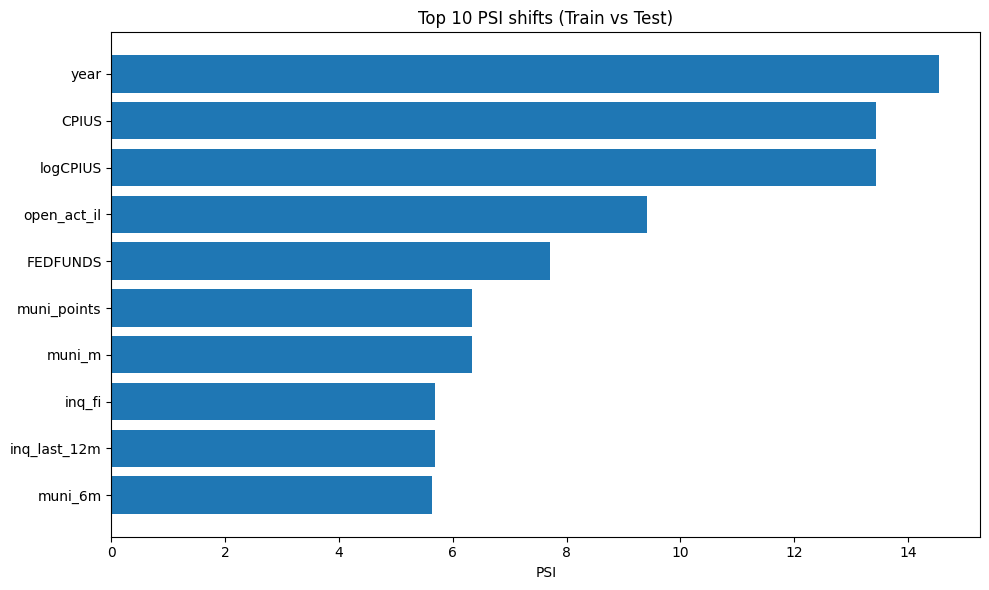

Saved: /content/table_monthly_regime_summary.csv


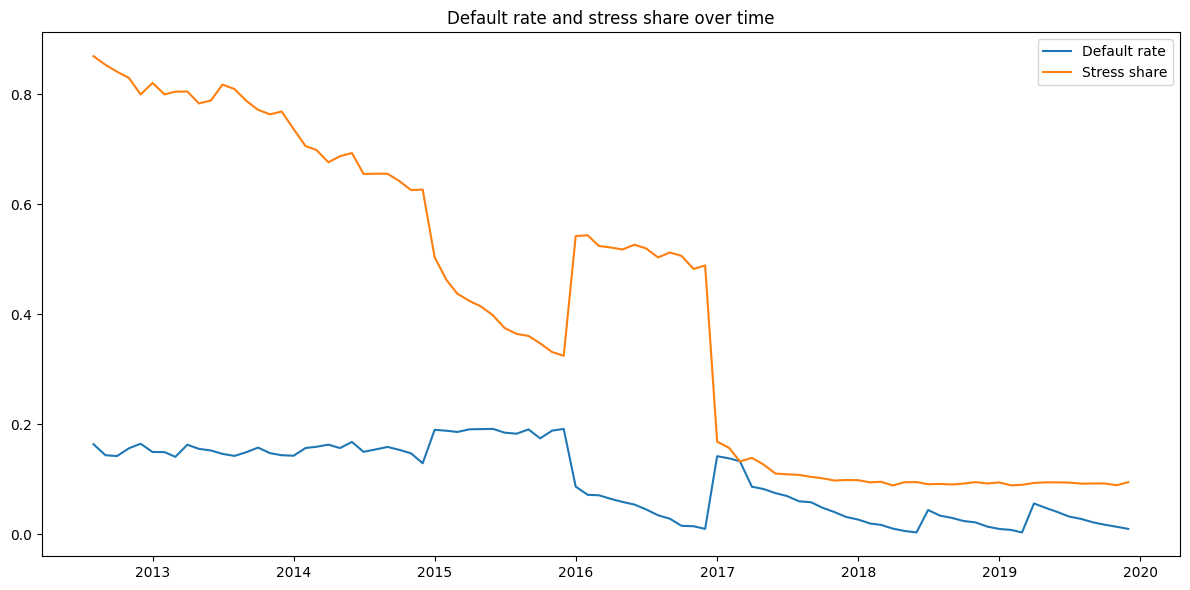

Calibration plot...


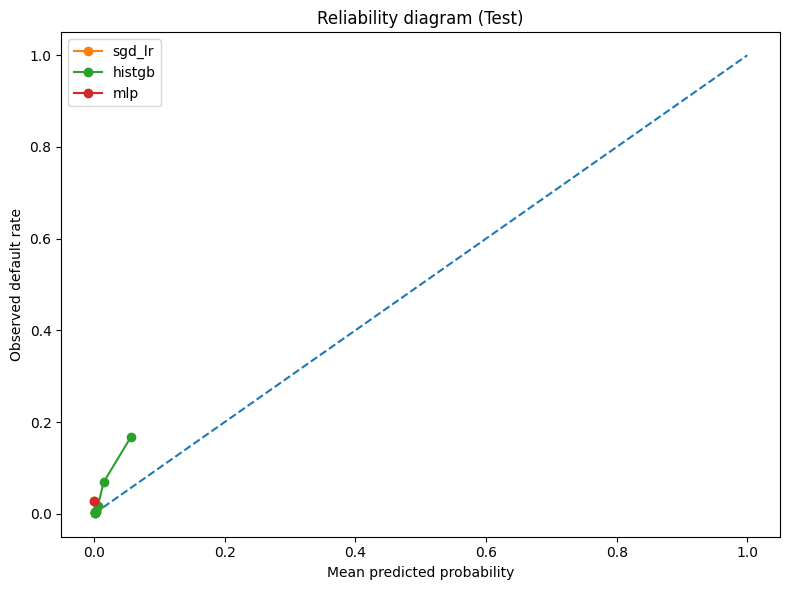

Threshold curves...


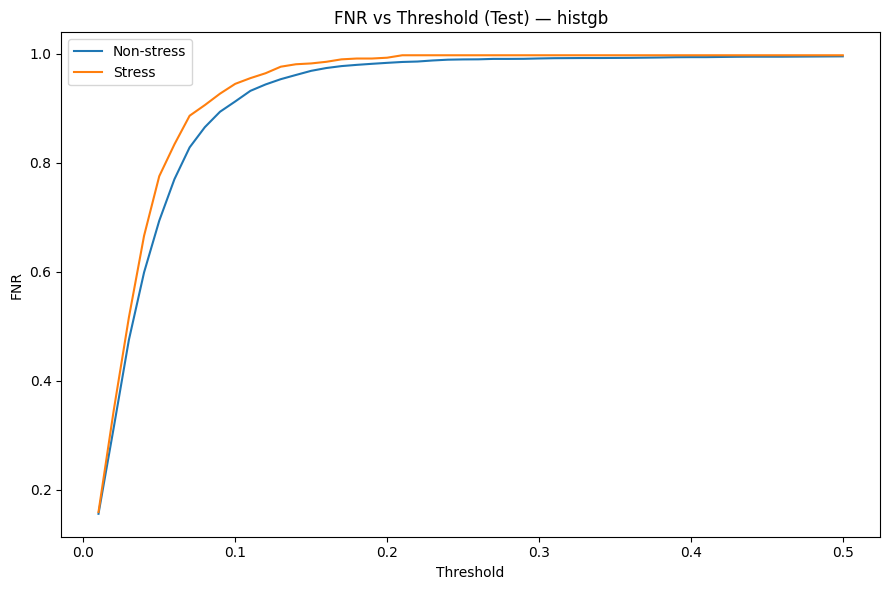

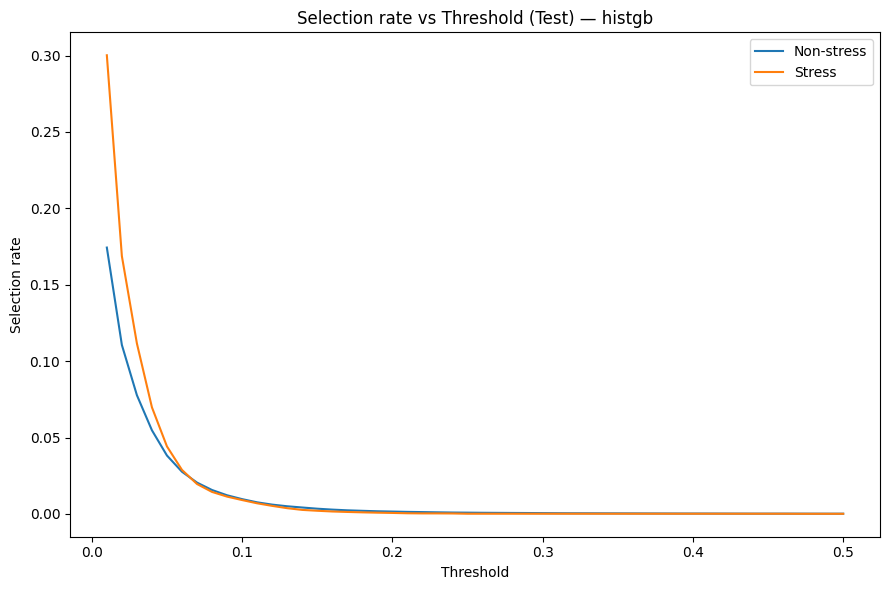

Fairness gaps...

Gap summary:
    group_col      regime   auc_gap   fnr_gap
0      grade  Non-stress  0.014347  0.025466
1      grade      Stress  0.037515  0.013575
2  sub_grade  Non-stress  0.038765  0.045455
3  sub_grade      Stress  0.091725  0.029851
4    purpose  Non-stress  0.043531  0.083333
5    purpose      Stress  0.076750  0.037037


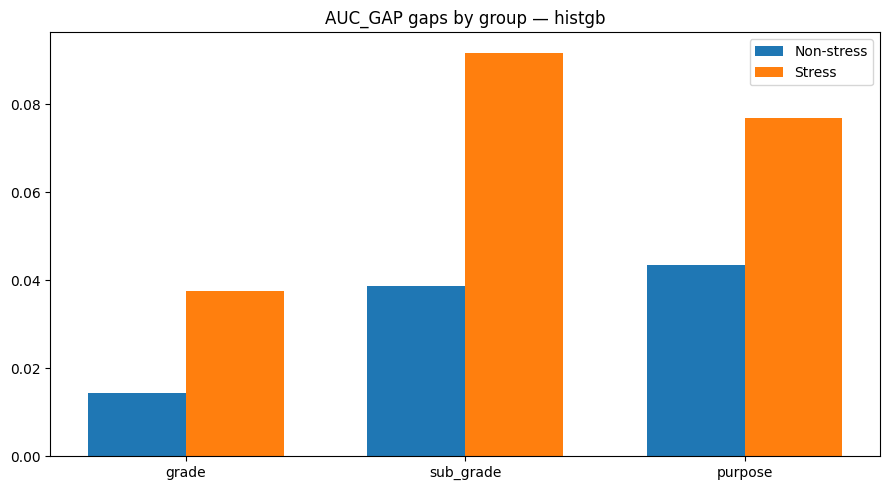

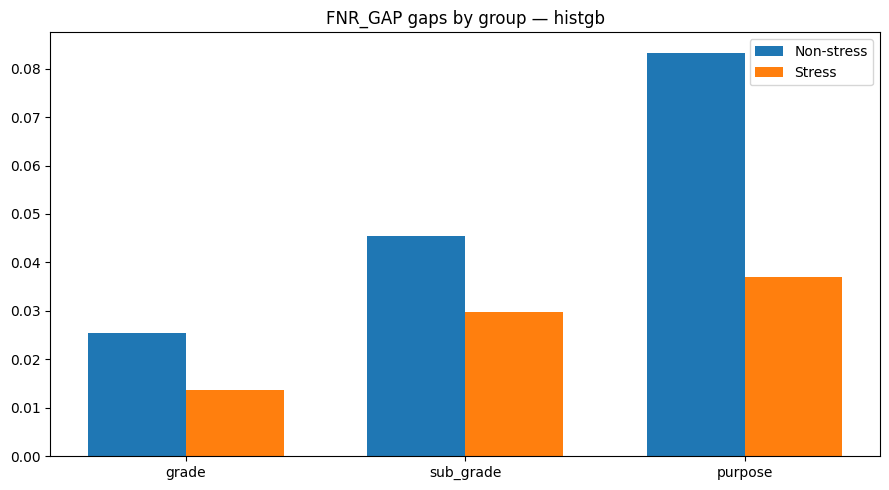

DONE. Figures saved under: /content


In [12]:
# choose main model
MAIN = "histgb" if "histgb" in preds else list(preds.keys())[0]
p_test = preds[MAIN]["test"]

# --- Feature shift helpers (numeric only)
def psi(expected, actual, bins=10):
    expected = pd.Series(expected).dropna()
    actual   = pd.Series(actual).dropna()
    if expected.nunique() < 2 or actual.nunique() < 2:
        return np.nan
    q = np.linspace(0, 1, bins + 1)
    bp = np.unique(expected.quantile(q).values)
    if len(bp) < 3:
        return np.nan
    e = pd.cut(expected, bins=bp, include_lowest=True).value_counts(normalize=True)
    a = pd.cut(actual,   bins=bp, include_lowest=True).value_counts(normalize=True)
    e, a = e.align(a, fill_value=1e-6)
    e = np.clip(e.values, 1e-6, None)
    a = np.clip(a.values, 1e-6, None)
    return np.sum((a - e) * np.log(a / e))

def shift_metrics(df_a, df_b, features, sample_size=50_000):
    if len(df_a) > sample_size:
        df_a = df_a.sample(sample_size, random_state=42)
    if len(df_b) > sample_size:
        df_b = df_b.sample(sample_size, random_state=42)
    rows = []
    for f in features:
        if f not in df_a.columns or f not in df_b.columns:
            continue
        a = df_a[f].values
        b = df_b[f].values
        if np.nanstd(a) == 0 and np.nanstd(b) == 0:
            continue
        ac = pd.Series(a).dropna()
        bc = pd.Series(b).dropna()
        if len(ac) < 50 or len(bc) < 50:
            continue
        ks = ks_2samp(ac, bc).statistic
        wd = wasserstein_distance(ac, bc)
        p  = psi(a, b, bins=10)
        rows.append((f, p, ks, wd))
    out = pd.DataFrame(rows, columns=["feature","psi","ks","wasserstein"])
    return out.sort_values(["psi","ks","wasserstein"], ascending=False)

# numeric features available in sampled frames
num_feats = [c for c in num_cols if c in df_train.columns and c in df_test.columns]

print("Shift plots...")
shift_tt = shift_metrics(df_train, df_test, num_feats).head(10)
plt.figure(figsize=(10,6))
plt.barh(shift_tt["feature"], shift_tt["psi"])
plt.gca().invert_yaxis()
plt.title("Top 10 PSI shifts (Train vs Test)")
plt.xlabel("PSI")
finalize_fig("fig_A1_feature_shift_train_test.png")

# --- Time trends (monthly)
tmp = pd.concat([df_train[[DATE_COL, TARGET_COL, STRESS_COL]],
                 df_val[[DATE_COL, TARGET_COL, STRESS_COL]],
                 df_test[[DATE_COL, TARGET_COL, STRESS_COL]]], axis=0).copy()

tmp["month"] = tmp[DATE_COL].dt.to_period("M").dt.to_timestamp()
monthly = tmp.groupby("month").agg(
    n=(TARGET_COL, "size"),
    default_rate=(TARGET_COL, "mean"),
    stress_share=(STRESS_COL, "mean")
).reset_index()

monthly.to_csv(f"{FIG_DIR}/table_monthly_regime_summary.csv", index=False)
print("Saved:", f"{FIG_DIR}/table_monthly_regime_summary.csv")

plt.figure(figsize=(12,6))
plt.plot(monthly["month"], monthly["default_rate"], label="Default rate")
plt.plot(monthly["month"], monthly["stress_share"], label="Stress share")
plt.legend()
plt.title("Default rate and stress share over time")
finalize_fig("fig_A3_outcome_regime_over_time.png")

# --- Calibration pooled
print("Calibration plot...")
plt.figure(figsize=(8,6))
ax = plt.gca()
ax.plot([0,1],[0,1], linestyle="--")

for name in preds:
    frac_pos, mean_pred = calibration_curve(y_test, preds[name]["test"], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)

ax.set_title("Reliability diagram (Test)")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed default rate")
ax.legend()
finalize_fig("fig_D1_reliability_multi_model_test.png")

# --- Threshold tradeoff by regime (stress vs non-stress)
print("Threshold curves...")
stress = df_test[STRESS_COL].values.astype(int)
idx_ns = stress == 0
idx_s  = stress == 1

THRESHOLDS = np.linspace(0.01, 0.50, 50)

def safety_curve(y_true, p, thresholds):
    rows = []
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    for t in thresholds:
        yhat = (p >= t).astype(int)
        tp = ((yhat==1) & (y_true==1)).sum()
        fp = ((yhat==1) & (y_true==0)).sum()
        fn = ((yhat==0) & (y_true==1)).sum()
        tpr = tp/(tp+fn) if (tp+fn) else np.nan
        fnr = 1-tpr if not np.isnan(tpr) else np.nan
        sel = yhat.mean()
        prec = tp/(tp+fp) if (tp+fp) else np.nan
        rows.append((t, fnr, sel, prec))
    return pd.DataFrame(rows, columns=["threshold","fnr","selection","precision"])

cur_ns = safety_curve(y_test[idx_ns], p_test[idx_ns], THRESHOLDS)
cur_s  = safety_curve(y_test[idx_s],  p_test[idx_s],  THRESHOLDS)

plt.figure(figsize=(9,6))
plt.plot(cur_ns["threshold"], cur_ns["fnr"], label="Non-stress")
plt.plot(cur_s["threshold"],  cur_s["fnr"],  label="Stress")
plt.title(f"FNR vs Threshold (Test) — {MAIN}")
plt.xlabel("Threshold")
plt.ylabel("FNR")
plt.legend()
finalize_fig("fig_C1_fnr_vs_threshold.png")

plt.figure(figsize=(9,6))
plt.plot(cur_ns["threshold"], cur_ns["selection"], label="Non-stress")
plt.plot(cur_s["threshold"],  cur_s["selection"],  label="Stress")
plt.title(f"Selection rate vs Threshold (Test) — {MAIN}")
plt.xlabel("Threshold")
plt.ylabel("Selection rate")
plt.legend()
finalize_fig("fig_C2_selection_vs_threshold.png")

# --- Fairness gaps (AUC gap + FNR gap)
print("Fairness gaps...")

def group_gap_metrics(y_true, pred, groups, tau=0.20, min_n=1000):
    groups = np.asarray(groups)
    y_true = np.asarray(y_true).astype(int)
    pred   = np.asarray(pred).astype(float)
    uniq = pd.unique(pd.Series(groups).dropna())
    rows = []
    for g in uniq:
        m = (groups == g)
        if m.sum() < min_n:
            continue
        yg = y_true[m]
        pg = pred[m]
        if np.unique(yg).size < 2:
            continue
        auc = roc_auc_score(yg, pg)
        yhat = (pg >= tau).astype(int)
        tp = ((yhat==1) & (yg==1)).sum()
        fn = ((yhat==0) & (yg==1)).sum()
        tpr = tp/(tp+fn) if (tp+fn) else np.nan
        fnr = 1-tpr if not np.isnan(tpr) else np.nan
        rows.append((g, m.sum(), auc, fnr))
    if not rows:
        return None
    mdf = pd.DataFrame(rows, columns=["group","n","auc","fnr"])
    return (mdf["auc"].max()-mdf["auc"].min(),
            mdf["fnr"].max()-mdf["fnr"].min())

gap_rows = []
for gcol in GROUP_COLS:
    if gcol not in df_test.columns:
        continue
    for regime_name, idx in [("Non-stress", idx_ns), ("Stress", idx_s)]:
        res = group_gap_metrics(y_test[idx], p_test[idx], df_test[gcol].astype("object").values[idx], tau=0.20, min_n=1000)
        if res is None:
            continue
        gap_rows.append((gcol, regime_name, res[0], res[1]))

gaps = pd.DataFrame(gap_rows, columns=["group_col","regime","auc_gap","fnr_gap"])
print("\nGap summary:\n", gaps)

for metric in ["auc_gap","fnr_gap"]:
    plt.figure(figsize=(9,5))
    x = np.arange(len(GROUP_COLS))
    ns_vals, s_vals = [], []
    for g in GROUP_COLS:
        a = gaps[(gaps["group_col"]==g) & (gaps["regime"]=="Non-stress")][metric]
        b = gaps[(gaps["group_col"]==g) & (gaps["regime"]=="Stress")][metric]
        ns_vals.append(float(a.values[0]) if len(a) else 0.0)
        s_vals.append(float(b.values[0]) if len(b) else 0.0)
    w = 0.35
    plt.bar(x-w/2, ns_vals, w, label="Non-stress")
    plt.bar(x+w/2, s_vals,  w, label="Stress")
    plt.xticks(x, GROUP_COLS)
    plt.title(f"{metric.upper()} gaps by group — {MAIN}")
    plt.legend()
    finalize_fig(f"fig_E_{metric}_gaps.png")

print("DONE. Figures saved under:", FIG_DIR)